
# Route Intelligence · Equipo 42
Evaluación complementaria de los modelos de estimación de tiempos de viaje

**Proyecto Integrador | Maestría en Inteligencia Artificial Aplicada**

Esta libreta complementa los resultados obtenidos en el desarrollo del Proyecto Integrador *Planeación inteligente de rutas ante interrupciones mediante técnicas de optimización e inteligencia artificial*. Su propósito es profundizar en la evaluación de los modelos desarrollados, particularmente en la interpretación de sus errores y en la calidad de las matrices de tiempos origen-destino (OD) que pueden proporcionar al modelo de optimización.

En particular, se considera el hecho de que un error absoluto expresado en segundos puede ser insuficiente para valorar adecuadamente el desempeño de un modelo si se desconoce la duración de los trayectos que se están estimando. Por ello, se abordan métricas relativas, análisis por duración y condiciones de circulación, así como comparaciones visuales entre los tiempos de referencia y los estimados.

Se consideran los dos componentes desarrollados durante el Proyecto:

| Componente | Momento de decisión | Información disponible | Modelos evaluados |
|---|---|---|---|
| **I. Planeación anticipada** | Antes de la jornada siguiente | Información histórica disponible al emitir el pronóstico | M1 frente a la referencia histórica M0 |
| **II. Reconstrucción contemporánea** | Durante la operación | Información histórica y 32 consultas OD guía simuladas | Ridge K=32 frente a la referencia histórica K=0 |

Cabe señalar que ambos componentes permiten construir matrices de tiempos de viaje, aunque responden a necesidades distintas y se evalúan mediante protocolos independientes.

Los tiempos de referencia se obtienen a partir de las velocidades históricas de PeMS-BAY y de la red experimental construida durante el proyecto. No corresponden a mediciones independientes de recorridos completos. Asimismo, la generación de matrices OD no implica que se haya realizado ya una integración funcional con el optimizador de Berth y Trigos.

**Organización de la libreta:** caracterización de la red y escala de los tiempos; evaluación de la planeación anticipada; evaluación de la reconstrucción contemporánea; síntesis de resultados; y generación de matrices OD para una posible integración experimental.

### Datos, horizonte temporal y procedimiento de evaluación

El análisis utiliza la red experimental construida durante los avances anteriores a partir de **PeMS-BAY**, un conjunto de datos que contiene mediciones históricas de velocidad registradas por sensores de autopistas del Área de la Bahía de San Francisco. Estas observaciones, correspondientes al periodo enero-junio de 2017, permiten caracterizar la variación del tráfico a lo largo del tiempo.

La red experimental comprende **322 nodos y 345 aristas dirigidas**. De estas últimas, 273 representan conexiones entre sensores de un mismo corredor y 72 corresponden a enlaces auxiliares utilizados para representar intercambios entre corredores. La red incluye, además, **13 macronodos de intercambio**, que permiten representar las conexiones entre los distintos corredores.

Los dos componentes desarrollados durante el Proyecto buscan estimar los tiempos de recorrido de las aristas de esta red. A partir de dichas estimaciones, y mediante algoritmos de caminos mínimos, es posible construir matrices de tiempos origen-destino (OD) para distintos conjuntos de nodos seleccionados. De esta manera, los modelos pueden proporcionar información temporal para diferentes configuraciones de puntos de origen y destino dentro de la red experimental.

Aunque comparten este procedimiento para construir las matrices OD, **los componentes responden a momentos de decisión diferentes y utilizan información distinta**:

- **Componente I. Planeación anticipada:** tiene como propósito estimar los tiempos de desplazamiento de la jornada siguiente utilizando información disponible antes de su inicio. El modelo M1 incorpora información histórica reciente y características temporales, mientras que M0 constituye la referencia basada en patrones históricos. La evaluación considera las predicciones de junio de 2017, generadas para intervalos de cinco minutos entre las 08:00 y las 15:55. Para la evaluación OD se utilizan ocho cortes horarios por jornada, correspondientes a las 08:00, 09:00, ..., 15:00. La formulación y evaluación originales se presentan en el **Avance 6**.

- **Componente II. Reconstrucción contemporánea:** tiene como propósito actualizar las estimaciones de tiempos de desplazamiento a partir de información limitada sobre las condiciones de circulación del momento. El modelo Ridge K=32 utiliza 32 consultas OD guía simuladas para estimar los tiempos de las aristas, mientras que K=0 constituye la referencia basada exclusivamente en información histórica. La formulación y evaluación originales se presentan en el **Avance 4**.

Para esta evaluación complementaria se seleccionan los **13 macronodos de intercambio como conjunto común de orígenes y destinos**, lo que permite examinar los resultados de ambos componentes sobre una misma selección de nodos y preparar la exportación de matrices OD con una estructura uniforme. Esta elección no limita la aplicación de los procedimientos a dichos macronodos, ya que la red experimental es fuertemente conexa y las estimaciones de tiempos por arista permiten construir matrices OD para cualquier conjunto de sus nodos.

En ambos componentes, los tiempos de referencia se calculan a partir de las velocidades históricas registradas en PeMS-BAY y de la red experimental construida durante el Proyecto. Las evaluaciones contrastan las estimaciones de los modelos con estos tiempos de referencia, de acuerdo con los procedimientos correspondientes a cada componente.

**Procedimiento de ejecución.** La libreta utiliza el conjunto de datos routing_dataset_v1, almacenado en Google Drive, cuya metodología de construcción se documenta en el Avance 3. Para el componente I, reproduce el entrenamiento de M1 y genera sus predicciones conforme a la metodología del Avance 6. Para el componente II, recupera las predicciones previamente obtenidas en el Avance 4. En ambos casos, los tiempos de viaje se convierten a segundos para presentar las métricas de evaluación.

Los resultados complementarios, figuras y matrices OD se guardan en una carpeta independiente dentro de Google Drive, sin modificar los datos ni los resultados originales.


In [1]:
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from IPython.display import display, Markdown
from google.colab import drive

drive.mount('/content/drive')

RAIZ_DRIVE = Path('/content/drive/MyDrive/Route Intelligence')
DATA_DIR = RAIZ_DRIVE / 'routing_dataset_v1'
# Resultados de la ejecución final del Avance 4,
# utilizados para reproducir la evaluación de K=32.
EJECUCION_AVANCE4 = 'ejecucion_20261025_165925_885935'
A4_DIR = RAIZ_DRIVE / 'avance4_reconstruccion_red_k32_ejecuciones' / EJECUCION_AVANCE4

OUT = Path('/content/resultados_auxiliares_v5')
FIG = OUT / 'figuras'
EXPORT = OUT / 'matrices_para_optimizacion'
DRIVE_OUT = RAIZ_DRIVE / 'resultados_auxiliares_v5'
for ruta in (FIG, EXPORT):
    ruta.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.18,
                     'axes.spines.top': False, 'axes.spines.right': False})
SEED = 20261112
rng = np.random.default_rng(SEED)
print('Red experimental:', DATA_DIR)
print('Ejecución Avance 4:', A4_DIR)
print('Resultados auxiliares en Drive (al concluir):', DRIVE_OUT)

Mounted at /content/drive
Red experimental: /content/drive/MyDrive/Route Intelligence/routing_dataset_v1
Ejecución Avance 4: /content/drive/MyDrive/Route Intelligence/avance4_reconstruccion_red_k32_ejecuciones/ejecucion_20261025_165925_885935
Resultados auxiliares en Drive (al concluir): /content/drive/MyDrive/Route Intelligence/resultados_auxiliares_v5


### Carga de la red experimental

Se recuperan los archivos que describen la red experimental: el catálogo de nodos (`nodes.csv`), el catálogo de aristas dirigidas (`edges.csv`) y las series temporales de tiempos de recorrido (`edge_travel_times.parquet`), registradas con una frecuencia nominal de cinco minutos.

Las columnas de tiempos se organizan siguiendo el orden de las aristas en `edges.csv`, de modo que cada valor corresponda a la conexión correcta. Esta correspondencia es necesaria tanto para evaluar los modelos como para calcular las matrices de tiempos origen-destino.

Los tiempos de recorrido se mantienen en minutos durante el procesamiento y se convierten a segundos cuando corresponde presentar los errores absolutos.


In [2]:
nodes = pd.read_csv(DATA_DIR / 'nodes.csv', dtype={'node_id': str})
edges = pd.read_csv(DATA_DIR / 'edges.csv', dtype={'edge_id': str, 'from': str, 'to': str})
ids_arista = edges['edge_id'].astype(str).tolist()

raw = pd.read_parquet(DATA_DIR / 'edge_travel_times.parquet')
if 'timestamp' in raw.columns:
    t = raw.pop('timestamp')
    raw.index = pd.to_datetime(t, unit='ns' if pd.api.types.is_integer_dtype(t) else None)
else:
    raw.index = pd.to_datetime(raw.index)
Y = raw.reindex(columns=ids_arista).sort_index().astype('float32')

# Verificar la correspondencia entre aristas y tiempos de recorrido.
assert not edges.duplicated(['from','to']).any(), 'Conexiones dirigidas duplicadas en edges.csv.'
if Y.isna().any().any() or len(ids_arista) != Y.shape[1]:
    raise ValueError('Las columnas de tiempos deben corresponder a las aristas de edges.csv.')
mask_corr = (edges.edge_type == 'corridor').to_numpy()
print(f'{len(nodes)} nodos; {len(edges)} aristas; {len(Y):,} instantes de cinco minutos.')
print(f'Cobertura: {Y.index.min()} — {Y.index.max()}. Unidad fuente: minutos.')

322 nodos; 345 aristas; 52,116 instantes de cinco minutos.
Cobertura: 2017-01-01 00:00:00 — 2017-06-30 23:55:00. Unidad fuente: minutos.


## A. Escala de los tiempos y estado general de la red

La interpretación de los errores requiere considerar la duración de los desplazamientos estimados. Por ejemplo, un error absoluto de tres segundos tiene una importancia relativa distinta para un recorrido de 30 segundos que para uno de 15 minutos.

Por ello, comenzamos caracterizando las duraciones de las aristas y las condiciones generales de circulación de la red. Posteriormente, evaluamos los modelos mediante métricas que permiten examinar tanto la magnitud absoluta de los errores como su importancia relativa respecto de los tiempos de referencia.

La principal métrica relativa es el **WAPE** (*error porcentual absoluto ponderado*), definido como la suma de los errores absolutos dividida entre la suma de los tiempos de referencia. Este indicador expresa el error agregado como porcentaje de la duración total evaluada, aunque no representa el promedio de los errores porcentuales individuales.

Para complementar esta información, utilizamos las siguientes métricas:

| Métrica | Interpretación |
|---|---|
| **WAPE (%)** | Error absoluto agregado respecto de la suma de los tiempos de referencia. |
| **MAE (s)** | Magnitud promedio del error absoluto, expresada en segundos. |
| **MdAPE (%)** | Mediana de los errores porcentuales absolutos individuales; caracteriza el error relativo típico. |
| **P95 del error absoluto (s)** | Valor por debajo del cual se encuentra el 95 % de los errores absolutos. |
| **Sesgo medio (s)** | Diferencia promedio entre el tiempo estimado y el de referencia; los valores negativos indican una tendencia a subestimar. |
| **Subestimación (%)** | Porcentaje de observaciones en las que el tiempo estimado es inferior al de referencia. |

En particular, el WAPE y el MAE se calculan como:

$$
\mathrm{WAPE}=100\frac{\sum_i |\widehat{t}_i-t_i|}{\sum_i t_i},
\qquad
\mathrm{MAE}=\frac{1}{n}\sum_i |\widehat{t}_i-t_i|.
$$

donde $t_i$ representa el tiempo de referencia y $\widehat{t}_i$ el tiempo estimado. Para presentar el MAE en segundos, los tiempos utilizados en su cálculo se expresan en esa unidad.

Se presta especial atención a las subestimaciones por sus posibles implicaciones para el cumplimiento de las ventanas de tiempo en un problema de ruteo. Las sobrestimaciones también pueden afectar la eficiencia de las soluciones, aunque estos efectos no se evalúan directamente en la presente libreta.

Adicionalmente, analizamos los errores según la **duración histórica de las aristas y los pares OD**, clasificándolos en tres grupos: cortos, intermedios y largos. La clasificación se establece mediante terciles de las duraciones históricas calculadas con información de enero a marzo de 2017, anterior al periodo de evaluación, para evitar definir los grupos a partir de los resultados observados en junio.

Finalmente, distinguimos las aristas de corredor de las conexiones auxiliares, ya que estas últimas representan aproximaciones de los intercambios entre corredores. Para evaluar las matrices OD se consideran únicamente los pares de nodos distintos, excluyendo los elementos diagonales, cuyo tiempo de recorrido es cero.

In [3]:
def metricas(y_true_min, y_pred_min, grupo='total'):
    """Calcula métricas de error a partir de tiempos expresados en minutos."""
    a = np.asarray(y_true_min, dtype=float).ravel()
    b = np.asarray(y_pred_min, dtype=float).ravel()

    if (a.shape != b.shape or
        not np.isfinite(a).all() or
        not np.isfinite(b).all() or
        (a <= 0).any() or
        (b <= 0).any()):
        raise ValueError('Medidas desalineadas, no finitas o no positivas')

    e = b - a
    pe = 100 * np.abs(e) / a

    return {
        'grupo': grupo,
        'N': len(a),
        'real_media_s': 60 * a.mean(),
        'real_mediana_s': 60 * np.median(a),
        'MAE_s': 60 * np.abs(e).mean(),
        'WAPE_pct': 100 * np.abs(e).sum() / a.sum(),
        'MdAPE_pct': np.median(pe),
        'P95_error_s': 60 * np.percentile(np.abs(e), 95),
        'sesgo_medio_s': 60 * e.mean(),
        'subestimacion_pct': 100 * np.mean(e < 0)
    }

In [4]:

# Índices de nodos y aristas para construir el grafo dirigido.
node_ids = nodes.node_id.astype(str).tolist()
node_idx = {node: i for i, node in enumerate(node_ids)}
_edge_rows = edges['from'].map(node_idx).to_numpy(dtype=int)
_edge_cols = edges['to'].map(node_idx).to_numpy(dtype=int)
macro_ids = sorted(
    nodes.loc[nodes.node_type == 'interchange', 'node_id']
    .astype(str).tolist()
)

def od_matriz(pesos_min, seleccion=None):
    """Calcula una matriz OD para los nodos seleccionados."""
    if seleccion is None:
        seleccion = macro_ids

    pesos = np.asarray(pesos_min, dtype=float)
    assert pesos.shape == (len(edges),) and np.isfinite(pesos).all() and (pesos > 0).all()

    g = csr_matrix(
        (pesos, (_edge_rows, _edge_cols)),
        shape=(len(node_ids), len(node_ids))
    )
    ids = np.asarray([node_idx[str(x)] for x in seleccion], dtype=int)

    # Caminos mínimos con tiempos de arista fijos en el instante evaluado (snapshot).
    dist = dijkstra(g, directed=True, indices=ids)[:, ids]

    assert dist.shape == (len(ids), len(ids)) and np.isfinite(dist).all()
    assert np.allclose(np.diag(dist), 0)
    return dist


# Coordenadas para visualización: se separan ligeramente los sentidos opuestos.
# Este desplazamiento no modifica la topología ni los tiempos de recorrido.
positions = {
    str(r.node_id): np.array([float(r.longitude), float(r.latitude)])
    for r in nodes.itertuples()
}
lon_span = float(nodes.longitude.max() - nodes.longitude.min())
lat_span = float(nodes.latitude.max() - nodes.latitude.min())

for r in nodes.loc[nodes.node_type == 'sensor'].itertuples():
    d = str(r.corridor).split('-')[-1]
    if d == 'N': positions[str(r.node_id)][0] += .008 * lon_span
    if d == 'S': positions[str(r.node_id)][0] -= .008 * lon_span
    if d == 'E': positions[str(r.node_id)][1] -= .008 * lat_span
    if d == 'W': positions[str(r.node_id)][1] += .008 * lat_span

segments = np.array([
    [positions[str(a)], positions[str(b)]]
    for a, b in zip(edges['from'], edges['to'])
])
macro_xy = np.stack([positions[str(x)] for x in macro_ids])
mean_lat = float(nodes.latitude.mean())


def pintar_red(ax, valores, title, cmap, norm):
    # Líneas continuas: aristas de corredor; punteadas: conexiones auxiliares.
    for mascara, lw, ls in [
        (mask_corr, 2.3, 'solid'),
        (~mask_corr, 1.2, 'dashed')
    ]:
        lin = LineCollection(
            segments[mascara], cmap=cmap, norm=norm,
            linewidths=lw, linestyles=ls, alpha=.96
        )
        lin.set_array(np.asarray(valores)[mascara])
        ax.add_collection(lin)

    # Las cruces identifican los macronodos de intercambio.
    ax.scatter(macro_xy[:, 0], macro_xy[:, 1],
               marker='x', c='black', s=15, zorder=6)

    ax.autoscale()
    ax.set_aspect(1 / np.cos(np.deg2rad(mean_lat)))
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    return lin


def velocidad_eq(tiempos_min):
    """Velocidad equivalente en km/h a partir de distancia y tiempo estimado."""
    return (
        60 * edges.distance_km.to_numpy(dtype=float)
        / np.asarray(tiempos_min, dtype=float)
    )


def graficar_matriz_od(referencia, historico, pred, modelo,
                      instante, figura, etiquetas_nodos=None):

    refs = np.asarray(referencia)
    base = np.asarray(historico)
    model = np.asarray(pred)
    assert refs.shape == base.shape == model.shape

    nodos = refs.shape[0]
    etiquetas = (
        list(etiquetas_nodos)
        if etiquetas_nodos is not None
        else (macro_ids if nodos == 13 else [str(i + 1) for i in range(nodos)])
    )

    # Escala común para comparar los tres conjuntos de tiempos OD.
    nivel = float(max(refs.max(), base.max(), model.max()))
    fig, axs = plt.subplots(1, 4, figsize=(18, 5.2), constrained_layout=True)

    for ax, z, titulo in zip(
        axs[:3],
        [refs, base, model],
        ['Referencia experimental', 'Referencia histórica', modelo]
    ):
        im = ax.imshow(z, cmap='viridis', vmin=0, vmax=nivel)
        ax.set_title(titulo)
        ax.set_xticks(range(nodos), etiquetas, rotation=90, fontsize=6)
        ax.set_yticks(range(nodos), etiquetas, fontsize=6)

    fig.colorbar(im, ax=axs[:3], shrink=.7, label='Tiempo OD (min)')

    # Cuarta matriz: magnitud del error del modelo respecto de la referencia.
    delta = 60 * np.abs(model - refs)
    er = axs[3].imshow(delta, cmap='magma', vmin=0)
    axs[3].set_title('Error absoluto ' + modelo + ' (s)')
    axs[3].set_xticks(range(nodos), etiquetas, rotation=90, fontsize=6)
    axs[3].set_yticks(range(nodos), etiquetas, fontsize=6)

    fig.colorbar(er, ax=axs[3], shrink=.7, label='Error (s)')
    fig.suptitle(f'{modelo}: matrices OD dirigidas · {instante}')
    fig.savefig(FIG / figura, dpi=175, bbox_inches='tight')
    plt.show()


### A.1. ¿Cuánto tarda una arista?

Para contextualizar la magnitud de los errores de estimación, comenzamos examinando la duración de los recorridos asociados con las aristas de la red experimental.

Se calculan estadísticas descriptivas de los tiempos registrados durante junio de 2017, considerando tanto el día completo como la ventana de **08:00 a 15:55**, correspondiente al horizonte de evaluación del componente I. Esta distinción permite identificar posibles diferencias en la duración de los desplazamientos según el periodo del día. Asimismo, se presentan resultados separados para las aristas de corredor y los enlaces auxiliares.

Como complemento, se examina la distribución de las duraciones de las aristas durante la ventana analizada. Para ello, cada arista se representa mediante la mediana de sus tiempos de recorrido, de manera que el histograma refleje las diferencias entre conexiones sin repetir sus observaciones temporales.

Este análisis permite establecer una escala de referencia para interpretar posteriormente los errores absolutos de los modelos y reconocer la heterogeneidad de los tiempos de desplazamiento dentro de la red.

,muestra,N,media_s,mediana_s,P10_s,P90_s
0,Junio completo · todas las aristas,2980800,29.08,22.24,5.13,61.79
1,08:00–15:55 · todas las aristas,993600,30.28,23.11,5.30,65.04
2,08:00–15:55 · corredores,786240,32.36,25.73,8.12,66.48
3,08:00–15:55 · enlaces auxiliares,207360,22.42,15.13,2.12,56.52


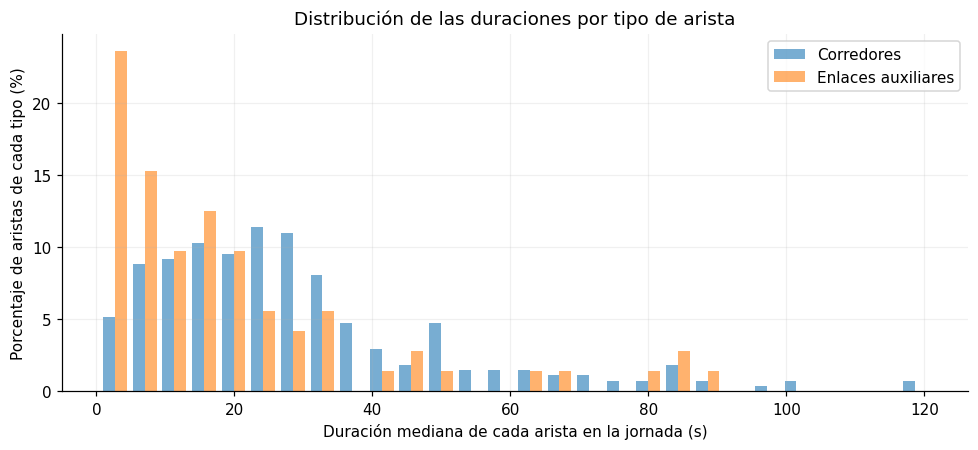

In [5]:
# Duración de las aristas en junio completo y durante la jornada analizada.
mask_corr = (edges.edge_type == 'corridor').to_numpy()

def duraciones(z, etiqueta):
    """Estadísticas de tiempos por arista e instante, expresadas en segundos."""
    v = np.asarray(z, dtype=float).ravel() * 60
    return {
        'muestra': etiqueta,
        'N': len(v),
        'media_s': v.mean(),
        'mediana_s': np.median(v),
        'P10_s': np.quantile(v, .10),
        'P90_s': np.quantile(v, .90)
    }


# Periodos de análisis y estadísticas descriptivas.
mes = Y.loc['2017-06-01':'2017-06-30 23:55:00']
turno = mes.between_time('08:00', '15:55')

duracion = pd.DataFrame([
    duraciones(mes.to_numpy(), 'Junio completo · todas las aristas'),
    duraciones(turno.to_numpy(), '08:00–15:55 · todas las aristas'),
    duraciones(turno.iloc[:, mask_corr], '08:00–15:55 · corredores'),
    duraciones(turno.iloc[:, ~mask_corr], '08:00–15:55 · enlaces auxiliares')
])

display(duracion.round(2))
duracion.to_csv(OUT / 'duracion_aristas.csv', index=False)


# Cada arista aporta una observación: su duración mediana durante la jornada.
x_corr = turno.iloc[:, mask_corr].median().to_numpy() * 60
x_aux = turno.iloc[:, ~mask_corr].median().to_numpy() * 60

# Intervalos comunes y porcentajes calculados dentro de cada categoría.
bins = np.histogram_bin_edges(
    np.concatenate([x_corr, x_aux]), bins=28
)

fig, ax = plt.subplots(figsize=(9, 4.2))

ax.hist(
    [x_corr, x_aux],
    bins=bins,
    weights=[
        np.full(len(x_corr), 100 / len(x_corr)),
        np.full(len(x_aux), 100 / len(x_aux))
    ],
    alpha=.6,
    label=['Corredores', 'Enlaces auxiliares']
)

ax.set(
    xlabel='Duración mediana de cada arista en la jornada (s)',
    ylabel='Porcentaje de aristas de cada tipo (%)',
    title='Distribución de las duraciones por tipo de arista'
)
ax.legend()
fig.tight_layout()
fig.savefig(FIG / '01_duracion_aristas.png', dpi=160)
plt.show()


# Interpretación de los resultados descriptivos.
media_total = float(duracion.iloc[0]['media_s'])
media_turno = float(duracion.iloc[1]['media_s'])
media_corr = float(duracion.iloc[2]['media_s'])
media_aux = float(duracion.iloc[3]['media_s'])

**Interpretación de resultados**

Durante junio de 2017, el tiempo de recorrido de las aristas de la red experimental presenta una media de **29.08 segundos**, que aumenta ligeramente a **30.28 segundos** al considerar exclusivamente la ventana de 08:00 a 15:55. En esta última, la mediana es de **23.11 segundos**, inferior a la media, lo que refleja la presencia de conexiones con duraciones relativamente elevadas.

Al distinguir entre tipos de aristas, se observa que las conexiones de corredor tienen una duración media de **32.36 segundos**, frente a **22.42 segundos** para los enlaces auxiliares. El histograma complementa esta comparación al mostrar la distribución de la duración mediana de cada arista durante la jornada analizada.

Estos resultados permiten establecer la escala temporal de las conexiones que conforman la red. Sin embargo, **la duración de una arista individual no debe confundirse con la de un recorrido origen-destino (OD)**, que puede comprender varias aristas y cuyo tiempo se determina mediante el cálculo de caminos mínimos.

Esta distinción es importante para interpretar los errores de los modelos. Un mismo error absoluto puede representar una proporción considerable del tiempo de una arista corta y una proporción mucho menor del tiempo de un recorrido OD de varios minutos. Por ello, las evaluaciones posteriores examinan por separado los errores de estimación por arista y los correspondientes a las matrices OD, utilizando tanto métricas absolutas como relativas.

### A.2. ¿Cuándo cambia el estado agregado de la red?

Para examinar cómo varían las condiciones de circulación a lo largo del tiempo, construimos un indicador que resume las velocidades de desplazamiento en la red experimental. En cada instante, calculamos la **velocidad equivalente de cada arista de corredor** a partir de su longitud y tiempo de recorrido. Después, obtenemos el promedio de estas velocidades, de manera que cada instante queda representado por un único valor que sintetiza las condiciones generales de la red.

La siguiente figura muestra cómo varía este indicador durante junio de 2017, agrupando las observaciones por día de la semana y hora. Esta representación permite identificar en qué horarios y días se registran velocidades relativamente mayores o menores, así como reconocer posibles patrones temporales en las condiciones de circulación.

El indicador proporciona una visión general del comportamiento de la red, relevante para ambos componentes del Proyecto. No obstante, al tratarse de un promedio, puede ocultar diferencias entre corredores o conexiones individuales. Por ello, los análisis posteriores también consideran los tiempos de recorrido y los errores de estimación a un nivel más desagregado.

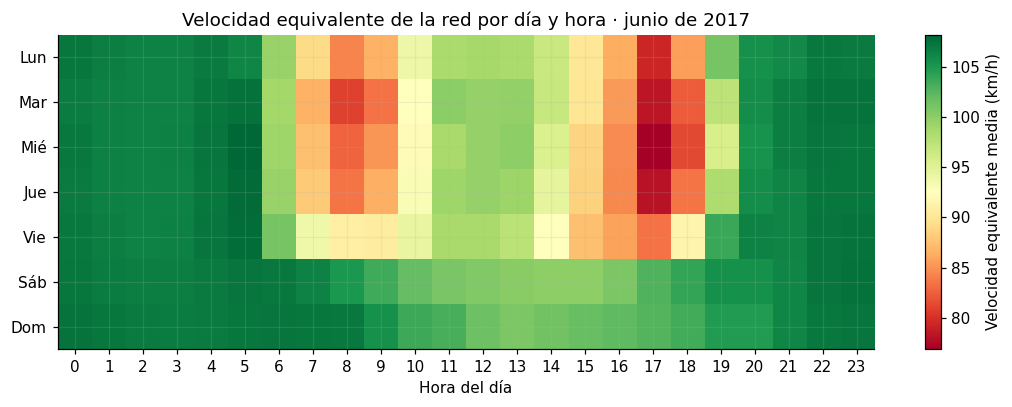

In [6]:

# Estado agregado de la red durante junio de 2017.
# Se consideran exclusivamente las aristas de corredor.
distancias = edges.loc[mask_corr, 'distance_km'].to_numpy(dtype=float)
tiempos = mes.iloc[:, mask_corr].to_numpy(dtype=float)

# Velocidad equivalente por arista e instante (km/h).
vel_c = 60 * distancias[None, :] / tiempos

# Promedio simple de velocidades entre las aristas de corredor.
vel_inst = vel_c.mean(axis=1)

# Perfil medio por día de la semana y hora.
perfil = pd.DataFrame({
    'dia_semana': mes.index.dayofweek,
    'hora': mes.index.hour,
    'velocidad_equivalente_kmh': vel_inst
})

matriz = perfil.pivot_table(
    index='dia_semana',
    columns='hora',
    values='velocidad_equivalente_kmh',
    aggfunc='mean'
)

# Mapa de calor del comportamiento temporal de la red.
fig, ax = plt.subplots(figsize=(10, 3.8))

im = ax.imshow(
    matriz.to_numpy(),
    cmap='RdYlGn',
    aspect='auto'
)

ax.set_xticks(np.arange(24), np.arange(24))
ax.set_yticks(
    np.arange(7),
    ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
)

ax.set(
    xlabel='Hora del día',
    title='Velocidad equivalente de la red por día y hora · junio de 2017'
)

fig.colorbar(
    im, ax=ax,
    label='Velocidad equivalente media (km/h)'
)

fig.tight_layout()
fig.savefig(FIG / '02_estado_red_por_hora.png', dpi=160)
plt.show()

matriz.to_csv(OUT / 'estado_red_por_hora.csv')


**Interpretación de resultados**

La figura muestra diferencias claras en las velocidades equivalentes de la red experimental según el día de la semana y la hora. Durante los días laborales se identifican dos periodos de reducción de velocidad: uno por la mañana, entre las 07:00 y las 09:00, particularmente de martes a jueves, y otro por la tarde, entre las 16:00 y las 18:00. En contraste, durante los fines de semana las velocidades presentan un comportamiento más uniforme, mientras que en los horarios nocturnos se mantienen relativamente elevadas.

Estas variaciones ponen de manifiesto la existencia de patrones temporales en las condiciones de circulación y permiten contextualizar la importancia de incorporar información sobre el día y la hora al estimar los tiempos de desplazamiento. Cabe señalar que la figura comprende el día completo, mientras que la evaluación del componente I se concentra en la ventana de 08:00 a 15:55.

Aunque el indicador permite caracterizar el comportamiento general de la red, no refleja necesariamente las condiciones particulares de todas sus conexiones. Por ello, los análisis posteriores examinan los tiempos de recorrido y los errores de estimación con mayor detalle.

## I. Planeación anticipada: estimación de tiempos para la jornada siguiente (Avance 6)

### I.1. De una referencia histórica a un pronóstico informado

El primer componente busca estimar los tiempos de desplazamiento de una jornada utilizando exclusivamente información disponible antes de su inicio. La pregunta que orienta este análisis es si **un modelo previamente entrenado, que incorpora observaciones recientes de tráfico y características temporales y de la red, permite obtener predicciones más precisas que una referencia histórica fija**.

Para responderla, se consideran dos alternativas desarrolladas en el Avance 6:

- **M0 (referencia histórica):** estima el tiempo de recorrido de cada arista mediante la mediana observada entre enero y marzo de 2017 para el mismo día de la semana e intervalo de cinco minutos.

- **M1 (modelo propuesto):** parte de las estimaciones de M0 y aprende a corregirlas mediante una regresión Ridge sobre residuales logarítmicos. Utiliza diez características relacionadas con las observaciones históricas recientes, el calendario y los atributos de las aristas. La regularización se establece mediante `alpha=1000`, conforme a la formulación del Avance 6.

La relación entre ambos modelos puede expresarse como:

$$
\widehat{\tau}_{M1,e}(t)
=
\widehat{\tau}_{M0,e}(t)
\exp\left(\widehat{r}_e(t)\right),
$$

donde $\widehat{r}_e(t)$ representa la corrección logarítmica estimada por M1 para la arista $e$ en el instante $t$. Por tanto, cuando esta corrección es cero, ambos modelos producen la misma estimación.

**Entrenamiento y generación de pronósticos.** M0 se construye con información de enero a marzo de 2017, mientras que M1 se entrena con jornadas comprendidas entre el 9 de enero y el 31 de marzo. Durante la evaluación, tanto las referencias históricas de M0 como los coeficientes de M1 permanecen fijos. Sin embargo, para cada nueva jornada M1 utiliza observaciones disponibles hasta el día anterior, por lo que sus predicciones pueden variar aun cuando se trate del mismo día de la semana y horario.

Una condición fundamental del experimento es que **toda la información utilizada para pronosticar una jornada debe estar disponible antes de su inicio**. El corte de información se establece a las 17:55 del día anterior y la emisión del pronóstico se representa a las 18:00.

El pronóstico comprende **96 intervalos de cinco minutos, desde las 08:00 hasta las 15:55**. La evaluación se realiza sobre junio de 2017 y considera tanto los tiempos estimados para las aristas como las matrices OD obtenidas mediante caminos mínimos. Para estas últimas se utilizan ocho cortes horarios por jornada, correspondientes a las 08:00, 09:00, ..., 15:00.

In [7]:

# Referencia histórica M0: medianas de enero a marzo de 2017.
reference = Y.loc['2017-01-01':'2017-03-31 23:59:59']

grp_ref = reference.groupby([
    reference.index.dayofweek,
    reference.index.hour * 12 + reference.index.minute // 5
]).median()
grp_ref.index.names = ['weekday', 'slot_5min']

# Referencias alternativas para combinaciones sin observaciones históricas.
slot_ref = reference.groupby(
    reference.index.hour * 12 + reference.index.minute // 5
).median()

all_ref = reference.median().to_numpy(dtype='float32')


def historico(fechas):
    """Recupera M0 para las fechas solicitadas y todas las aristas."""
    fechas = pd.DatetimeIndex(fechas)

    keys = pd.MultiIndex.from_arrays(
        [fechas.dayofweek, fechas.hour * 12 + fechas.minute // 5],
        names=['weekday', 'slot_5min']
    )

    z = grp_ref.reindex(keys).to_numpy(dtype='float32')

    # Respaldo por intervalo horario y, finalmente, por mediana de cada arista.
    fallback = slot_ref.reindex(
        fechas.hour * 12 + fechas.minute // 5
    ).to_numpy(dtype='float32')

    z = np.where(np.isfinite(z), z, fallback)
    z = np.where(np.isfinite(z), z, all_ref)

    assert np.isfinite(z).all() and (z > 0).all()
    return z


# Características estáticas de las aristas.
static_len = np.broadcast_to(
    np.log1p(edges.distance_km.to_numpy(dtype='float32')),
    (96, len(edges))
)

static_macro = np.broadcast_to(
    (~mask_corr).astype('float32'),
    (96, len(edges))
)


def entradas_m1(dia):
    """Prepara las diez características para pronosticar una jornada."""
    dia = pd.Timestamp(dia).normalize()

    # Los 96 instantes que se desea pronosticar.
    targets = pd.date_range(
        dia + pd.Timedelta(hours=8),
        periods=96,
        freq='5min'
    )

    # Observaciones disponibles antes de emitir el pronóstico.
    prev = targets - pd.Timedelta(days=1)
    week = targets - pd.Timedelta(days=7)
    cut = (
        dia - pd.Timedelta(days=1)
        + pd.Timedelta(hours=17, minutes=55)
    )
    issue = cut + pd.Timedelta(minutes=5)

    if not (
        prev.isin(Y.index).all()
        and week.isin(Y.index).all()
        and cut in Y.index
    ):
        raise ValueError(
            f'No hay historial completo previo al corte para {dia.date()}'
        )

    assert prev.max() <= cut and week.max() <= cut
    assert targets.min() > issue

    # M0 para la jornada objetivo.
    b = historico(targets)

    # Tiempos observados del día anterior y una semana antes.
    yp = Y.loc[prev].to_numpy(dtype='float32')
    wp = Y.loc[week].to_numpy(dtype='float32')

    # Último estado conocido, compartido por los 96 instantes objetivo.
    cp = np.broadcast_to(
        Y.loc[cut].to_numpy(dtype='float32'),
        b.shape
    )

    # Desviaciones logarítmicas frente a sus referencias históricas.
    rprev = np.clip(
        np.log(yp / historico(prev)), -2.5, 2.5
    )
    rweek = np.clip(
        np.log(wp / historico(week)), -2.5, 2.5
    )
    rcut = np.clip(
        np.log(cp / historico(pd.DatetimeIndex([cut]))),
        -2.5, 2.5
    )

    # Variables cíclicas de calendario.
    slots = np.asarray(
        targets.hour * 12 + targets.minute // 5
    )
    days = targets.dayofweek.to_numpy()

    feats = [
        np.ones_like(b),
        rprev,
        rweek,
        rcut,
        static_len,
        static_macro,
        np.broadcast_to(
            np.sin(2 * np.pi * slots / 288)[:, None], b.shape
        ),
        np.broadcast_to(
            np.cos(2 * np.pi * slots / 288)[:, None], b.shape
        ),
        np.broadcast_to(
            np.sin(2 * np.pi * days / 7)[:, None], b.shape
        ),
        np.broadcast_to(
            np.cos(2 * np.pi * days / 7)[:, None], b.shape
        )
    ]

    return {
        'target': targets,
        'cut': cut,
        'issue': issue,
        'baseline': b,
        'x': np.stack(feats, axis=-1).astype('float32')
    }


def predecir_m1(dia, theta):
    """Aplica la corrección residual de M1 a la referencia M0."""
    entrada = entradas_m1(dia)

    resid = entrada['x'] @ theta
    predicted = entrada['baseline'] * np.exp(
        np.clip(resid, -4, 4)
    )

    assert (
        predicted.shape == (96, len(edges))
        and np.isfinite(predicted).all()
        and (predicted > 0).all()
    )

    return entrada, np.asarray(predicted, dtype='float32')


In [8]:
def entrenar_m1(alpha=1000.0):
    """Ajusta los coeficientes de M1 con las jornadas de enero a marzo."""
    XTX = np.zeros((10, 10), dtype='float64')
    XTy = np.zeros(10, dtype='float64')
    n_dias = 0

    for dia in pd.date_range('2017-01-09', '2017-03-31', freq='D'):
        v = entradas_m1(dia)
        y_true = Y.loc[v['target']].to_numpy(dtype='float32')

        # Residuales logarítmicos observados respecto de M0.
        resid = np.log(y_true / v['baseline']).reshape(-1).astype('float64')
        X = v['x'].reshape(-1, 10).astype('float64')

        # Acumulación matricial sin almacenar todas las observaciones juntas.
        XTX += X.T @ X
        XTy += X.T @ resid
        n_dias += 1

    # Regularización Ridge; el término independiente no se penaliza.
    reg = np.eye(10) * alpha
    reg[0, 0] = 0.0

    theta = np.linalg.solve(XTX + reg, XTy)

    print(f'M1: {n_dias} jornadas de ajuste; {len(theta)} coeficientes; α={alpha:g}.')
    return theta


theta_m1 = entrenar_m1()

# Guardar los coeficientes para reutilizarlos sin repetir el entrenamiento.
np.save(OUT / 'coeficientes_m1_auxiliar.npy', theta_m1)

M1: 82 jornadas de ajuste; 10 coeficientes; α=1000.


### I.2. Evaluación del pronóstico M1: aristas y matrices OD

Para evaluar el desempeño de M1, comparamos sus predicciones con los tiempos de referencia calculados a partir de las velocidades observadas en PeMS-BAY durante junio de 2017. Se aplica el mismo procedimiento a M0, de modo que ambos modelos se evalúan sobre las mismas aristas e instantes y bajo las mismas condiciones experimentales.

La evaluación se realiza en dos niveles. Primero, examinamos los **tiempos por arista**, lo que permite valorar la precisión de las estimaciones sobre las conexiones individuales de la red. Posteriormente, calculamos las **matrices de tiempos origen-destino (OD)** mediante caminos mínimos, para examinar cómo se traducen esas estimaciones en tiempos de recorrido entre los 13 macronodos seleccionados.

Para las matrices OD se consideran los 30 días de junio, con ocho cortes horarios por jornada y 156 pares dirigidos de origen y destino en cada corte. La evaluación comienza con el **WAPE y la duración media de los recorridos**, que permiten contextualizar la magnitud relativa de los errores. Después se examinan el MAE, la distribución de los errores, el sesgo y la frecuencia de subestimación.

Este análisis amplía la evaluación presentada en el Avance 6 mediante indicadores e interpretaciones complementarias. Sus resultados corresponden al mismo periodo experimental y no constituyen una validación independiente sobre nuevos datos.

In [9]:
# Predicciones de M0 y M1 para las jornadas de junio de 2017.
DAYS = pd.date_range('2017-06-01', '2017-06-30', freq='D')

T_real, T_m0, T_m1 = [], [], []

for dia in DAYS:
    entrada, prediccion = predecir_m1(dia, theta_m1)

    T_real.append(
        Y.loc[entrada['target']].to_numpy(dtype='float32')
    )
    T_m0.append(entrada['baseline'])
    T_m1.append(prediccion)

T_real = np.stack(T_real)
T_m0 = np.stack(T_m0)
T_m1 = np.stack(T_m1)

assert T_real.shape == T_m0.shape == T_m1.shape == (30, 96, 345)


# Evaluación de los tiempos por arista en los 96 intervalos diarios.
res_I_ar = pd.DataFrame([
    {
        'modelo': nombre,
        **metricas(T_real, pred, '345 aristas · 08:00–15:55')
    }
    for nombre, pred in [('M0', T_m0), ('M1', T_m1)]
])


# Matrices OD para ocho cortes horarios por jornada.
# Se excluye la diagonal de los 13 macronodos: 156 pares dirigidos.
CORTES = np.arange(0, 96, 12)
mask13 = ~np.eye(13, dtype=bool)

I_od_ref, I_od_m0, I_od_m1 = [], [], []

for d in range(30):
    matrices = [[], [], []]

    for k in CORTES:
        for destino, pesos in zip(
            matrices,
            (T_real[d, k], T_m0[d, k], T_m1[d, k])
        ):
            destino.append(od_matriz(pesos)[mask13])

    for acumulado, valores in zip(
        (I_od_ref, I_od_m0, I_od_m1),
        matrices
    ):
        acumulado.append(np.stack(valores))

I_od_ref = np.stack(I_od_ref)
I_od_m0 = np.stack(I_od_m0)
I_od_m1 = np.stack(I_od_m1)

assert I_od_ref.shape == (30, 8, 156)


# Evaluación OD: mismos orígenes, destinos e instantes para ambos modelos.
res_I_od = pd.DataFrame([
    {
        'modelo': nombre,
        **metricas(I_od_ref, pred, '13 macronodos · 8 cortes/día')
    }
    for nombre, pred in [('M0', I_od_m0), ('M1', I_od_m1)]
])


# Presentación conjunta y conservación de los resultados.
columnas = [
    'nivel', 'modelo', 'N', 'real_media_s',
    'WAPE_pct', 'MAE_s', 'MdAPE_pct',
    'P95_error_s', 'sesgo_medio_s', 'subestimacion_pct'
]

resultados_I = pd.concat([
    res_I_ar.assign(nivel='Aristas'),
    res_I_od.assign(nivel='OD')
], ignore_index=True)

display(resultados_I[columnas].round(3))

res_I_ar.to_csv(OUT / 'I_metricas_aristas.csv', index=False)
res_I_od.to_csv(OUT / 'I_metricas_OD.csv', index=False)

,nivel,modelo,N,real_media_s,WAPE_pct,MAE_s,MdAPE_pct,P95_error_s,sesgo_medio_s,subestimacion_pct
0,Aristas,M0,993600,30.284,8.579,2.598,2.674,10.434,-1.504,69.702
1,Aristas,M1,993600,30.284,8.009,2.426,2.331,9.734,-0.984,52.905
2,OD,M0,37440,634.159,6.016,38.150,2.920,159.644,-27.130,84.084
3,OD,M1,37440,634.159,5.152,32.673,2.055,147.667,-16.100,65.067


**Interpretación de resultados**

La evaluación de junio de 2017 muestra que M1 mejora las estimaciones de M0 tanto para las aristas individuales como para los recorridos origen-destino (OD). Para valorar estas mejoras, conviene examinar conjuntamente las métricas absolutas, las relativas y aquellas que describen la distribución y dirección de los errores.

**Precisión de los tiempos por arista.** Para las 345 aristas de la red, cuya duración media de referencia durante la ventana de 08:00 a 15:55 de junio de 2017 es de **30.28 segundos**, M1 obtiene un error absoluto medio (MAE) de **2.43 segundos**, frente a los **2.60 segundos** de M0. El WAPE, que mide la suma de los errores absolutos de las predicciones en relación con la suma de los tiempos de recorrido calculados a partir de las velocidades observadas en PeMS-BAY, disminuye de **8.58 % a 8.01 %**. Aunque la mejora es moderada, muestra que M1 reduce el error agregado de estimación en un conjunto de aristas con duraciones considerablemente heterogéneas.

La mediana del error porcentual absoluto (MdAPE) disminuye de **2.67 % con M0 a 2.33 % con M1**. Esto significa que, con M1, la mitad de las estimaciones por arista presenta errores relativos iguales o inferiores al 2.33 % de sus respectivos tiempos de referencia, lo que representa una mejora respecto de M0.

Por otra parte, el percentil 95 del error absoluto disminuye de **10.43 a 9.73 segundos**. Esto indica que, con M1, el 95 % de las estimaciones por arista presenta errores absolutos no superiores a aproximadamente 9.73 segundos, mientras que el 5 % restante registra errores mayores. Este indicador complementa al MAE al permitir examinar el comportamiento de los errores relativamente elevados, que pueden quedar menos visibles cuando solo se considera el promedio.

**Precisión de los recorridos OD.** Al calcular los tiempos entre los 13 macronodos, M1 también supera a M0. Sobre **37,440 estimaciones OD**, correspondientes a recorridos cuya duración media de referencia es de **10.57 minutos**, el WAPE disminuye de **6.02 % a 5.15 %**, mientras que el MAE pasa de **38.15 a 32.67 segundos**. Esto representa una reducción del **14.4 % en el error absoluto medio** respecto de M0. Así, el error promedio de M1 se sitúa alrededor de medio minuto para recorridos que, en promedio, duran algo más de diez minutos.

No obstante, el WAPE de 5.15 % debe interpretarse como una medida agregada: **no significa que cada recorrido tenga un error cercano al 5 %**. Para caracterizar mejor las diferencias individuales, observamos que la MdAPE disminuye de **2.92 % a 2.06 %**, lo que indica que al menos la mitad de las estimaciones de M1 presenta errores relativos no superiores a aproximadamente el 2.06 %. En contraste, el percentil 95 del error absoluto alcanza **147.67 segundos**, frente a **159.64 segundos** con M0. Aunque M1 mejora ambos indicadores, persisten recorridos con errores considerablemente mayores que el promedio.

**Dirección de los errores.** El sesgo medio permite identificar si las estimaciones tienden a situarse por encima o por debajo de los tiempos de referencia. En los recorridos OD, este indicador pasa de **-27.13 segundos con M0 a -16.10 segundos con M1**, lo que muestra una reducción de la subestimación promedio. La frecuencia de subestimación también disminuye, de **84.08 % a 65.07 %**. En las aristas individuales se observa una mejora semejante: el sesgo pasa de **-1.50 a -0.98 segundos** y la frecuencia de subestimación de **69.70 % a 52.91 %**.

Estos resultados son relevantes para el contexto del Proyecto, ya que la subestimación de los tiempos de desplazamiento podría comprometer el cumplimiento de las ventanas de tiempo en un problema de ruteo. Sin embargo, la magnitud y frecuencia de estas diferencias no permiten determinar directamente sus consecuencias sobre la factibilidad de las rutas, cuestión que requeriría evaluar las matrices estimadas dentro del modelo de optimización.

**En conjunto**, M1 ofrece estimaciones más precisas que M0 bajo las condiciones del experimento, tanto en términos absolutos como relativos, y reduce la tendencia a subestimar los tiempos de desplazamiento. No obstante, las diferencias entre el error típico y los errores de mayor magnitud muestran que el desempeño no es uniforme. Por ello, los siguientes análisis examinan cómo varían los errores según la duración de los recorridos y las condiciones de circulación.

### I.3. Análisis desagregado de los errores: duración, tolerancias y condiciones de la red

Las métricas anteriores permiten valorar la precisión general de M1 frente a M0. Sin embargo, no muestran si los errores se concentran en determinados tipos de recorridos o condiciones de circulación. Para profundizar en estos aspectos, realizamos tres análisis complementarios.

**Errores según la duración histórica.** Clasificamos las aristas y los pares OD en tres grupos de duración —corta, intermedia y larga— utilizando terciles calculados a partir de los tiempos históricos de enero a marzo de 2017. Esta clasificación se establece independientemente de los errores y de las condiciones observadas durante junio, y permite examinar si la precisión de los modelos varía según la duración característica de las conexiones y los recorridos.

**Tolerancias de error en los recorridos OD.** Calculamos el porcentaje de estimaciones cuyo error relativo es inferior al **5 %**, cuyo error absoluto es inferior a **60 segundos** y cuya subestimación supera los **120 segundos**. Los dos primeros indicadores permiten identificar la frecuencia de predicciones relativamente cercanas a sus valores de referencia, mientras que el tercero permite reconocer subestimaciones de mayor magnitud. Estos umbrales se utilizan con fines descriptivos y no constituyen criterios establecidos de aceptación o factibilidad de las rutas.

**Errores según las condiciones de circulación.** Para caracterizar el estado general de la red en cada instante, calculamos la relación entre la suma de los tiempos de referencia de las aristas de corredor y la suma de sus respectivos tiempos históricos de M0. Un valor mayor indica que, en conjunto, los desplazamientos requieren más tiempo del habitual. A partir de la distribución de este indicador durante la ventana analizada de junio, distinguimos tres grupos: el 10 % de los instantes con menor valor, el 80 % intermedio y el 10 % con mayor valor. Posteriormente, utilizamos esta clasificación para evaluar cómo varían los errores OD bajo diferentes condiciones relativas de circulación.

Esta última clasificación se realiza retrospectivamente, utilizando los tiempos de referencia únicamente para analizar los resultados y no para generar las predicciones. Los grupos representan condiciones relativas al comportamiento histórico de la red, sin identificar necesariamente situaciones específicas de congestión o incidentes viales.

Finalmente, examinamos la **consistencia diaria de la mejora de M1 respecto de M0**, para determinar si la reducción del error OD se presenta de manera recurrente durante junio o si se concentra en unas pocas jornadas.

In [10]:
def estabilidad_por_dia(fecha, error_base, error_modelo, etiqueta):
    """Resume la mejora del modelo respecto del baseline por jornada."""
    df = pd.DataFrame({
        'dia': pd.DatetimeIndex(fecha).normalize(),
        'base': np.asarray(error_base, dtype=float),
        'modelo': np.asarray(error_modelo, dtype=float)
    })

    # Errores absolutos acumulados por jornada.
    agg = df.groupby('dia', sort=True)[['base', 'modelo']].sum()

    mejora = 100 * (1 - agg.modelo.sum() / agg.base.sum())
    dias_ganan = int((agg.modelo < agg.base).sum())

    return {
        'frente': etiqueta,
        'dias': len(agg),
        'dias_mejora': dias_ganan,
        'mejora_MAE_global_pct': mejora
    }, agg


def por_escala(real, baseline, modelo, escala_historica, frente, nivel):
    """Evalúa los errores según la duración histórica de cada arista o par OD."""
    r = np.asarray(real, dtype=float)
    b = np.asarray(baseline, dtype=float)
    m = np.asarray(modelo, dtype=float)
    hist = np.asarray(escala_historica, dtype=float)

    # Los terciles se calculan sobre las unidades históricas
    # y se mantienen fijos para todas las observaciones de junio.
    cortes = np.quantile(hist.ravel(), [1/3, 2/3])
    hist = np.broadcast_to(hist, r.shape)

    grupo = np.where(
        hist <= cortes[0], 0,
        np.where(hist <= cortes[1], 1, 2)
    )

    filas = []
    for code, label in enumerate(('Corta', 'Intermedia', 'Larga')):
        sel = grupo == code
        if not sel.any():
            continue

        for nombre, x in [('Histórico', b), ('Modelo', m)]:
            vals = metricas(r[sel], x[sel], nivel)
            filas.append({
                'frente': frente,
                'nivel': nivel,
                'duracion_historica': label,
                'limite_tercil_1_s': 60 * cortes[0],
                'limite_tercil_2_s': 60 * cortes[1],
                'modelo': nombre,
                **vals
            })

    return pd.DataFrame(filas)


def tolerancias_od(real, base, modelo, frente):
    """Calcula frecuencias de error respecto de tres umbrales descriptivos."""
    r = np.asarray(real, dtype=float)
    filas = []

    for nombre, p in [('Histórico', base), ('Modelo', modelo)]:
        p = np.asarray(p, dtype=float)
        e = p - r

        filas.append({
            'frente': frente,
            'modelo': nombre,
            'pct_error_rel_menor_5': 100 * np.mean(np.abs(e) / r < .05),
            'pct_error_abs_menor_60s': 100 * np.mean(60 * np.abs(e) < 60),
            'pct_subestimacion_mayor_120s': 100 * np.mean(60 * (r - p) > 120),
            'N': r.size
        })

    return pd.DataFrame(filas)


def regimen_red(real_ar, base_ar, mask_c):
    """Clasifica los instantes según su lentitud relativa al histórico."""
    real_ar = np.asarray(real_ar, dtype=float)
    base_ar = np.asarray(base_ar, dtype=float)

    # Se consideran únicamente las aristas de corredor.
    rel = (
        real_ar[..., mask_c].sum(axis=-1)
        / base_ar[..., mask_c].sum(axis=-1)
    )

    # P10 y P90 delimitan los estados relativos de la red.
    q10, q90 = np.quantile(rel, [.10, .90])
    codes = np.where(rel <= q10, 0, np.where(rel >= q90, 2, 1))

    return rel, codes, (q10, q90)


def resumen_regimen_od(real, baseline, modelo, regimen, frente):
    """Resume los errores OD para cada estado relativo de la red."""
    r = np.asarray(real, dtype=float)
    b = np.asarray(baseline, dtype=float)
    m = np.asarray(modelo, dtype=float)

    # El estado de cada instante se asigna a todos sus pares OD.
    cod = np.broadcast_to(regimen, r.shape)
    filas = []

    for numero, descripcion in enumerate((
        '10 % menor lentitud relativa',
        '80 % intermedio',
        '10 % mayor lentitud relativa'
    )):
        sel = cod == numero

        for nombre, p in [('Histórico', b), ('Modelo', m)]:
            e = np.abs(p - r)
            vals = metricas(r[sel], p[sel], 'OD')

            filas.append({
                'frente': frente,
                'regimen': descripcion,
                'modelo': nombre,
                'participacion_cortes_pct':
                    100 * np.mean(np.asarray(regimen) == numero),
                'participacion_error_abs_pct':
                    100 * e[sel].sum() / e.sum(),
                **vals
            })

    return pd.DataFrame(filas)

In [11]:
# Duración histórica característica de cada arista y par OD.
hist_ar = reference.median().to_numpy(dtype=float)
hist13 = od_matriz(hist_ar)[mask13]

# Evaluación por terciles de duración histórica.
escala_I_ar = por_escala(
    T_real, T_m0, T_m1,
    hist_ar[None, None, :], 'I', 'Aristas'
)

escala_I_od = por_escala(
    I_od_ref, I_od_m0, I_od_m1,
    hist13[None, None, :], 'I', 'OD 13'
)

# Frecuencias respecto de tres tolerancias descriptivas.
tol_I = tolerancias_od(
    I_od_ref, I_od_m0, I_od_m1, 'I · M1'
)

for tab, nombre in [
    (escala_I_ar, 'I_escala_aristas.csv'),
    (escala_I_od, 'I_escala_OD.csv'),
    (tol_I, 'I_tolerancias_OD.csv')
]:
    tab.to_csv(OUT / nombre, index=False)


print('Errores por duración histórica de las aristas')
display(escala_I_ar[
    ['duracion_historica', 'modelo', 'N',
     'real_media_s', 'WAPE_pct', 'MAE_s',
     'subestimacion_pct']
].round(2))

print('Errores por duración histórica de los recorridos OD')
display(escala_I_od[
    ['duracion_historica', 'modelo', 'N',
     'real_media_s', 'WAPE_pct', 'MAE_s',
     'subestimacion_pct']
].round(2))

print('Tolerancias de error en los recorridos OD')
display(tol_I.round(2))


# Estados relativos de circulación a partir de todas las aristas de corredor.
ratio_I, reg_I, q_I = regimen_red(T_real, T_m0, mask_corr)

# Se seleccionan los ocho cortes horarios de la evaluación OD.
reg_I_od = reg_I[:, CORTES, None]

regimen_I = resumen_regimen_od(
    I_od_ref, I_od_m0, I_od_m1,
    reg_I_od, 'I · M1'
)

regimen_I.to_csv(
    OUT / 'I_regimenes_red_OD.csv', index=False
)

print('Errores OD según el estado relativo de la red')
display(regimen_I[
    ['regimen', 'modelo', 'N', 'WAPE_pct',
     'sesgo_medio_s', 'subestimacion_pct',
     'participacion_cortes_pct',
     'participacion_error_abs_pct']
].round(2))


# Consistencia de la mejora del error OD entre las jornadas de junio.
errI0 = np.abs(I_od_m0 - I_od_ref).sum(axis=(1, 2))
errI1 = np.abs(I_od_m1 - I_od_ref).sum(axis=(1, 2))

res_est_I, dia_I = estabilidad_por_dia(
    DAYS, errI0, errI1, 'I · Anticipada M1'
)

dia_I.to_csv(
    OUT / 'I_errores_OD_por_dia.csv'
)

print(
    f"M1 mejora en {res_est_I['dias_mejora']} de "
    f"{res_est_I['dias']} jornadas; "
    f"reducción global del MAE OD: "
    f"{res_est_I['mejora_MAE_global_pct']:.2f} %."
)

Errores por duración histórica de las aristas


,duracion_historica,modelo,N,real_media_s,WAPE_pct,MAE_s,subestimacion_pct
0,Corta,Histórico,331200,9.25,9.30,0.86,67.49
1,Corta,Modelo,331200,9.25,8.76,0.81,49.54
2,Intermedia,Histórico,331200,24.86,8.31,2.07,69.17
3,Intermedia,Modelo,331200,24.86,7.77,1.93,51.81
4,Larga,Histórico,331200,56.74,8.58,4.87,72.45
5,Larga,Modelo,331200,56.74,7.99,4.53,57.37


Errores por duración histórica de los recorridos OD


,duracion_historica,modelo,N,real_media_s,WAPE_pct,MAE_s,subestimacion_pct
0,Corta,Histórico,12480,313.85,7.27,22.81,80.40
1,Corta,Modelo,12480,313.85,6.46,20.27,61.77
2,Intermedia,Histórico,12480,623.64,6.24,38.90,85.03
3,Intermedia,Modelo,12480,623.64,5.40,33.71,65.50
4,Larga,Histórico,12480,964.98,5.47,52.74,86.82
5,Larga,Modelo,12480,964.98,4.56,44.04,67.93


Tolerancias de error en los recorridos OD


,frente,modelo,pct_error_rel_menor_5,pct_error_abs_menor_60s,pct_subestimacion_mayor_120s,N
0,I · M1,Histórico,69.46,82.78,6.65,37440
1,I · M1,Modelo,75.16,84.98,5.24,37440


Errores OD según el estado relativo de la red


,regimen,modelo,N,WAPE_pct,sesgo_medio_s,subestimacion_pct,participacion_cortes_pct,participacion_error_abs_pct
0,10 % menor lentitud relativa,Histórico,4368,7.17,15.43,50.14,11.67,14.94
1,10 % menor lentitud relativa,Modelo,4368,7.38,28.85,28.25,11.67,17.96
2,80 % intermedio,Histórico,29484,4.83,-26.03,88.52,78.75,61.28
3,80 % intermedio,Modelo,29484,3.86,-15.59,68.97,78.75,57.14
4,10 % mayor lentitud relativa,Histórico,3588,12.79,-87.94,88.94,9.58,23.78
5,10 % mayor lentitud relativa,Modelo,3588,11.47,-75.01,77.79,9.58,24.90


M1 mejora en 29 de 30 jornadas; reducción global del MAE OD: 14.36 %.


### Interpretación de resultados

**Errores según la duración histórica.** La evaluación desagregada muestra que M1 reduce los errores de M0 en los tres grupos de duración considerados, tanto para las aristas individuales como para los recorridos origen-destino (OD).

En las **aristas individuales**, los tiempos medios de referencia son de **9.25, 24.86 y 56.74 segundos** para las categorías corta, intermedia y larga, respectivamente. El MAE de M1 es progresivamente mayor entre estos grupos, con valores de **0.81, 1.93 y 4.53 segundos**, mientras que el WAPE se mantiene relativamente estable, con valores de **8.76 %, 7.77 % y 7.99 %**. En los tres grupos, M1 presenta valores inferiores a los de M0, tanto en MAE como en WAPE.

En los **recorridos OD**, los tiempos medios de referencia son de **5.23, 10.39 y 16.08 minutos** para las categorías corta, intermedia y larga, respectivamente. El MAE de M1 es progresivamente mayor entre estos grupos, con valores de **20.27, 33.71 y 44.04 segundos**, mientras que el WAPE presenta una tendencia inversa, al disminuir de **6.46 % a 5.40 % y 4.56 %**. Al igual que en las aristas, M1 mejora las estimaciones de M0 en los tres grupos.

En conjunto, estos resultados muestran que los errores absolutos son mayores en los desplazamientos de mayor duración, pero su importancia relativa no sigue necesariamente la misma tendencia. Mientras que el WAPE permanece relativamente estable entre los grupos de aristas, disminuye conforme aumenta la duración de los recorridos OD. Además, la mejora de M1 frente a M0 se mantiene en todas las categorías consideradas, por lo que no se concentra exclusivamente en los desplazamientos de mayor duración.

**Tolerancias de error.** El análisis permite examinar con qué frecuencia las estimaciones OD se encuentran dentro de determinados márgenes respecto de sus tiempos de referencia. Con M1, el porcentaje de estimaciones cuyo error relativo es inferior al 5 % aumenta de **69.46 % a 75.16 %** respecto de M0. De manera semejante, la proporción de estimaciones con errores absolutos menores a un minuto pasa de **82.78 % a 84.98 %**. Ambos resultados muestran que M1 incrementa la frecuencia de predicciones cercanas a sus respectivos tiempos de referencia.

Por otra parte, el porcentaje de estimaciones que **subestiman el tiempo de referencia por más de dos minutos** disminuye de **6.65 % con M0 a 5.24 % con M1**. Aunque esta reducción es favorable, indica que todavía existen diferencias importantes en una parte de los recorridos. En el contexto de un problema de ruteo con ventanas de tiempo, estas subestimaciones podrían afectar el cumplimiento de las restricciones temporales. Sin embargo, los umbrales utilizados son descriptivos y no permiten determinar directamente sus consecuencias sobre la factibilidad de las rutas.

**Errores según las condiciones de circulación.** El desempeño de M1 presenta diferencias importantes entre los tres estados relativos de la red considerados. En los instantes de **menor lentitud relativa**, el WAPE OD de M1 es de **7.38 %**, ligeramente superior al **7.17 %** de M0. Además, M1 presenta un sesgo medio positivo de **28.85 segundos** y subestima el **28.25 %** de los tiempos OD, lo que indica que, bajo estas condiciones, predominan las sobrestimaciones.

En los instantes de **condiciones intermedias**, M1 mejora el WAPE de **4.83 % a 3.86 %** respecto de M0. Su sesgo medio es de **−15.59 segundos** y la frecuencia de subestimación alcanza el **68.97 %**. Estos resultados indican que M1 ofrece una mayor precisión relativa en este grupo, aunque conserva cierta tendencia a estimar tiempos inferiores a los de referencia.

En los instantes de **mayor lentitud relativa**, M1 también mejora a M0, al reducir el WAPE de **12.79 % a 11.47 %**. Sin embargo, este último valor es considerablemente mayor que el registrado bajo condiciones intermedias. Además, el sesgo medio de M1 alcanza **−75.01 segundos** y la frecuencia de subestimación aumenta al **77.79 %**, lo que evidencia mayores dificultades para aproximar los tiempos de recorrido cuando la circulación es más lenta de lo habitual.

La concentración del error en este último grupo resulta especialmente relevante: aunque representa solamente el **9.58 % de los cortes OD evaluados**, acumula el **24.90 % del error absoluto total de M1**. Por tanto, una parte desproporcionada de las diferencias entre las predicciones y los tiempos de referencia se presenta durante los instantes de mayor lentitud relativa.

Estos resultados muestran que las correcciones de M1 no son igualmente favorables bajo todas las condiciones de circulación. También conviene recordar que los estados de la red se identificaron retrospectivamente mediante un indicador agregado de tiempos de recorrido respecto de sus valores históricos; no representan necesariamente episodios de congestión observados directamente ni incidentes viales identificados.

**Consistencia diaria.** Al examinar los errores OD por jornada, M1 presenta un error absoluto acumulado inferior al de M0 en **29 de los 30 días de junio de 2017**. Esto indica que la mejora global no depende exclusivamente de unas pocas jornadas con resultados particularmente favorables, sino que se observa de manera recurrente durante el periodo evaluado. No obstante, el resultado también confirma que M1 no garantiza una mayor precisión en todas las jornadas.

**En conjunto**, los análisis complementarios muestran que M1 mejora a M0 en diferentes escalas de duración y durante la mayor parte del periodo evaluado. Sin embargo, la precisión varía según las condiciones de circulación: las correcciones no son favorables en todos los estados de la red y los errores más importantes se concentran en los instantes de mayor lentitud relativa, donde también persiste una elevada frecuencia de subestimación. Estos hallazgos permiten caracterizar con mayor detalle el desempeño del componente anticipado e identificar aspectos que merecen especial atención ante una eventual aplicación a la planeación de rutas.

### I.4. Evidencia gráfica del pronóstico

Para complementar la evaluación cuantitativa, se presentan tres figuras que permiten examinar el comportamiento de M0 y M1 desde distintas perspectivas: la evolución diaria de los errores, las variaciones temporales de recorridos seleccionados y la distribución espacial de las estimaciones.

La **figura 3** contiene cuatro gráficas. La primera compara el error absoluto medio (MAE) diario de M0 y M1 durante los **30 días de junio de 2017**, utilizando los ocho cortes horarios y los 156 pares OD considerados en la evaluación. Las tres restantes muestran la evolución de los tiempos de referencia y las estimaciones de ambos modelos durante el **6 de junio de 2017**, para recorridos de duración histórica corta, intermedia y larga. En cada categoría se selecciona el par OD cuya duración histórica es más cercana a la mediana del grupo, independientemente de los errores observados durante junio. Estas series utilizan los 96 intervalos de cinco minutos comprendidos entre las 08:00 y las 15:55.

La **figura 4** presenta cuatro representaciones espaciales de la red experimental correspondientes al **6 de junio de 2017 a las 08:00**. Las tres primeras muestran las velocidades equivalentes calculadas a partir de los tiempos de referencia y de las estimaciones de M0 y M1, utilizando una escala cromática común. La cuarta representa, para cada arista, la reducción del error absoluto obtenida con M1 respecto de M0, expresada en segundos. En este último mapa, los valores positivos indican una mejora de M1, los negativos un deterioro y los próximos a cero diferencias pequeñas entre ambos modelos.

La **figura 5** muestra, para el mismo instante, las matrices de tiempos OD entre los 13 macronodos de la red. Se presentan las matrices correspondientes a la referencia experimental, M0 y M1, así como una cuarta matriz con los errores absolutos de M1 respecto de la referencia. Las tres matrices de tiempos utilizan una escala cromática común expresada en minutos, mientras que la matriz de errores utiliza una escala independiente en segundos. En todas ellas, las filas representan los orígenes y las columnas los destinos, de acuerdo con el carácter dirigido de la red.

Estas visualizaciones permiten examinar diferencias entre los modelos que no siempre resultan evidentes en las métricas agregadas. Su interpretación complementa la evaluación cuantitativa y distingue entre los resultados correspondientes al conjunto de junio, los perfiles temporales de recorridos seleccionados y las representaciones de un instante específico.

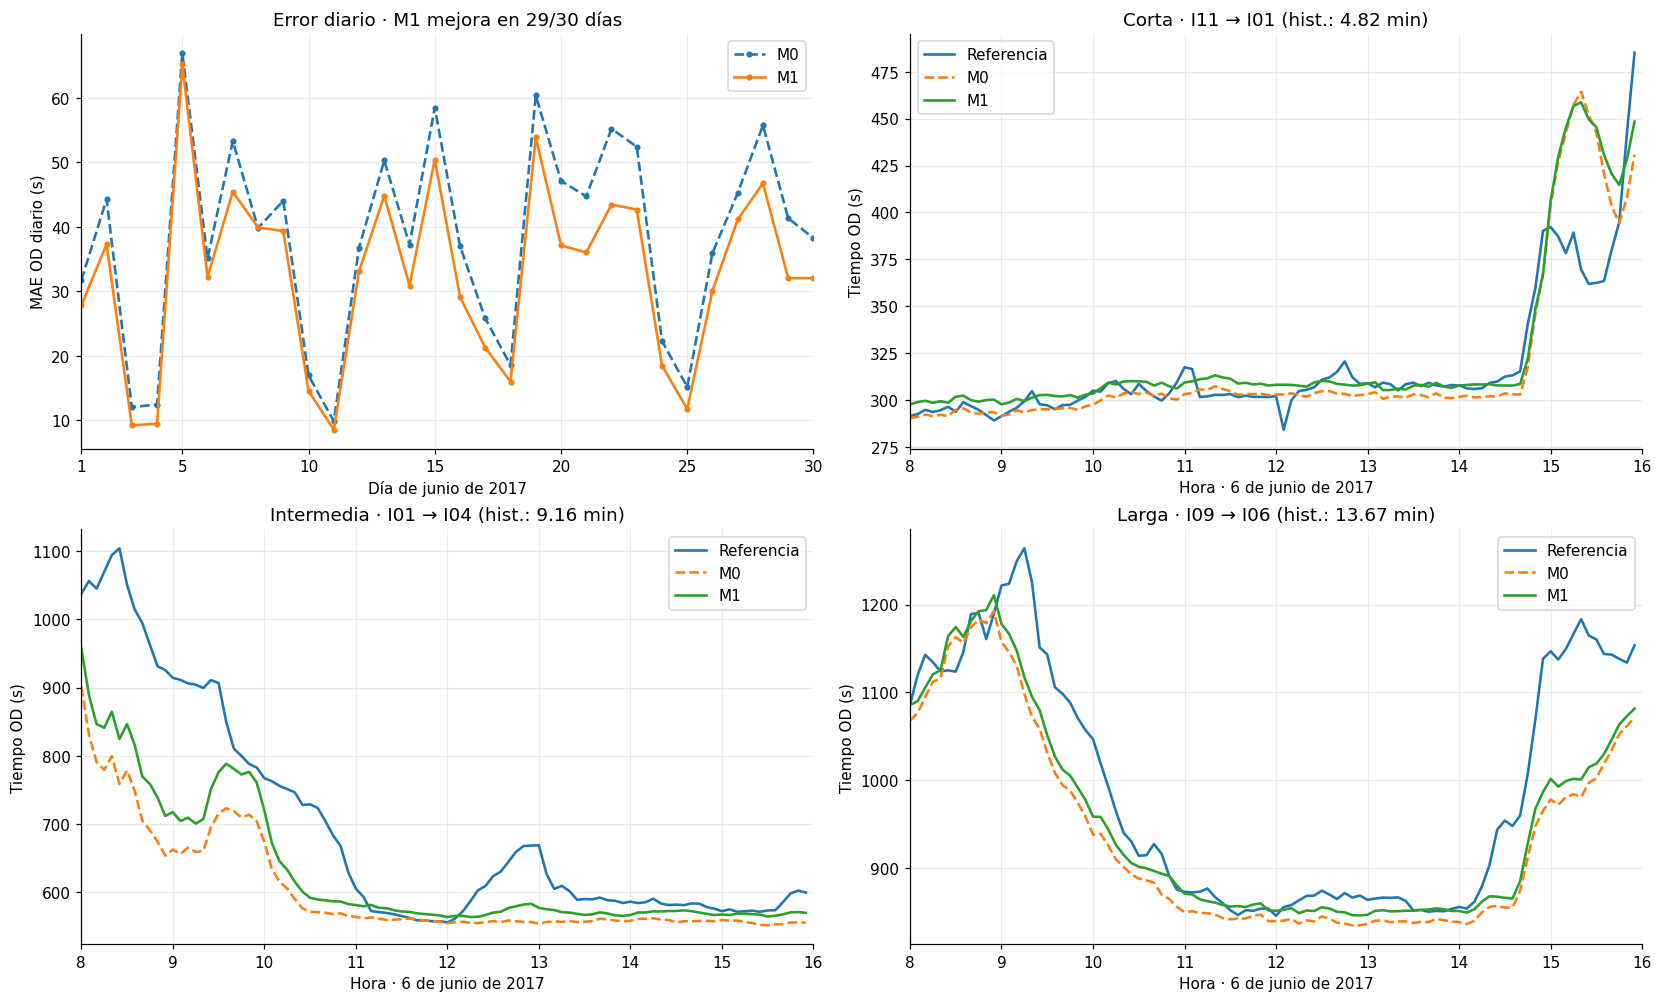

In [12]:
# Figura 3: error OD diario y perfiles temporales representativos por duración histórica.

# ============================================================
# 1) MAE diario sobre los ocho cortes horarios y 156 pares OD
# ============================================================
mae_dia_m0 = 60 * np.mean(np.abs(I_od_m0 - I_od_ref), axis=(1, 2))
mae_dia_m1 = 60 * np.mean(np.abs(I_od_m1 - I_od_ref), axis=(1, 2))

dias = np.arange(1, len(DAYS) + 1)
dias_mejora = int(np.sum(mae_dia_m1 < mae_dia_m0))

# ============================================================
# 2) Selección de pares OD representativos por categoría
#    de duración histórica (corta, intermedia, larga)
# ============================================================
ref_hist = od_matriz(reference.median().to_numpy())   # matriz histórica de referencia
ids = np.argwhere(mask13)                             # pares OD sin diagonal
hist_vals = ref_hist[mask13]                          # 156 duraciones históricas

q1, q2 = np.quantile(hist_vals, [1/3, 2/3])

grupos = {
    'Corta': hist_vals <= q1,
    'Intermedia': (hist_vals > q1) & (hist_vals <= q2),
    'Larga': hist_vals > q2
}

pares_repr = {}

for nombre, mascara in grupos.items():
    vals_g = hist_vals[mascara]
    ids_g = ids[mascara]

    mediana_g = np.median(vals_g)
    pos = np.argmin(np.abs(vals_g - mediana_g))

    ix, iy = map(int, ids_g[pos])
    pares_repr[nombre] = {
        'ix': ix,
        'iy': iy,
        'hist_min': ref_hist[ix, iy]
    }

# ============================================================
# 3) Jornada a ilustrar
# ============================================================
dia_objetivo = pd.Timestamp('2017-06-06')
dia_i = int(np.where(DAYS == dia_objetivo)[0][0])

# ============================================================
# 4) Función auxiliar para extraer el perfil temporal completo
#    (96 intervalos de 5 minutos) de un par OD
# ============================================================
def perfil_od_dia(T_stack, idx_dia, ix, iy):
    return 60 * np.array([
        od_matriz(z)[ix, iy] for z in T_stack[idx_dia]
    ], dtype=float)

horas = np.arange(96) / 12 + 8

# ============================================================
# 5) Figura 2x2
# ============================================================
fig, axs = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)

# ---- Panel A: MAE diario ----
ax = axs[0, 0]
ax.plot(dias, mae_dia_m0, '--o', markersize=3, linewidth=1.7, label='M0')
ax.plot(dias, mae_dia_m1, '-o',  markersize=3, linewidth=1.7, label='M1')

ax.set(
    xlabel='Día de junio de 2017',
    ylabel='MAE OD diario (s)',
    title=f'Error diario · M1 mejora en {dias_mejora}/{len(DAYS)} días',
    xlim=(1, len(DAYS))
)
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.grid(alpha=0.25)
ax.legend()

# ---- Paneles B, C y D: perfiles representativos ----
paneles = [
    ('Corta', axs[0, 1]),
    ('Intermedia', axs[1, 0]),
    ('Larga', axs[1, 1]),
]

for nombre, ax in paneles:
    ix = pares_repr[nombre]['ix']
    iy = pares_repr[nombre]['iy']
    hist_min = pares_repr[nombre]['hist_min']

    real_prof = perfil_od_dia(T_real, dia_i, ix, iy)
    m0_prof   = perfil_od_dia(T_m0,   dia_i, ix, iy)
    m1_prof   = perfil_od_dia(T_m1,   dia_i, ix, iy)

    for valores, etiqueta, estilo in [
        (real_prof, 'Referencia', '-'),
        (m0_prof, 'M0', '--'),
        (m1_prof, 'M1', '-')
    ]:
        ax.plot(
            horas, valores,
            linestyle=estilo, linewidth=1.7, label=etiqueta
        )

    ax.set(
        xlabel='Hora · 6 de junio de 2017',
        ylabel='Tiempo OD (s)',
        title=(
            f'{nombre} · {macro_ids[ix]} → {macro_ids[iy]} '
            f'(hist.: {hist_min:.2f} min)'
        ),
        xlim=(8, 16)
    )
    ax.grid(alpha=0.25)
    ax.legend()

# Guardar figura
fig.savefig(
    FIG / '03_I_MAE_diario_y_perfiles_OD_por_categoria.png',
    dpi=165,
    bbox_inches='tight'
)

plt.show()

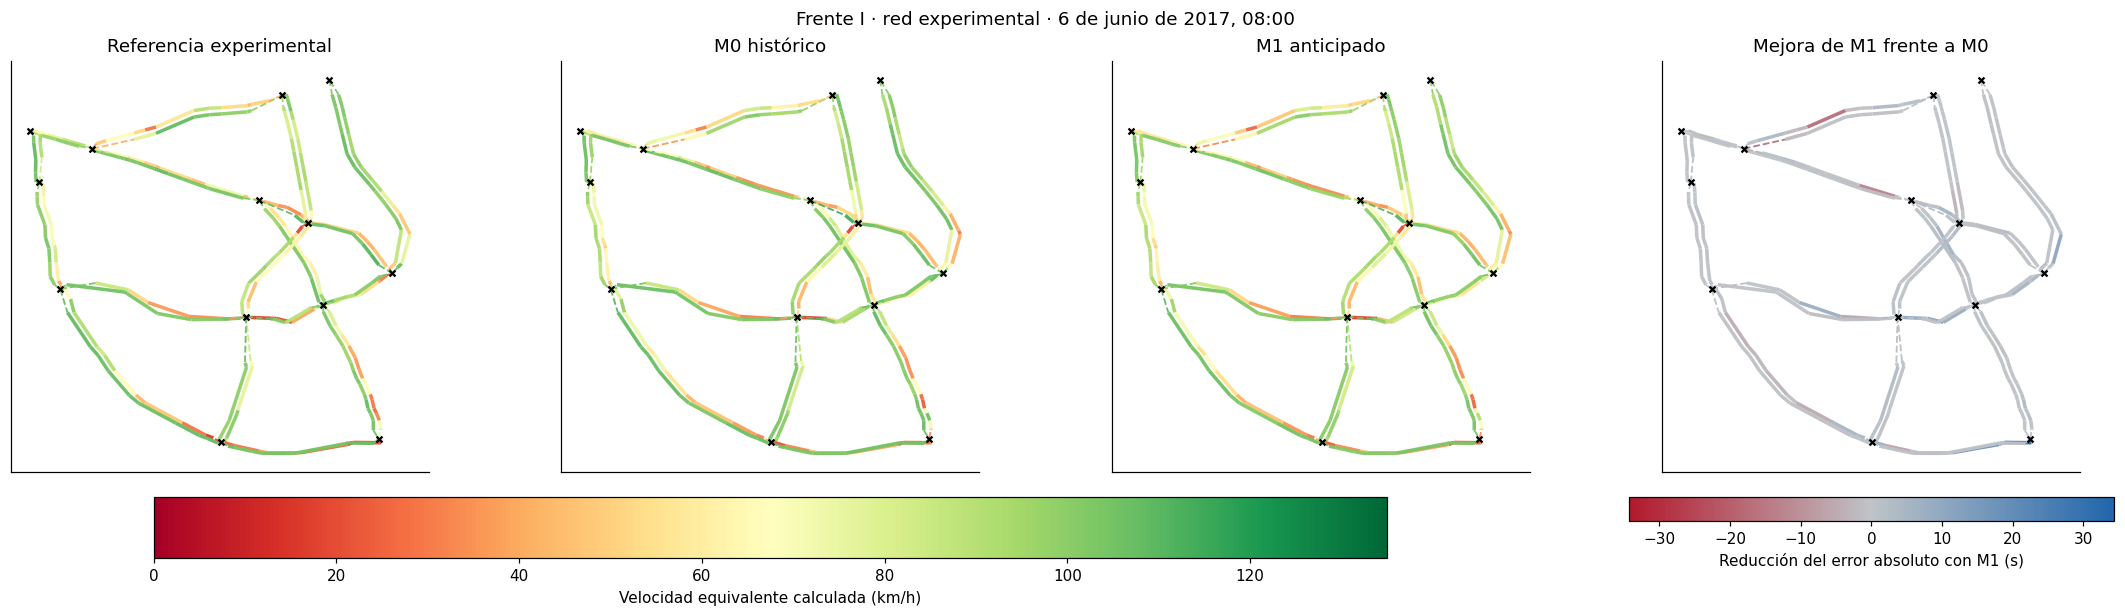

MAE por arista a las 08:00: M0 = 6.00 s; M1 = 5.66 s.


In [13]:

# Figura 4: estado espacial de la red y mejora de M1 frente a M0.

# Corte temporal común para las cuatro representaciones.
di = int(np.where(DAYS == pd.Timestamp('2017-06-06'))[0][0])
k = 0  # 08:00

real_ar = T_real[di, k]
m0_ar = T_m0[di, k]
m1_ar = T_m1[di, k]

# Velocidades equivalentes calculadas a partir de distancia y tiempo.
vel_real = velocidad_eq(real_ar)
vel_m0 = velocidad_eq(m0_ar)
vel_m1 = velocidad_eq(m1_ar)

# Escala común para los tres mapas de velocidad.
norm_vel = Normalize(vmin=0, vmax=135)
cmap_vel = plt.get_cmap('RdYlGn')

# Diferencia de errores absolutos por arista, en segundos.
# Positivo: M1 mejora a M0. Negativo: M1 empeora frente a M0.
error_m0 = 60 * np.abs(m0_ar - real_ar)
error_m1 = 60 * np.abs(m1_ar - real_ar)
mejora_s = error_m0 - error_m1

from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

# Escala divergente centrada en cero.
lim_mejora = max(float(np.max(np.abs(mejora_s))), 1e-9)

norm_mejora = TwoSlopeNorm(
    vmin=-lim_mejora,
    vcenter=0,
    vmax=lim_mejora
)

cmap_mejora = LinearSegmentedColormap.from_list(
    'mejora_error',
    ['#B2182B', '#BFC4C8', '#2166AC']
)

# Cuatro representaciones espaciales.
fig, axs = plt.subplots(
    1, 4, figsize=(20, 5.5), constrained_layout=True
)

for ax, valores, titulo in zip(
    axs[:3],
    [vel_real, vel_m0, vel_m1],
    ['Referencia experimental', 'M0 histórico', 'M1 anticipado']
):
    pintar_red(
        ax, valores, titulo,
        cmap_vel, norm_vel
    )

# Cuarto panel: ganancia de precisión de M1 por arista.
pintar_red(
    axs[3],
    mejora_s,
    'Mejora de M1 frente a M0',
    cmap_mejora,
    norm_mejora
)

# Escala compartida de velocidades.
sm_vel = plt.cm.ScalarMappable(
    norm=norm_vel,
    cmap=cmap_vel
)
sm_vel.set_array([])

fig.colorbar(
    sm_vel,
    ax=axs[:3],
    orientation='horizontal',
    shrink=0.8,
    label='Velocidad equivalente calculada (km/h)'
)

# Escala independiente para la diferencia de errores.
sm_mejora = plt.cm.ScalarMappable(
    norm=norm_mejora,
    cmap=cmap_mejora
)
sm_mejora.set_array([])

fig.colorbar(
    sm_mejora,
    ax=axs[3],
    orientation='horizontal',
    shrink=0.9,
    label='Reducción del error absoluto con M1 (s)'
)

fig.suptitle(
    'Frente I · red experimental · 6 de junio de 2017, 08:00'
)

fig.savefig(
    FIG / '04_I_mapa_y_mejora.png',
    dpi=165,
    bbox_inches='tight'
)
plt.show()

# Resumen numérico del mismo instante.
print(
    f'MAE por arista a las 08:00: '
    f'M0 = {error_m0.mean():.2f} s; '
    f'M1 = {error_m1.mean():.2f} s.'
)


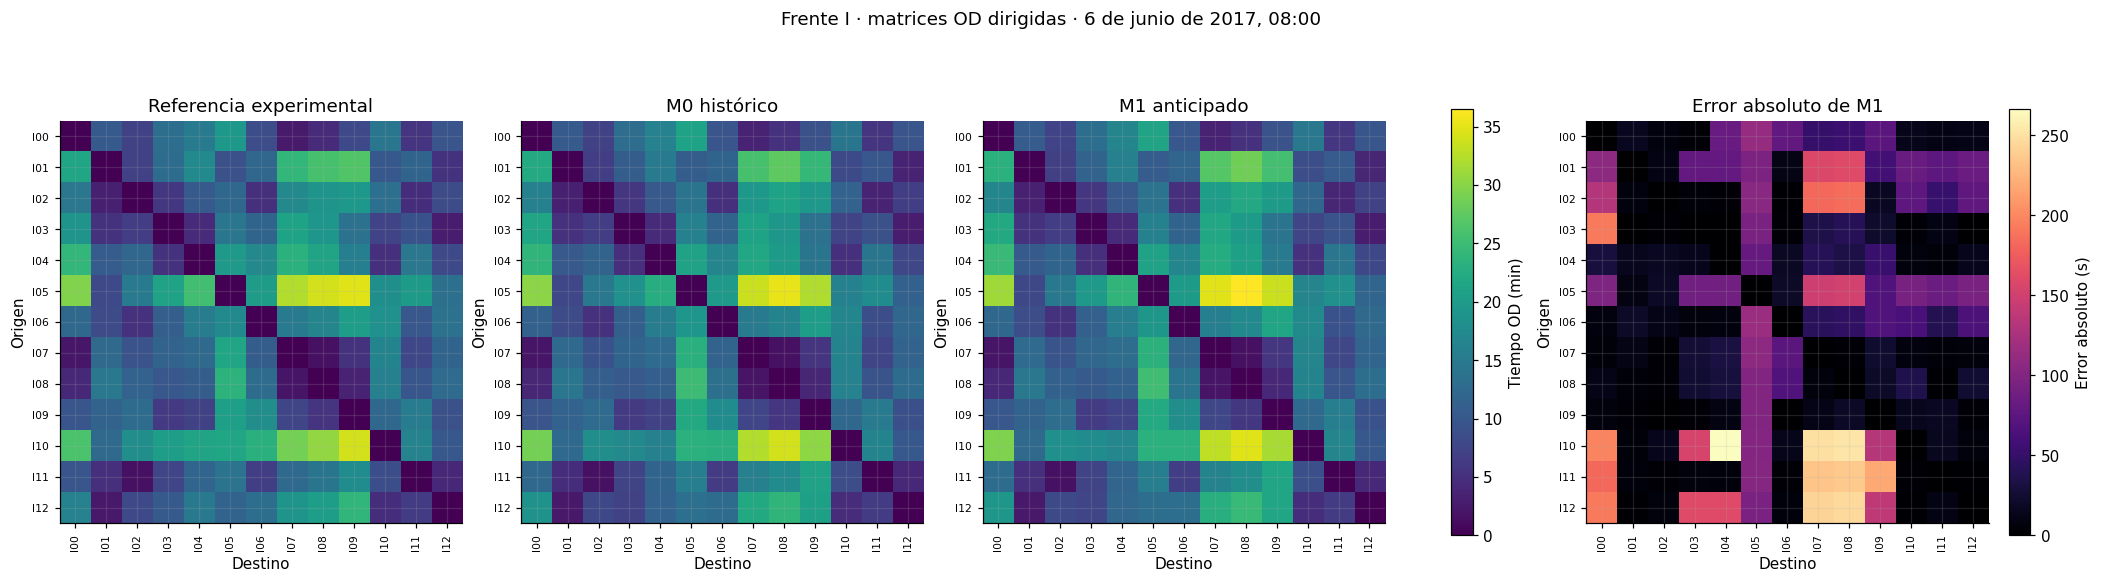

In [14]:

# Figura 5: matrices OD y errores absolutos de M1.

# Mismo instante utilizado en la figura 4.
di = int(np.where(DAYS == pd.Timestamp('2017-06-06'))[0][0])
k = 0  # 08:00

# Tiempos OD dirigidos entre los 13 macronodos (minutos).
od_ref = od_matriz(T_real[di, k])
od_m0 = od_matriz(T_m0[di, k])
od_m1 = od_matriz(T_m1[di, k])

# Error absoluto de M1 expresado en segundos.
error_m1 = 60 * np.abs(od_m1 - od_ref)

# Escala común para las tres matrices de tiempos.
lim_tiempo = max(od_ref.max(), od_m0.max(), od_m1.max())
norm_tiempo = Normalize(vmin=0, vmax=lim_tiempo)

fig, axs = plt.subplots(
    1, 4, figsize=(19, 5.5), constrained_layout=True
)

# Matrices de tiempos OD.
for ax, matriz, titulo in zip(
    axs[:3],
    [od_ref, od_m0, od_m1],
    ['Referencia experimental', 'M0 histórico', 'M1 anticipado']
):
    im_t = ax.imshow(
        matriz, cmap='viridis', norm=norm_tiempo
    )
    ax.set_title(titulo)

# Matriz de errores absolutos de M1.
im_e = axs[3].imshow(
    error_m1, cmap='magma', vmin=0
)
axs[3].set_title('Error absoluto de M1')

# Filas: orígenes. Columnas: destinos.
for ax in axs:
    ax.set_xticks(
        range(len(macro_ids)), macro_ids,
        rotation=90, fontsize=7
    )
    ax.set_yticks(
        range(len(macro_ids)), macro_ids,
        fontsize=7
    )
    ax.set_xlabel('Destino')
    ax.set_ylabel('Origen')

# Barras de color independientes según la variable representada.
fig.colorbar(
    im_t, ax=axs[:3], shrink=0.75,
    label='Tiempo OD (min)'
)

fig.colorbar(
    im_e, ax=axs[3], shrink=0.75,
    label='Error absoluto (s)'
)

fig.suptitle(
    'Frente I · matrices OD dirigidas · '
    '6 de junio de 2017, 08:00'
)

fig.savefig(
    FIG / '05_I_matrices_OD.png',
    dpi=175,
    bbox_inches='tight'
)

plt.show()


### Interpretación de las figuras 3–5

**Evolución diaria y perfiles temporales (figura 3).** La comparación del MAE diario muestra que M1 presenta errores inferiores a los de M0 en **29 de los 30 días de junio de 2017**, aunque la magnitud de la mejora varía entre jornadas. Ambas series presentan fluctuaciones semejantes, con incrementos y disminuciones del error en fechas similares, mientras que M1 generalmente mantiene valores menores. Esto permite apreciar visualmente la recurrencia de la mejora identificada en la evaluación cuantitativa.

Los tres perfiles temporales ilustran comportamientos diferentes según la duración histórica de los recorridos. En el **recorrido corto (I11 → I01, 4.82 minutos históricos)**, las estimaciones permanecen relativamente próximas a la referencia durante buena parte de la jornada, pero presentan desviaciones importantes ante los cambios registrados después de las 15:00, cuando ambos modelos llegan a sobrestimar los tiempos. En el **recorrido intermedio (I01 → I04, 9.16 minutos históricos)**, M0 y M1 subestiman considerablemente los tiempos de referencia durante la mañana; M1 generalmente se aproxima más a ellos, aunque no reproduce por completo sus fluctuaciones. Por su parte, en el **recorrido largo (I09 → I06, 13.67 minutos históricos)**, ambos modelos siguen parcialmente la evolución de los tiempos, pero subestiman algunos incrementos importantes, especialmente durante la mañana y hacia el final de la jornada.

Estos ejemplos muestran que las correcciones introducidas por M1 pueden acercar las estimaciones a los tiempos de referencia, pero no reproducen completamente sus variaciones temporales. Los recorridos fueron seleccionados por su duración histórica, por lo que sus perfiles ilustran situaciones particulares y no necesariamente representan el comportamiento promedio de cada categoría.

**Representación espacial de la red (figura 4).** Los mapas de velocidades equivalentes correspondientes al 6 de junio de 2017 a las 08:00 muestran patrones espaciales semejantes entre la referencia experimental y las estimaciones de M0 y M1. En los tres casos se distinguen conexiones con velocidades relativamente altas y otras con desplazamientos más lentos. Las diferencias entre modelos son menos evidentes visualmente, debido a que comparten buena parte de la estructura espacial de los tiempos de recorrido.

El cuarto mapa permite examinar directamente el efecto de las correcciones de M1 sobre el error absoluto de cada arista. Predominan las tonalidades próximas al valor central de la escala, lo que indica diferencias pequeñas entre los errores de ambos modelos en numerosas conexiones. Sin embargo, también se identifican aristas donde M1 mejora las estimaciones y otras donde las empeora. Así, aunque las representaciones de velocidades resultan similares, las diferencias de precisión no son uniformes en toda la red.

**Matrices de tiempos OD (figura 5).** Las tres matrices de tiempos presentan estructuras semejantes: los pares OD con mayores tiempos de referencia tienden a mostrar también estimaciones elevadas en M0 y M1. No obstante, existen diferencias localizadas que resultan más evidentes en la matriz de errores absolutos de M1.

En particular, destacan varios recorridos con origen en los macronodos **I10, I11 e I12**, especialmente hacia destinos como **I07 e I08**, cuyos errores alcanzan aproximadamente **250 segundos**, equivalentes a poco más de cuatro minutos. En contraste, numerosos pares OD presentan diferencias considerablemente menores. Esta distribución evidencia que la precisión no es uniforme entre las conexiones de la red y que la similitud general de las matrices puede coexistir con errores importantes en determinados recorridos.

También debe distinguirse entre los errores de las aristas y los errores OD. Aunque las diferencias individuales en las conexiones pueden ser pequeñas, sus efectos sobre los tiempos de los caminos completos pueden alcanzar magnitudes mayores. La matriz de errores permite identificar estas discrepancias, pero no establece por sí misma si M1 supera a M0 en cada par OD.

**En conjunto**, las figuras complementan la evaluación cuantitativa desde tres perspectivas. La evolución diaria muestra que la mejora de M1 es recurrente durante junio, mientras que los perfiles temporales ilustran sus dificultades para reproducir determinadas fluctuaciones. Por su parte, las representaciones espaciales muestran diferencias localizadas en la precisión por arista y las matrices OD permiten identificar recorridos con errores de mayor magnitud. Estos resultados muestran que M1 mejora las estimaciones históricas en términos generales, pero que dicha mejora no es uniforme entre jornadas, conexiones y condiciones de circulación.

## II. Reconstrucción contemporánea: actualizar tiempos durante la operación (Avance 4)

### II.1. De una referencia histórica a una reconstrucción con información contemporánea

El segundo componente busca estimar los tiempos de desplazamiento de la red experimental utilizando información limitada sobre las condiciones de circulación del instante actual. La pregunta que orienta este análisis es si **la incorporación de un conjunto reducido de tiempos origen-destino (OD) guía permite reconstruir los tiempos de las aristas con mayor precisión que una referencia basada exclusivamente en patrones históricos**.

Para responderla, se consideran dos alternativas desarrolladas en el Avance 4:

- **K=0 (referencia histórica):** estima el tiempo de recorrido de cada arista mediante la mediana histórica correspondiente al mismo día de la semana e intervalo de cinco minutos, calculada con información de enero a mayo de 2017 para la evaluación final de junio.

- **K=32 (modelo propuesto):** utiliza una regresión Ridge multisalida para estimar correcciones a los tiempos históricos de las aristas a partir de **32 tiempos OD guía correspondientes al instante evaluado**. El modelo aprovecha estas observaciones para reconstruir los tiempos de las conexiones que no se observan directamente.

**Información disponible y reconstrucción.** A diferencia del componente anticipado, K=32 dispone de información correspondiente al mismo instante cuyos tiempos busca estimar. En el experimento, los 32 tiempos OD guía se obtienen mediante simulaciones sobre la red experimental, utilizando los tiempos de referencia de sus aristas. Por tanto, representan observaciones contemporáneas simuladas y no consultas realizadas a un servicio externo de información vial.

Esta diferencia responde a los distintos momentos de decisión de ambos componentes: mientras M1 proporciona pronósticos antes del inicio de la jornada, K=32 busca actualizar las estimaciones a partir de información disponible durante la operación. En consecuencia, sus errores no deben compararse directamente como si ambos modelos dispusieran de la misma información.

**Procedimiento de evaluación.** La libreta recupera las predicciones generadas previamente en el Avance 4, sin volver a entrenar el modelo Ridge. La evaluación comprende **120 cortes temporales de junio de 2017** y considera las estimaciones de las **345 aristas dirigidas** de la red experimental.

A partir de los tiempos estimados por arista se calculan, mediante caminos mínimos, las matrices OD correspondientes a los **13 macronodos de intercambio**, el mismo conjunto utilizado en el componente anticipado. Esto permite evaluar **156 pares OD dirigidos por corte, equivalentes a 18,720 estimaciones durante junio**, y mantener una estructura común de las matrices destinadas a una eventual integración con el componente de optimización.

La evaluación original del Avance 4 sobre cinco grupos de 20 nodos permanece documentada en esa entrega; no se reproduce en la presente libreta auxiliar.

In [15]:
# Recuperar las predicciones por arista generadas en el Avance 4.
a4_manifest = json.loads(
    (A4_DIR / 'manifest.json').read_text(encoding='utf-8')
)

# Verificar la correspondencia con el orden de las aristas de la red.
if a4_manifest['edge_columns'] != ids_arista:
    raise ValueError(
        'El orden de aristas del Avance 4 no corresponde al dataset seleccionado.'
    )

with np.load(A4_DIR / 'predicciones_junio.npz', allow_pickle=False) as archivo:
    a4_ts = pd.DatetimeIndex(pd.to_datetime(archivo['timestamps']))
    a4_real = archivo['actual_edges'].astype('float64')
    a4_hist = archivo['baseline_edges'].astype('float64')
    a4_pred = archivo['ridge_edges'].astype('float64')

# Las tres matrices deben corresponder a los mismos cortes y aristas.
forma_esperada = (len(a4_ts), len(ids_arista))

for nombre, matriz in [
    ('Referencia', a4_real),
    ('K=0', a4_hist),
    ('K=32', a4_pred)
]:
    if matriz.shape != forma_esperada:
        raise ValueError(
            f'Dimensiones incompatibles en {nombre}: {matriz.shape}.'
        )

print(
    f'Avance 4: {len(a4_ts)} cortes temporales; '
    f'{len(ids_arista)} aristas dirigidas.'
)
print(
    f'Evaluación OD prevista: {len(macro_ids)} macronodos; '
    f'{len(a4_ts) * len(macro_ids) * (len(macro_ids) - 1):,} '
    'estimaciones OD dirigidas.'
)

Avance 4: 120 cortes temporales; 345 aristas dirigidas.
Evaluación OD prevista: 13 macronodos; 18,720 estimaciones OD dirigidas.


### II.2. Evaluación de la reconstrucción K=32: aristas y matrices OD

Para evaluar el desempeño de K=32, comparamos sus estimaciones con los tiempos de referencia de la red experimental correspondientes a **120 cortes temporales de junio de 2017**. Se aplica el mismo procedimiento a K=0, de modo que ambos modelos se evalúan sobre las mismas aristas e instantes y bajo las mismas condiciones experimentales.

La evaluación se realiza en dos niveles. Primero, examinamos los **tiempos por arista**, considerando las 345 conexiones dirigidas de la red, para valorar la precisión con que K=32 reconstruye los tiempos de desplazamiento a partir de las 32 consultas OD guía simuladas. Posteriormente, calculamos las **matrices de tiempos origen-destino (OD)** mediante caminos mínimos, para examinar cómo se traducen estas estimaciones en tiempos de recorrido entre los 13 macronodos seleccionados.

Para las matrices OD se consideran los 120 cortes temporales, con **156 pares dirigidos de origen y destino en cada corte**, equivalentes a 18,720 estimaciones. La evaluación comienza con el **WAPE y la duración media de los recorridos**, que permiten contextualizar la magnitud relativa de los errores. Después se examinan el MAE, la distribución de los errores, el sesgo y la frecuencia de subestimación.

Este análisis complementa la evaluación presentada en el Avance 4 al utilizar el conjunto de 13 macronodos definido para ambos componentes. Se conservan las predicciones originales de K=32, sin modificar su entrenamiento ni el procedimiento de reconstrucción.

In [16]:
# Evaluación de K=0 y K=32 sobre las mismas aristas y cortes temporales.

res_II_ar = pd.DataFrame([
    {
        'modelo': nombre,
        **metricas(a4_real, pred, '345 aristas · 120 cortes')
    }
    for nombre, pred in [('K=0', a4_hist), ('K=32', a4_pred)]
])


# Matrices OD entre los 13 macronodos para los 120 cortes.
# Se conservan las matrices completas para las visualizaciones posteriores.
II13_ref_mats = np.stack([
    od_matriz(pesos) for pesos in a4_real
])
II13_k0_mats = np.stack([
    od_matriz(pesos) for pesos in a4_hist
])
II13_k32_mats = np.stack([
    od_matriz(pesos) for pesos in a4_pred
])

forma_matrices = (len(a4_ts), len(macro_ids), len(macro_ids))

assert (
    II13_ref_mats.shape
    == II13_k0_mats.shape
    == II13_k32_mats.shape
    == forma_matrices
)


# Evaluación OD: se excluyen las diagonales de las matrices.
# Cada corte contiene 156 pares dirigidos entre macronodos distintos.
II13_ref = II13_ref_mats[:, mask13]
II13_k0 = II13_k0_mats[:, mask13]
II13_k32 = II13_k32_mats[:, mask13]

assert (
    II13_ref.shape
    == II13_k0.shape
    == II13_k32.shape
    == (len(a4_ts), 156)
)


# Métricas sobre los mismos pares OD e instantes para ambos modelos.
res_II_od = pd.DataFrame([
    {
        'modelo': nombre,
        **metricas(II13_ref, pred, '13 macronodos · 120 cortes')
    }
    for nombre, pred in [('K=0', II13_k0), ('K=32', II13_k32)]
])


# Presentación conjunta con el mismo formato del componente I.
columnas = [
    'nivel', 'modelo', 'N', 'real_media_s',
    'WAPE_pct', 'MAE_s', 'MdAPE_pct',
    'P95_error_s', 'sesgo_medio_s', 'subestimacion_pct'
]

resultados_II = pd.concat([
    res_II_ar.assign(nivel='Aristas'),
    res_II_od.assign(nivel='OD')
], ignore_index=True)

display(resultados_II[columnas].round(3))


# Conservación de las métricas.
res_II_ar.to_csv(
    OUT / 'II_metricas_aristas.csv', index=False
)
res_II_od.to_csv(
    OUT / 'II_metricas_OD.csv', index=False
)


,nivel,modelo,N,real_media_s,WAPE_pct,MAE_s,MdAPE_pct,P95_error_s,sesgo_medio_s,subestimacion_pct
0,Aristas,K=0,41400,29.130,6.375,1.857,1.569,6.696,-0.797,55.848
1,Aristas,K=32,41400,29.130,5.486,1.598,1.921,5.746,0.014,42.150
2,OD,K=0,18720,608.851,4.012,24.424,1.323,128.085,-15.338,69.749
3,OD,K=32,18720,608.851,1.233,7.506,0.428,28.368,0.008,36.095


### Interpretación de resultados

La evaluación de junio de 2017 muestra que K=32 reduce los errores de la referencia histórica K=0, tanto en las aristas individuales como en los recorridos origen-destino (OD) entre los 13 macronodos. Sin embargo, la magnitud de las mejoras y el comportamiento de las distintas métricas difieren entre ambos niveles.

**Precisión de los tiempos por arista.** Para las 345 aristas dirigidas, cuya duración media de referencia es de **29.13 segundos**, K=32 obtiene un error absoluto medio (MAE) de **1.60 segundos**, frente a **1.86 segundos** de K=0. El WAPE disminuye de **6.38 % a 5.49 %**, lo que representa una reducción de aproximadamente **14 % en el error absoluto agregado**.

El percentil 95 del error absoluto también disminuye, de **6.70 a 5.75 segundos**, indicando una reducción de los errores relativamente elevados. En cambio, la mediana del error porcentual absoluto (MdAPE) aumenta de **1.57 % con K=0 a 1.92 % con K=32**. Esto muestra que la mejora en las métricas agregadas no se extiende a todos los indicadores: K=32 reduce la magnitud promedio de los errores por arista, pero presenta un error porcentual mediano ligeramente mayor.

**Precisión de los recorridos OD.** Al calcular los tiempos entre los 13 macronodos, K=32 presenta mejoras de mayor magnitud. Sobre **18,720 estimaciones OD**, correspondientes a recorridos cuya duración media de referencia es de **10.15 minutos**, el WAPE disminuye de **4.01 % con K=0 a 1.23 % con K=32**, mientras que el MAE pasa de **24.42 a 7.51 segundos**. Esto equivale a una reducción aproximada del **69.3 % en el error absoluto medio**.

La mejora también se observa en la distribución de los errores individuales. La MdAPE disminuye de **1.32 % a 0.43 %**, mientras que el percentil 95 del error absoluto pasa de **128.09 a 28.37 segundos**. Así, el 95 % de las estimaciones OD de K=32 presenta errores absolutos no superiores a aproximadamente 28 segundos en los cortes evaluados. Este resultado muestra que la reconstrucción contemporánea no solo reduce el error promedio, sino también la magnitud de las desviaciones relativamente elevadas.

**Dirección de los errores.** En las aristas individuales, el sesgo medio pasa de **-0.80 segundos con K=0 a 0.01 segundos con K=32**, mientras que la frecuencia de subestimación disminuye de **55.85 % a 42.15 %**. En los recorridos OD se observa un comportamiento semejante: el sesgo medio pasa de **-15.34 a 0.01 segundos** y la frecuencia de subestimación disminuye de **69.75 % a 36.10 %**.

Estos resultados indican que K=32 reduce la tendencia de la referencia histórica a subestimar los tiempos de desplazamiento. Sin embargo, un sesgo medio cercano a cero no implica que todas las predicciones sean exactas, pues las sobrestimaciones y subestimaciones pueden compensarse al calcular el promedio. Por ello, es necesario considerar conjuntamente el sesgo, las métricas de error absoluto y la frecuencia de subestimación.

**En conjunto**, K=32 presenta una mejora considerable frente a K=0 en la reconstrucción de tiempos OD y una reducción más moderada de los errores por arista. La diferencia entre ambos niveles muestra que el desempeño debe evaluarse tanto en las conexiones individuales como en los recorridos completos. Además, el aumento de la MdAPE por arista confirma que las mejoras no son uniformes entre las distintas métricas.

Estos resultados corresponden a un procedimiento de reconstrucción que utiliza **32 tiempos OD guía simulados del mismo instante evaluado**, por lo que deben interpretarse en función de esa disponibilidad de información contemporánea. A continuación, examinamos cómo varían los errores según la duración histórica de las conexiones y los recorridos, las tolerancias consideradas y las condiciones relativas de circulación.

### II.3. Análisis desagregado de los errores: duración, tolerancias y condiciones de la red

Las métricas anteriores muestran una reducción considerable del error OD con K=32 respecto de K=0. Para examinar si esta mejora se mantiene entre recorridos de distintas duraciones y condiciones de circulación, realizamos los mismos análisis complementarios utilizados en el componente anticipado, considerando ahora los **120 cortes temporales de la reconstrucción contemporánea**.

**Errores según la duración histórica.** Clasificamos las aristas y los pares OD en tres grupos de duración —corta, intermedia y larga— utilizando como criterio común de clasificación las medianas históricas de enero a marzo de 2017 y los mismos criterios de clasificación del componente I. Esto permite examinar cómo varía la precisión de K=32 según la duración característica de las conexiones y los recorridos, independientemente de los errores observados durante junio.

**Tolerancias de error en los recorridos OD.** Calculamos el porcentaje de estimaciones cuyo error relativo es inferior al **5 %**, cuyo error absoluto es inferior a **60 segundos** y cuya subestimación supera los **120 segundos**. Estos indicadores permiten valorar la frecuencia de predicciones cercanas a sus tiempos de referencia y la persistencia de subestimaciones de mayor magnitud. Los umbrales tienen un propósito descriptivo y no constituyen criterios establecidos de aceptación o factibilidad de las rutas.

**Errores según las condiciones de circulación.** Para cada corte temporal, calculamos la relación entre la suma de los tiempos de referencia de las aristas de corredor y la suma de sus respectivos tiempos históricos de K=0. A partir de la distribución de este indicador en los **120 cortes evaluados**, distinguimos tres grupos: el 10 % de menor lentitud relativa, el 80 % intermedio y el 10 % de mayor lentitud relativa. Esta clasificación permite examinar cómo cambia la precisión OD de K=32 bajo diferentes condiciones de circulación.

Al igual que en el componente I, los estados de la red se identifican retrospectivamente mediante los tiempos de referencia y se utilizan únicamente para analizar los errores. No representan necesariamente incidentes viales ni situaciones de congestión identificadas directamente. Dado que los cortes temporales de ambos componentes son distintos, cada evaluación utiliza su propia distribución del indicador para establecer estos grupos.

Finalmente, examinamos la **consistencia diaria de la mejora de K=32 respecto de K=0**, utilizando exclusivamente los tiempos OD entre los 13 macronodos. Esto permite determinar si la reducción del error se presenta de manera recurrente durante junio o si se concentra en unas pocas jornadas.

In [17]:
# Duración histórica característica de cada arista y par OD.
# Se utilizan las mismas referencias y terciles que en el componente I.

escala_II_ar = por_escala(
    a4_real, a4_hist, a4_pred,
    hist_ar[None, :], 'II', 'Aristas'
)

escala_II_od = por_escala(
    II13_ref, II13_k0, II13_k32,
    hist13[None, :], 'II', 'OD 13'
)

# Frecuencias respecto de tres tolerancias descriptivas.
tol_II = tolerancias_od(
    II13_ref, II13_k0, II13_k32, 'II · K=32'
)

for tab, nombre in [
    (escala_II_ar, 'II_escala_aristas.csv'),
    (escala_II_od, 'II_escala_OD_13.csv'),
    (tol_II, 'II_tolerancias_OD_13.csv')
]:
    tab.to_csv(OUT / nombre, index=False)


print('Errores por duración histórica de las aristas')
display(escala_II_ar[
    ['duracion_historica', 'modelo', 'N',
     'real_media_s', 'WAPE_pct', 'MAE_s',
     'subestimacion_pct']
].round(2))

print('Errores por duración histórica de los recorridos OD')
display(escala_II_od[
    ['duracion_historica', 'modelo', 'N',
     'real_media_s', 'WAPE_pct', 'MAE_s',
     'subestimacion_pct']
].round(2))

print('Tolerancias de error en los recorridos OD')
display(tol_II.round(2))


# Estados relativos de circulación.
# Los umbrales P10 y P90 se calculan sobre los 120 cortes evaluados,
# utilizando exclusivamente las aristas de corredor.
ratio_II, reg_II, q_II = regimen_red(
    a4_real, a4_hist, mask_corr
)

# Cada estado del corte se asigna a sus 156 pares OD dirigidos.
regimen_II = resumen_regimen_od(
    II13_ref, II13_k0, II13_k32,
    reg_II[:, None], 'II · K=32'
)

regimen_II.to_csv(
    OUT / 'II_regimenes_red_OD_13.csv', index=False
)

print('Errores OD según el estado relativo de la red')
display(regimen_II[
    ['regimen', 'modelo', 'N', 'WAPE_pct',
     'sesgo_medio_s', 'subestimacion_pct',
     'participacion_cortes_pct',
     'participacion_error_abs_pct']
].round(2))


# Consistencia diaria de la mejora sobre los 13 macronodos.
# Se acumula el error absoluto de los 156 pares OD de cada corte.
# La función agrupa posteriormente los cortes por jornada.
errII0 = np.abs(II13_k0 - II13_ref).sum(axis=1)
errII1 = np.abs(II13_k32 - II13_ref).sum(axis=1)

res_est_II, dia_II = estabilidad_por_dia(
    a4_ts, errII0, errII1, 'II · Contemporánea K=32'
)

dia_II.to_csv(
    OUT / 'II_errores_OD_por_dia.csv'
)

print(
    f"K=32 mejora en {res_est_II['dias_mejora']} de "
    f"{res_est_II['dias']} jornadas; "
    f"reducción global del MAE OD: "
    f"{res_est_II['mejora_MAE_global_pct']:.2f} %."
)


Errores por duración histórica de las aristas


,duracion_historica,modelo,N,real_media_s,WAPE_pct,MAE_s,subestimacion_pct
0,Corta,Histórico,13800,8.76,6.20,0.54,54.10
1,Corta,Modelo,13800,8.76,6.59,0.58,39.43
2,Intermedia,Histórico,13800,23.74,5.89,1.40,55.63
3,Intermedia,Modelo,13800,23.74,4.87,1.16,43.87
4,Larga,Histórico,13800,54.89,6.61,3.63,57.81
5,Larga,Modelo,13800,54.89,5.58,3.06,43.14


Errores por duración histórica de los recorridos OD


,duracion_historica,modelo,N,real_media_s,WAPE_pct,MAE_s,subestimacion_pct
0,Corta,Histórico,6240,299.06,4.88,14.60,64.74
1,Corta,Modelo,6240,299.06,1.58,4.72,38.57
2,Intermedia,Histórico,6240,596.24,4.14,24.68,70.03
3,Intermedia,Modelo,6240,596.24,1.33,7.95,35.61
4,Larga,Histórico,6240,931.26,3.65,33.99,74.47
5,Larga,Modelo,6240,931.26,1.06,9.85,34.10


Tolerancias de error en los recorridos OD


,frente,modelo,pct_error_rel_menor_5,pct_error_abs_menor_60s,pct_subestimacion_mayor_120s,N
0,II · K=32,Histórico,83.46,89.10,4.76,18720
1,II · K=32,Modelo,96.40,97.69,0.37,18720


Errores OD según el estado relativo de la red


,regimen,modelo,N,WAPE_pct,sesgo_medio_s,subestimacion_pct,participacion_cortes_pct,participacion_error_abs_pct
0,10 % menor lentitud relativa,Histórico,1872,4.43,17.34,32.64,10.0,11.35
1,10 % menor lentitud relativa,Modelo,1872,1.66,-3.53,47.70,10.0,13.83
2,80 % intermedio,Histórico,14976,2.84,-12.04,72.50,80.0,55.01
3,80 % intermedio,Modelo,14976,0.94,1.36,32.89,80.0,59.23
4,10 % mayor lentitud relativa,Histórico,1872,11.21,-74.40,84.88,10.0,33.64
5,10 % mayor lentitud relativa,Modelo,1872,2.76,-7.29,50.11,10.0,26.94


K=32 mejora en 30 de 30 jornadas; reducción global del MAE OD: 69.27 %.


### Interpretación de resultados

**Errores según la duración histórica.** La evaluación desagregada muestra que la mejora de K=32 frente a K=0 varía según la duración de las conexiones y el nivel de análisis considerado.

En las **aristas individuales**, los tiempos medios de referencia son de **8.76, 23.74 y 54.89 segundos** para las categorías corta, intermedia y larga, respectivamente. El MAE de K=32 es progresivamente mayor entre estos grupos, con valores de **0.58, 1.16 y 3.06 segundos**, mientras que el WAPE presenta valores de **6.59 %, 4.87 % y 5.58 %**. En las aristas intermedias y largas, K=32 reduce tanto el MAE como el WAPE respecto de K=0. Sin embargo, en las aristas cortas el MAE aumenta ligeramente de **0.54 a 0.58 segundos** y el WAPE de **6.20 % a 6.59 %**. Por tanto, la mejora agregada de K=32 no se extiende a todas las categorías de duración.

En los **recorridos OD**, los tiempos medios de referencia son de **4.98, 9.94 y 15.52 minutos** para las categorías corta, intermedia y larga, respectivamente. El MAE de K=32 es progresivamente mayor entre estos grupos, con valores de **4.72, 7.95 y 9.85 segundos**, mientras que el WAPE disminuye de **1.58 % a 1.33 % y 1.06 %**. A diferencia de lo observado en las aristas cortas, K=32 mejora las estimaciones de K=0 en los tres grupos de recorridos OD, tanto en MAE como en WAPE.

En conjunto, los resultados muestran que los errores absolutos son mayores en los desplazamientos de mayor duración, pero su importancia relativa no sigue necesariamente la misma tendencia. Asimismo, la mejora en las estimaciones de los recorridos completos puede coexistir con un deterioro moderado de la precisión en determinadas categorías de aristas.

**Tolerancias de error.** El porcentaje de estimaciones OD cuyo error relativo es inferior al **5 %** aumenta de **83.46 % con K=0 a 96.40 % con K=32**. De manera semejante, la proporción de estimaciones con errores absolutos menores a un minuto pasa de **89.10 % a 97.69 %**. Ambos resultados muestran que la incorporación de las 32 consultas OD guía simuladas incrementa considerablemente la frecuencia de estimaciones cercanas a sus tiempos de referencia.

Por otra parte, el porcentaje de estimaciones que **subestiman el tiempo de referencia por más de dos minutos** disminuye de **4.76 % con K=0 a 0.37 % con K=32**. Esta reducción es relevante para una posible aplicación a la planeación de rutas con ventanas de tiempo, donde las subestimaciones pueden afectar el cumplimiento de las restricciones temporales. No obstante, los umbrales utilizados son descriptivos y no permiten determinar directamente la factibilidad de las rutas.

**Errores según las condiciones de circulación.** El desempeño de K=32 presenta diferencias entre los tres estados relativos de la red, aunque mejora el WAPE de K=0 en todos ellos.

En los instantes de **menor lentitud relativa**, el WAPE OD disminuye de **4.43 % con K=0 a 1.66 % con K=32**. El sesgo medio pasa de **17.34 a −3.53 segundos**, mientras que la frecuencia de subestimación aumenta de **32.64 % a 47.70 %**. Esto indica que K=32 reduce considerablemente la magnitud de los errores, aunque modifica su distribución entre sobrestimaciones y subestimaciones.

En los instantes de **condiciones intermedias**, el WAPE disminuye de **2.84 % a 0.94 %**. El sesgo medio pasa de **−12.04 a 1.36 segundos** y la frecuencia de subestimación se reduce de **72.50 % a 32.89 %**. Estos resultados muestran que K=32 mejora la precisión relativa y reduce la tendencia de K=0 a estimar tiempos inferiores a los de referencia.

En los instantes de **mayor lentitud relativa**, K=32 consigue una mejora considerable al reducir el WAPE de **11.21 % a 2.76 %**. El sesgo medio pasa de **−74.40 a −7.29 segundos**, mientras que la frecuencia de subestimación disminuye de **84.88 % a 50.11 %**. Aunque K=32 reduce sustancialmente las desviaciones, este grupo conserva el WAPE más elevado de los tres estados considerados.

La concentración del error en estas condiciones también resulta relevante: los instantes de mayor lentitud relativa representan el **10 % de los cortes evaluados**, pero acumulan el **26.94 % del error absoluto total de K=32**. Esto indica que, aun después de incorporar información contemporánea, una parte desproporcionada del error se concentra en los periodos en que los tiempos de desplazamiento son mayores respecto de sus valores históricos.

**Consistencia diaria.** Al examinar los errores OD por jornada, K=32 presenta un error absoluto acumulado inferior al de K=0 en **los 30 días de junio de 2017**, con una reducción global del MAE del **69.27 %**. Esto muestra que la mejora se observa de manera recurrente durante todo el periodo evaluado y no depende de unas pocas jornadas particularmente favorables.

**En conjunto**, los análisis complementarios muestran que K=32 mejora considerablemente la reconstrucción de los tiempos OD en distintas escalas de duración y condiciones de circulación. Sin embargo, la mejora no es uniforme: las aristas cortas presentan un ligero deterioro del error, mientras que los instantes de mayor lentitud relativa concentran una proporción importante de las desviaciones restantes. Estos hallazgos permiten caracterizar las fortalezas y limitaciones de la reconstrucción contemporánea y respaldan la utilidad de incorporar información actual para actualizar las estimaciones de tiempos de recorrido.

### II.4. Evidencia gráfica de la reconstrucción contemporánea

Para complementar la evaluación cuantitativa de K=32, se presentan tres figuras que permiten examinar la evolución diaria de los errores, su distribución según la duración histórica de los recorridos y las diferencias espaciales entre las estimaciones. Se utiliza el mismo conjunto de 13 macronodos considerado en el componente anticipado, manteniendo las particularidades de sus respectivos protocolos temporales.

La **figura 6** contiene dos gráficas. La primera compara el error absoluto medio (MAE) diario de K=0 y K=32 durante los **30 días de junio de 2017**, utilizando los 120 cortes temporales y los 156 pares OD considerados en la evaluación. La segunda muestra la distribución de los errores absolutos de ambos modelos para los recorridos de duración histórica corta, intermedia y larga, utilizando todas las observaciones de cada categoría. Los diagramas de caja representan los percentiles 25 y 75, la mediana y los percentiles 5 y 95, lo que permite comparar tanto los errores centrales como su dispersión entre modelos y categorías de duración.

La **figura 7** presenta cuatro representaciones espaciales de la red experimental correspondientes al **6 de junio de 2017 a las 07:00**, instante utilizado también en el Avance 4. Las tres primeras muestran las velocidades equivalentes calculadas a partir de los tiempos de referencia y de las estimaciones de K=0 y K=32, utilizando una escala cromática común. La cuarta representa, para cada arista, la reducción del error absoluto obtenida con K=32 respecto de K=0, expresada en segundos. Los valores positivos indican una mejora de K=32, los negativos un deterioro y los próximos a cero diferencias pequeñas entre ambos modelos.

La **figura 8** muestra, para ese mismo instante, las matrices de tiempos OD entre los 13 macronodos. Se presentan las matrices correspondientes a la referencia experimental, K=0 y K=32, así como una cuarta matriz con los errores absolutos de K=32 respecto de la referencia. Las tres matrices de tiempos comparten una escala cromática expresada en minutos, mientras que la matriz de errores utiliza una escala independiente en segundos. Las filas representan los orígenes y las columnas los destinos, de acuerdo con el carácter dirigido de la red.

Estas visualizaciones complementan la evaluación cuantitativa al mostrar la consistencia diaria de las mejoras, la distribución de los errores entre recorridos de distintas duraciones y las diferencias localizadas en la red. Su interpretación distingue entre los resultados obtenidos durante todo junio y las representaciones correspondientes a un instante específico.

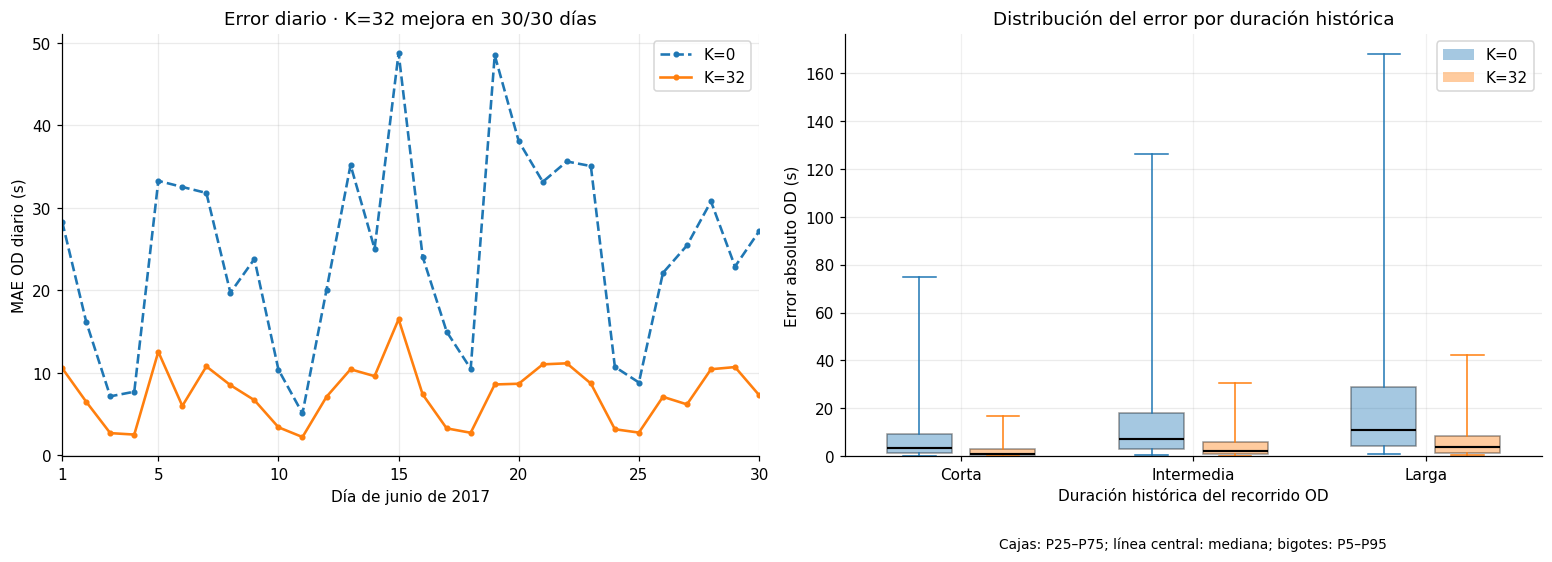

In [18]:

# Figura 6: MAE OD diario y distribución del error por duración histórica.

from matplotlib.patches import Patch

# ============================================================
# 1. MAE diario sobre los 156 pares OD de cada corte
# ============================================================

errores_cortes = pd.DataFrame({
    'dia': pd.DatetimeIndex(a4_ts).normalize(),
    'K=0': 60 * np.mean(
        np.abs(II13_k0 - II13_ref), axis=1
    ),
    'K=32': 60 * np.mean(
        np.abs(II13_k32 - II13_ref), axis=1
    )
})

mae_diario_II = (
    errores_cortes.groupby('dia')[['K=0', 'K=32']].mean()
)

dias_mejora_II = int(
    (mae_diario_II['K=32'] < mae_diario_II['K=0']).sum()
)


# ============================================================
# 2. Distribución de errores OD según duración histórica
# ============================================================

# Se utilizan los mismos terciles históricos de la sección II.3.
hist_vals = np.asarray(hist13, dtype=float).ravel()
q1, q2 = np.quantile(hist_vals, [1/3, 2/3])

grupos = [
    ('Corta', hist_vals <= q1),
    ('Intermedia', (hist_vals > q1) & (hist_vals <= q2)),
    ('Larga', hist_vals > q2)
]

# Errores absolutos en segundos: 120 cortes × 156 pares OD.
error_k0 = 60 * np.abs(II13_k0 - II13_ref)
error_k32 = 60 * np.abs(II13_k32 - II13_ref)

# Dos distribuciones por categoría: K=0 y K=32.
datos_cajas = []
for nombre, mascara in grupos:
    datos_cajas.extend([
        error_k0[:, mascara].ravel(),
        error_k32[:, mascara].ravel()
    ])

posiciones = [
    0.82, 1.18,
    1.82, 2.18,
    2.82, 3.18
]


# ============================================================
# 3. Visualización
# ============================================================

fig, axs = plt.subplots(
    1, 2, figsize=(14, 5), constrained_layout=True
)

# Panel A: MAE OD diario.
ax = axs[0]

linea_k0, = ax.plot(
    mae_diario_II.index.day,
    mae_diario_II['K=0'],
    '--o', markersize=3, linewidth=1.7,
    label='K=0'
)

linea_k32, = ax.plot(
    mae_diario_II.index.day,
    mae_diario_II['K=32'],
    '-o', markersize=3, linewidth=1.7,
    label='K=32'
)

ax.set(
    xlabel='Día de junio de 2017',
    ylabel='MAE OD diario (s)',
    title=(
        f'Error diario · K=32 mejora en '
        f'{dias_mejora_II}/{len(mae_diario_II)} días'
    ),
    xlim=(1, 30)
)
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.grid(alpha=0.25)
ax.legend()


# Panel B: distribución del error absoluto por duración.
ax = axs[1]

bp = ax.boxplot(
    datos_cajas,
    positions=posiciones,
    widths=0.28,
    patch_artist=True,
    showfliers=False,
    whis=(5, 95),
    medianprops={'color': 'black', 'linewidth': 1.4}
)

# Colores consistentes con el panel de MAE diario.
colores = [linea_k0.get_color(), linea_k32.get_color()]

for i, caja in enumerate(bp['boxes']):
    caja.set_facecolor(colores[i % 2])
    caja.set_alpha(0.40)

for i, elemento in enumerate(bp['whiskers']):
    elemento.set_color(colores[(i // 2) % 2])

for i, elemento in enumerate(bp['caps']):
    elemento.set_color(colores[(i // 2) % 2])

ax.set(
    xlabel='Duración histórica del recorrido OD',
    ylabel='Error absoluto OD (s)',
    title='Distribución del error por duración histórica'
)

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['Corta', 'Intermedia', 'Larga'])
ax.set_xlim(0.5, 3.5)
ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=0.25)

ax.legend(handles=[
    Patch(facecolor=colores[0], alpha=0.40, label='K=0'),
    Patch(facecolor=colores[1], alpha=0.40, label='K=32')
])

# Los bigotes corresponden a P5 y P95.
# Las observaciones fuera de ese intervalo no se dibujan.
ax.text(
    0.5, -0.19,
    'Cajas: P25–P75; línea central: mediana; bigotes: P5–P95',
    transform=ax.transAxes,
    ha='center', va='top', fontsize=9
)

fig.savefig(
    FIG / '06_II_MAE_diario_y_distribucion_OD.png',
    dpi=165,
    bbox_inches='tight'
)

plt.show()

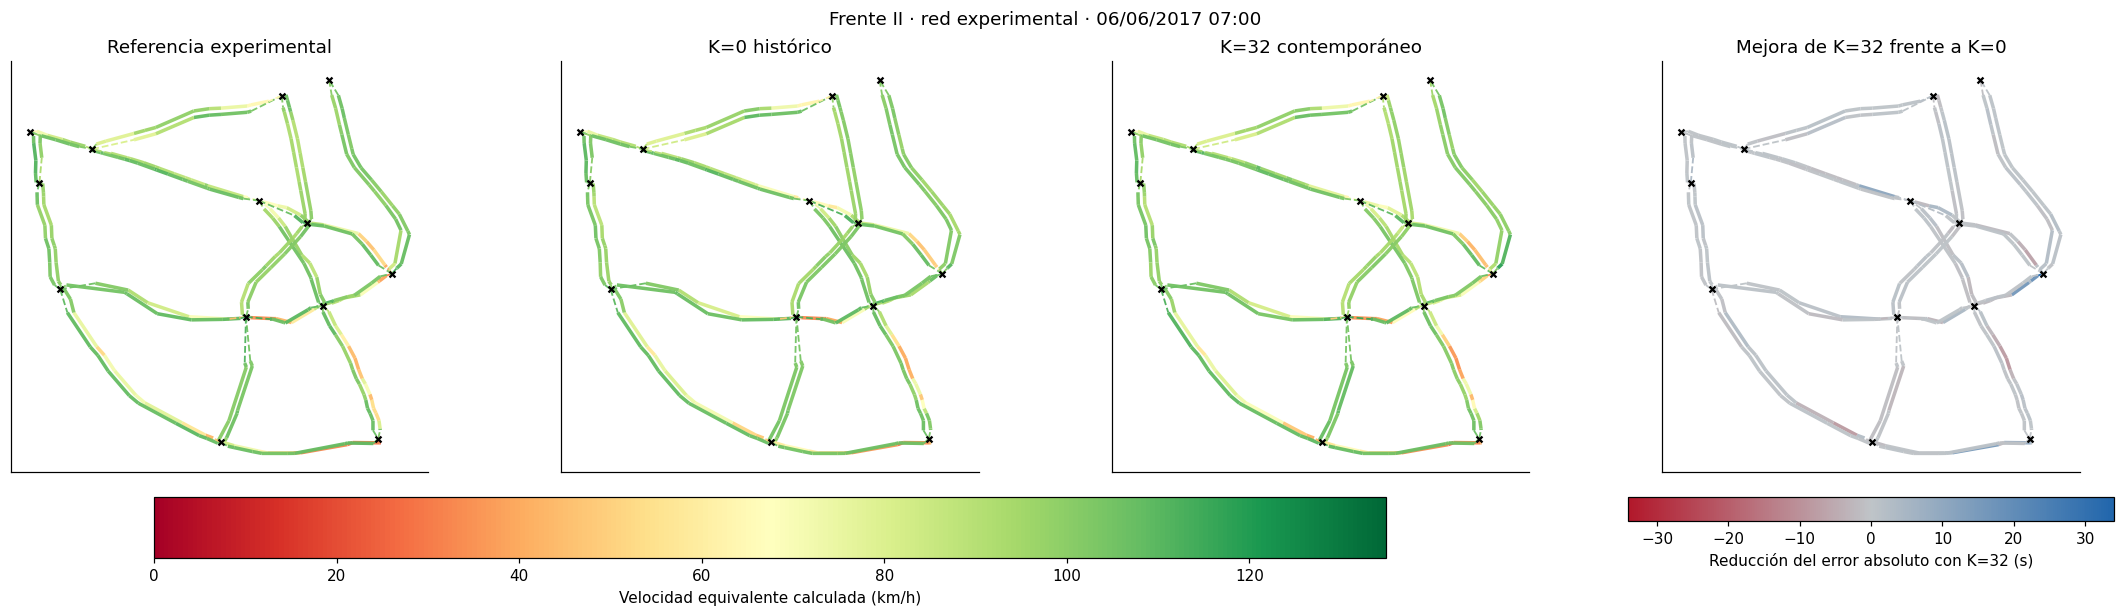

Corte seleccionado: 06/06/2017 07:00
MAE por arista: K=0 = 1.75 s; K=32 = 1.56 s.


In [19]:

# Figura 7: reconstrucción espacial y mejora de K=32 frente a K=0.

from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

# Seleccionar el mismo instante ilustrativo del Avance 4.
objetivo = pd.Timestamp('2017-06-06 07:00')
coincidencias = np.flatnonzero(a4_ts == objetivo)

if len(coincidencias) != 1:
    raise ValueError(
        'No se encontró un corte único para el 6 de junio de 2017 a las 07:00.'
    )

pos = int(coincidencias[0])
instante = a4_ts[pos]

# Tiempos por arista en el instante seleccionado (minutos).
real_ar_II = a4_real[pos]
k0_ar = a4_hist[pos]
k32_ar = a4_pred[pos]

# Velocidades equivalentes calculadas a partir de distancia y tiempo.
vel_real_II = velocidad_eq(real_ar_II)
vel_k0 = velocidad_eq(k0_ar)
vel_k32 = velocidad_eq(k32_ar)

# Escala común de velocidades, igual a la utilizada en la figura 4.
norm_vel = Normalize(vmin=0, vmax=135)
cmap_vel = plt.get_cmap('RdYlGn')

# Diferencia de errores absolutos por arista, expresada en segundos.
# Valores positivos: K=32 mejora a K=0.
# Valores negativos: K=32 presenta un error mayor.
error_k0_ar = 60 * np.abs(k0_ar - real_ar_II)
error_k32_ar = 60 * np.abs(k32_ar - real_ar_II)
mejora_II_s = error_k0_ar - error_k32_ar

# Escala divergente simétrica y centrada en cero.
lim_mejora = max(float(np.max(np.abs(mejora_II_s))), 1e-9)

norm_mejora = TwoSlopeNorm(
    vmin=-lim_mejora,
    vcenter=0,
    vmax=lim_mejora
)

cmap_mejora = LinearSegmentedColormap.from_list(
    'mejora_error_II',
    ['#B2182B', '#BFC4C8', '#2166AC']
)

# Cuatro representaciones espaciales.
fig, axs = plt.subplots(
    1, 4, figsize=(20, 5.5), constrained_layout=True
)

# Referencia experimental y estimaciones de ambos modelos.
for ax, valores, titulo in zip(
    axs[:3],
    [vel_real_II, vel_k0, vel_k32],
    ['Referencia experimental', 'K=0 histórico', 'K=32 contemporáneo']
):
    pintar_red(
        ax, valores, titulo,
        cmap_vel, norm_vel
    )

# Cuarto panel: reducción del error absoluto con K=32.
pintar_red(
    axs[3],
    mejora_II_s,
    'Mejora de K=32 frente a K=0',
    cmap_mejora,
    norm_mejora
)

# Barra de colores compartida por los tres mapas de velocidades.
sm_vel = plt.cm.ScalarMappable(
    norm=norm_vel,
    cmap=cmap_vel
)
sm_vel.set_array([])

fig.colorbar(
    sm_vel,
    ax=axs[:3],
    orientation='horizontal',
    shrink=0.8,
    label='Velocidad equivalente calculada (km/h)'
)

# Barra independiente para la mejora del error absoluto.
sm_mejora = plt.cm.ScalarMappable(
    norm=norm_mejora,
    cmap=cmap_mejora
)
sm_mejora.set_array([])

fig.colorbar(
    sm_mejora,
    ax=axs[3],
    orientation='horizontal',
    shrink=0.9,
    label='Reducción del error absoluto con K=32 (s)'
)

# Título con el instante exacto, sin depender del idioma del sistema.
fig.suptitle(
    f'Frente II · red experimental · {instante:%d/%m/%Y %H:%M}'
)

fig.savefig(
    FIG / '07_II_mapa_y_mejora.png',
    dpi=165,
    bbox_inches='tight'
)

plt.show()

# Resumen de precisión por arista en el corte representado.
print(f'Corte seleccionado: {instante:%d/%m/%Y %H:%M}')
print(
    f'MAE por arista: '
    f'K=0 = {error_k0_ar.mean():.2f} s; '
    f'K=32 = {error_k32_ar.mean():.2f} s.'
)

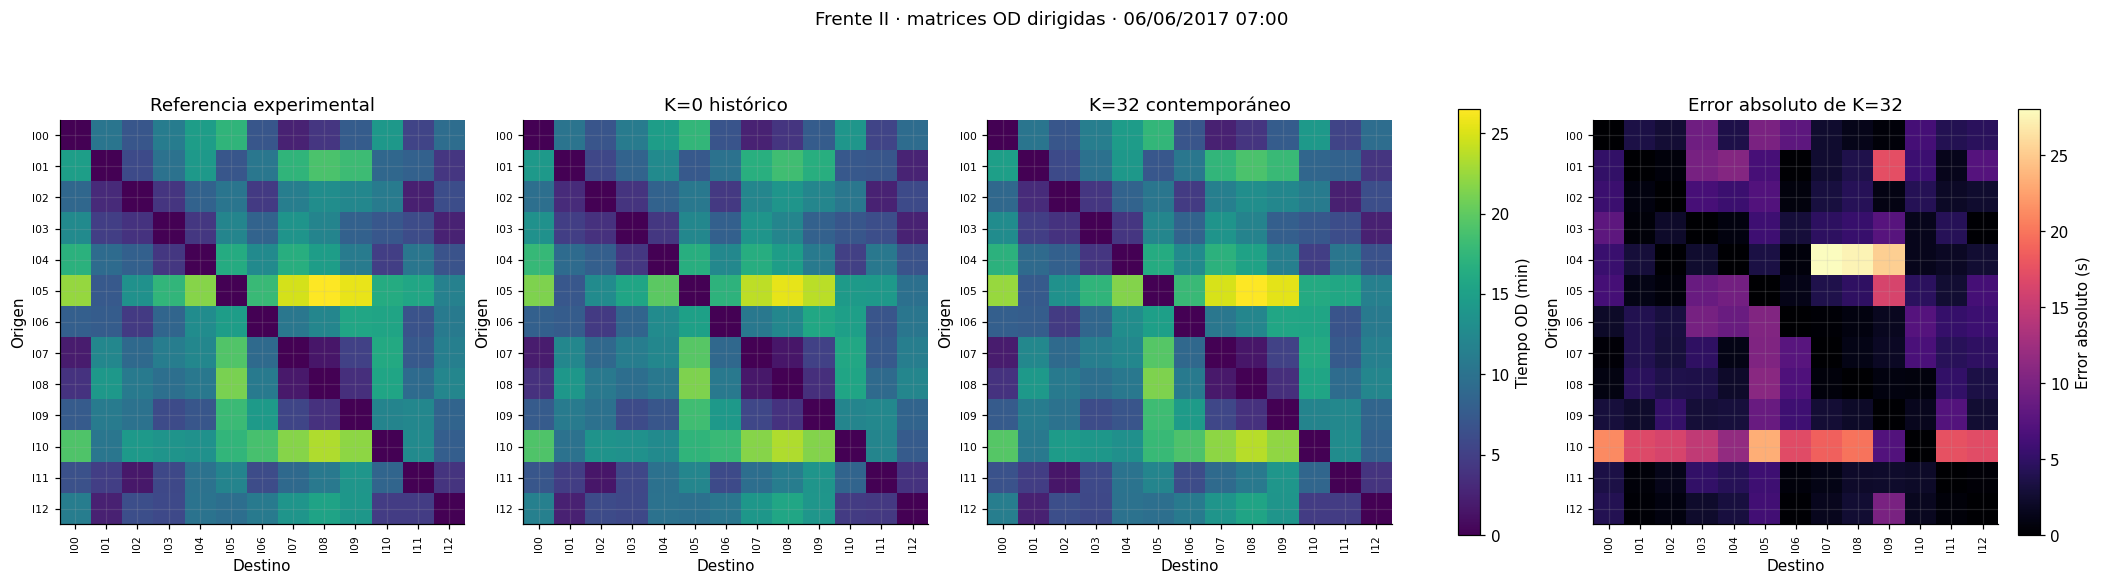

In [20]:
# Figura 8: matrices OD y errores absolutos de K=32.

# Mismo instante utilizado en la figura 7.
instante = a4_ts[pos]
assert instante == pd.Timestamp('2017-06-06 07:00')

# Matrices OD dirigidas entre los 13 macronodos (minutos).
od_ref_II = II13_ref_mats[pos]
od_k0 = II13_k0_mats[pos]
od_k32 = II13_k32_mats[pos]

# Error absoluto de K=32 respecto de la referencia (segundos).
error_k32 = 60 * np.abs(od_k32 - od_ref_II)

# Escala común para las tres matrices de tiempos.
lim_tiempo = max(
    od_ref_II.max(),
    od_k0.max(),
    od_k32.max()
)
norm_tiempo = Normalize(vmin=0, vmax=lim_tiempo)

fig, axs = plt.subplots(
    1, 4, figsize=(19, 5.5), constrained_layout=True
)

# Matrices de referencia, K=0 y K=32.
for ax, matriz, titulo in zip(
    axs[:3],
    [od_ref_II, od_k0, od_k32],
    [
        'Referencia experimental',
        'K=0 histórico',
        'K=32 contemporáneo'
    ]
):
    im_t = ax.imshow(
        matriz,
        cmap='viridis',
        norm=norm_tiempo
    )
    ax.set_title(titulo)

# Cuarta matriz: error absoluto de K=32.
im_e = axs[3].imshow(
    error_k32,
    cmap='magma',
    vmin=0
)
axs[3].set_title('Error absoluto de K=32')

# Filas: orígenes. Columnas: destinos.
for ax in axs:
    ax.set_xticks(
        range(len(macro_ids)), macro_ids,
        rotation=90, fontsize=7
    )
    ax.set_yticks(
        range(len(macro_ids)), macro_ids,
        fontsize=7
    )
    ax.set_xlabel('Destino')
    ax.set_ylabel('Origen')

# Escala común para los tiempos OD.
fig.colorbar(
    im_t,
    ax=axs[:3],
    shrink=0.75,
    label='Tiempo OD (min)'
)

# Escala independiente para el error absoluto.
fig.colorbar(
    im_e,
    ax=axs[3],
    shrink=0.75,
    label='Error absoluto (s)'
)

fig.suptitle(
    f'Frente II · matrices OD dirigidas · '
    f'{instante:%d/%m/%Y %H:%M}'
)

fig.savefig(
    FIG / '08_II_matrices_OD_13_macronodos.png',
    dpi=175,
    bbox_inches='tight'
)

plt.show()

### Interpretación de las figuras 6–8

**Evolución diaria y distribución de errores (figura 6).** La comparación del MAE diario muestra que K=32 presenta errores inferiores a los de K=0 en **los 30 días de junio de 2017**. La magnitud de la mejora varía entre jornadas y resulta especialmente visible en aquellas donde la referencia histórica registra errores elevados. Aunque ambas series presentan fluctuaciones a lo largo del mes, K=32 mantiene valores considerablemente menores y más estables.

Los diagramas de caja permiten examinar cómo se distribuyen los errores absolutos según la duración histórica de los recorridos OD. En las tres categorías, K=32 presenta medianas menores y distribuciones más concentradas cerca de cero que K=0. La diferencia es particularmente visible en los recorridos intermedios y largos, donde la referencia histórica presenta una mayor dispersión y valores elevados en el extremo superior de la distribución.

Estos resultados complementan el análisis desagregado de la sección anterior: aunque los errores absolutos de K=32 tienden a ser mayores entre los grupos de recorridos de mayor duración, se mantienen considerablemente por debajo de los registrados con K=0. La reducción no se limita al error medio, sino que también se refleja en la distribución de los errores individuales.

**Representación espacial de la red (figura 7).** Los mapas correspondientes al 6 de junio de 2017 a las 07:00 muestran patrones de velocidades equivalentes semejantes entre la referencia experimental y las estimaciones de K=0 y K=32. Los tres conservan la distribución general de conexiones con velocidades relativamente altas y bajas, aunque presentan diferencias locales en sus valores estimados.

El cuarto mapa permite examinar directamente cómo cambian los errores absolutos por arista al utilizar K=32. Predominan las tonalidades próximas al centro de la escala, lo que indica diferencias pequeñas entre los errores de ambos modelos en numerosas conexiones. También se identifican aristas donde K=32 mejora las estimaciones y otras donde las empeora, lo que confirma que la reducción agregada del error no es uniforme en toda la red.

La representación espacial muestra, por tanto, que K=32 conserva la estructura general de los tiempos de desplazamiento y modifica la precisión de determinadas conexiones. Sin embargo, las diferencias entre los mapas de velocidades son sutiles, por lo que resulta útil examinar también las matrices de tiempos correspondientes a recorridos completos.

**Matrices de tiempos OD (figura 8).** Las matrices de referencia, K=0 y K=32 presentan estructuras semejantes, con relaciones OD que conservan sus diferencias generales de duración. No obstante, la matriz de errores absolutos de K=32 permite identificar discrepancias localizadas que no resultan evidentes al comparar únicamente las matrices de tiempos.

En particular, destacan algunos recorridos con origen en **I04 y destinos I07, I08 e I09**, así como diversas relaciones con origen en **I10**. Los errores más elevados de la matriz se aproximan a **30 segundos**, mientras que numerosos pares OD presentan diferencias considerablemente menores. Esto muestra que, incluso cuando la reconstrucción contemporánea alcanza una precisión elevada en términos agregados, persisten relaciones específicas donde las estimaciones se alejan más de sus valores de referencia.

La cuarta matriz representa únicamente la magnitud del error de K=32 y no permite determinar si el modelo mejora a K=0 en cada relación OD. Asimismo, las diferencias observadas corresponden al instante seleccionado y no necesariamente caracterizan el comportamiento de esos mismos recorridos durante todo junio.

**En conjunto**, las figuras muestran que la mejora de K=32 respecto de K=0 es recurrente durante el periodo evaluado y se refleja en una menor dispersión de los errores OD para las tres categorías de duración histórica. Las representaciones espaciales y las matrices OD complementan estos resultados al identificar diferencias localizadas que persisten pese a la reducción del error agregado. Así, la incorporación de información contemporánea simulada permite reconstruir los tiempos de desplazamiento con mayor precisión, aunque no elimina por completo las desviaciones en determinadas conexiones y recorridos.

## III. Síntesis de resultados de ambos componentes

Las evaluaciones anteriores permiten examinar dos procedimientos complementarios para estimar los tiempos de desplazamiento: **M1**, orientado al pronóstico anticipado de la jornada siguiente, y **K=32**, destinado a reconstruir los tiempos de la red utilizando información contemporánea parcial.

Para reunir los principales resultados, presentamos una tabla con las métricas de ambos componentes sobre el conjunto común de **13 macronodos y 156 pares origen-destino (OD) dirigidos**. La tabla incluye la duración media de los recorridos, los errores de cada modelo y su respectiva referencia histórica, la reducción porcentual del MAE y el número de jornadas en las que se observa una mejora. Se conservan los cortes temporales y las condiciones de información propios de cada procedimiento.

La **figura 9** complementa esta síntesis al mostrar cómo varía el WAPE OD según tres estados relativos de circulación: menor lentitud, condiciones intermedias y mayor lentitud respecto del comportamiento histórico de la red. Cada componente aparece en un panel independiente y se compara con su propia referencia. Los estados se clasifican retrospectivamente y sus umbrales se calculan por separado para cada evaluación.

El propósito de esta síntesis es identificar las aportaciones y dificultades de ambos procedimientos, no establecer una competencia directa entre sus errores. M1 utiliza información disponible antes de la jornada, mientras que K=32 incorpora consultas OD guía simuladas correspondientes al instante evaluado. Estas diferencias, junto con sus respectivos protocolos temporales, deben considerarse al interpretar los resultados.

Síntesis de los resultados OD


Componente,N OD,Duración (min),WAPE ref. (%),WAPE modelo (%),MAE ref. (s),MAE modelo (s),P95 modelo (s),Reducción MAE (%),Días con mejora
I · M1,"37,440",10.57,6.02,5.15,38.15,32.67,147.67,14.36,29/30
II · K=32,"18,720",10.15,4.01,1.23,24.42,7.51,28.37,69.27,30/30


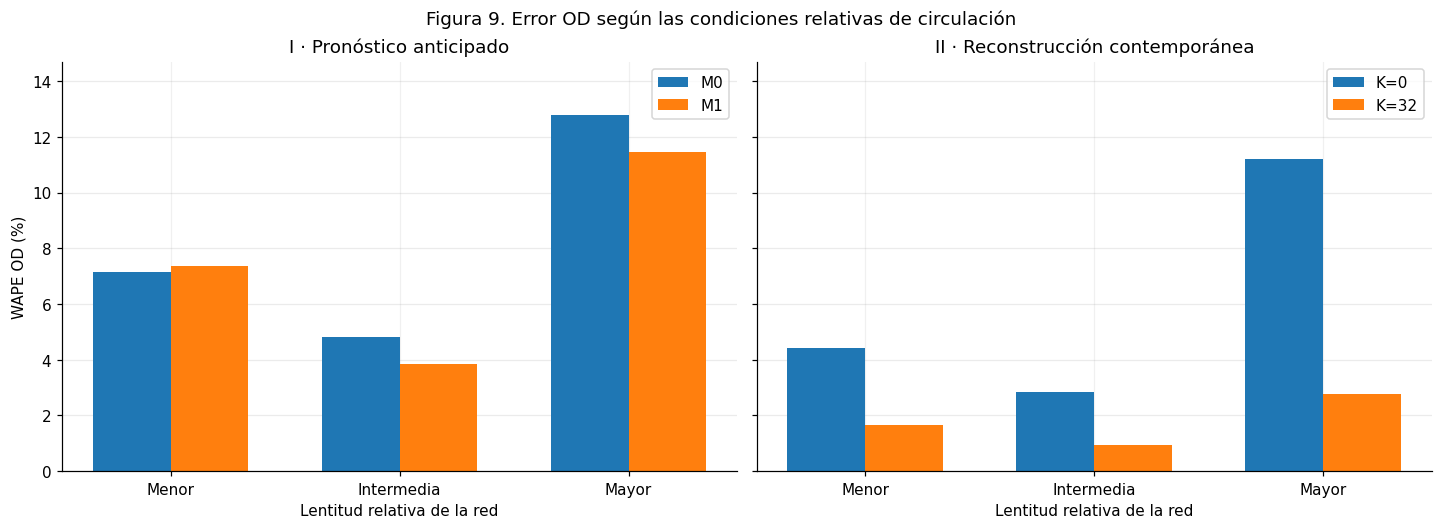

In [21]:
# III. Síntesis de los resultados OD de ambos componentes.
# Cada modelo se compara exclusivamente con su referencia histórica.

casos = [
    ('I · Pronóstico anticipado', res_I_od, res_est_I, 'M0', 'M1'),
    ('II · Reconstrucción contemporánea', res_II_od, res_est_II,
     'K=0', 'K=32')
]

filas = []

for nombre, tabla, estabilidad, ref_nombre, modelo_nombre in casos:
    datos = tabla.set_index('modelo')
    base = datos.loc[ref_nombre]
    modelo = datos.loc[modelo_nombre]

    filas.append({
        'componente': nombre,
        'N_OD': int(base['N']),
        'duracion_OD_media_min': base['real_media_s'] / 60,
        'WAPE_referencia_pct': base['WAPE_pct'],
        'WAPE_modelo_pct': modelo['WAPE_pct'],
        'MAE_referencia_s': base['MAE_s'],
        'MAE_modelo_s': modelo['MAE_s'],
        'P95_error_modelo_s': modelo['P95_error_s'],
        'reduccion_MAE_pct': 100 * (
            1 - modelo['MAE_s'] / base['MAE_s']
        ),
        'jornadas_con_mejora': (
            f"{estabilidad['dias_mejora']}/{estabilidad['dias']}"
        )
    })

sintesis = pd.DataFrame(filas)

# Conservar la tabla completa con nombres descriptivos.
sintesis.to_csv(
    OUT / 'sintesis_dos_frentes.csv',
    index=False
)

# Presentación compacta para facilitar su lectura en la libreta.
tabla_sintesis = sintesis.copy()
tabla_sintesis['componente'] = ['I · M1', 'II · K=32']

tabla_sintesis = tabla_sintesis.rename(columns={
    'componente': 'Componente',
    'N_OD': 'N OD',
    'duracion_OD_media_min': 'Duración (min)',
    'WAPE_referencia_pct': 'WAPE ref. (%)',
    'WAPE_modelo_pct': 'WAPE modelo (%)',
    'MAE_referencia_s': 'MAE ref. (s)',
    'MAE_modelo_s': 'MAE modelo (s)',
    'P95_error_modelo_s': 'P95 modelo (s)',
    'reduccion_MAE_pct': 'Reducción MAE (%)',
    'jornadas_con_mejora': 'Días con mejora'
})

print('Síntesis de los resultados OD')

display(
    tabla_sintesis.style
    .hide(axis='index')
    .format({
        'N OD': '{:,.0f}',
        'Duración (min)': '{:.2f}',
        'WAPE ref. (%)': '{:.2f}',
        'WAPE modelo (%)': '{:.2f}',
        'MAE ref. (s)': '{:.2f}',
        'MAE modelo (s)': '{:.2f}',
        'P95 modelo (s)': '{:.2f}',
        'Reducción MAE (%)': '{:.2f}'
    })
)


# ============================================================
# Figura 9: WAPE OD según el estado relativo de circulación.
# ============================================================

# Las categorías se establecen por separado para cada componente.
orden = [
    '10 % menor lentitud relativa',
    '80 % intermedio',
    '10 % mayor lentitud relativa'
]

etiquetas = ['Menor', 'Intermedia', 'Mayor']
x = np.arange(len(orden))
ancho = 0.34

fig, axs = plt.subplots(
    1, 2,
    figsize=(13, 4.7),
    sharey=True,
    constrained_layout=True
)

paneles = [
    (axs[0], regimen_I, 'I · Pronóstico anticipado', 'M0', 'M1'),
    (axs[1], regimen_II, 'II · Reconstrucción contemporánea',
     'K=0', 'K=32')
]

# Escala vertical común para facilitar la lectura de las magnitudes.
limite_wape = max(
    regimen_I['WAPE_pct'].max(),
    regimen_II['WAPE_pct'].max()
)

for ax, tabla, titulo, ref_nombre, modelo_nombre in paneles:
    datos = (
        tabla.pivot(
            index='regimen',
            columns='modelo',
            values='WAPE_pct'
        )
        .reindex(orden)
    )

    ax.bar(
        x - ancho / 2,
        datos['Histórico'],
        width=ancho,
        label=ref_nombre
    )

    ax.bar(
        x + ancho / 2,
        datos['Modelo'],
        width=ancho,
        label=modelo_nombre
    )

    ax.set(
        title=titulo,
        xlabel='Lentitud relativa de la red',
        xticks=x,
        ylim=(0, limite_wape * 1.15)
    )
    ax.set_xticklabels(etiquetas)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend()

axs[0].set_ylabel('WAPE OD (%)')

fig.suptitle(
    'Figura 9. Error OD según las condiciones relativas de circulación'
)

fig.savefig(
    FIG / '09_WAPE_OD_por_regimen_de_red.png',
    dpi=165,
    bbox_inches='tight'
)

plt.show()


### Interpretación de la síntesis

Los resultados muestran que ambos componentes reducen los errores de estimación de los tiempos origen-destino (OD) respecto de sus respectivas referencias históricas, aunque presentan diferencias en la magnitud y distribución de las mejoras.

**Componente anticipado.** M1 reduce el MAE OD de **38.15 a 32.67 segundos**, equivalente a una mejora del **14.36 %**, y presenta errores inferiores a los de M0 en **29 de los 30 días evaluados**. Sin embargo, la figura 9 muestra que esta mejora no es uniforme entre los distintos estados de circulación. Durante los instantes de menor lentitud relativa, el WAPE aumenta ligeramente de **7.17 % a 7.38 %**; en las condiciones intermedias disminuye de **4.83 % a 3.86 %**; y en las de mayor lentitud se reduce de **12.79 % a 11.47 %**. Este último grupo conserva los errores relativos más elevados, lo que señala una dificultad importante para el pronóstico anticipado cuando los desplazamientos requieren más tiempo del habitual.

**Componente contemporáneo.** K=32 reduce el MAE OD de **24.42 a 7.51 segundos**, equivalente a una mejora del **69.27 %**, y supera a K=0 en las **30 jornadas evaluadas**. A diferencia de M1, K=32 reduce el WAPE en los tres estados relativos de circulación. La mejora es especialmente notable durante los instantes de mayor lentitud, donde el error disminuye de **11.21 % a 2.76 %**. Aunque este grupo continúa presentando el WAPE más elevado dentro del componente, la incorporación de información contemporánea simulada permite reducir considerablemente las desviaciones respecto de la referencia histórica.

**Lectura conjunta.** Ambos procedimientos ofrecen mejoras recurrentes, pero responden a momentos de decisión diferentes. M1 proporciona estimaciones anticipadas para apoyar la planeación previa a la jornada, mientras que K=32 permite actualizar los tiempos utilizando información del instante evaluado. Por ello, las diferencias entre sus métricas no pueden atribuirse exclusivamente al desempeño de los algoritmos ni interpretarse como una comparación directa de precisión.

La figura 9 también muestra que **las condiciones de mayor lentitud relativa siguen siendo especialmente exigentes para ambos procedimientos**, aun cuando se observan mejoras respecto de sus respectivas referencias históricas. Las diferencias persistentes en estos estados resultan relevantes para una eventual integración con mecanismos de planeación y recuperación de rutas, donde la precisión de los tiempos estimados puede influir en las decisiones operativas.

En conjunto, los resultados respaldan el interés de utilizar ambos procedimientos como componentes complementarios: uno orientado a la anticipación y otro a la actualización contemporánea. No obstante, determinar si estas mejoras en la estimación se traducen en mayor factibilidad, menores costos o una recuperación más eficaz ante interrupciones requiere evaluarlas dentro del modelo de optimización de rutas.

## IV. Generación y exportación de matrices OD

Los dos componentes producen tiempos estimados para las 345 aristas de una red experimental dirigida de **322 nodos** (309 sensores y 13 macronodos de intercambio). Esta sección transforma esas estimaciones en matrices de desplazamiento que pueden servir como insumo para una eventual integración con el modelo de optimización de rutas de Berth y Trigos. **La integración con el optimizador todavía no ha sido ejecutada ni validada.**

El procedimiento utiliza caminos mínimos sobre la **red completa**, aunque el lector seleccione solo algunos nodos. Cada matriz es dirigida: los tiempos de A a B y de B a A pueden diferir; la diagonal es cero. La exportación comprende una **tabla de nodos** (identificador, latitud y longitud) y una **matriz OD cuadrada** de esos mismos identificadores, en minutos y en el orden solicitado. Las coordenadas de los macronodos son representativas de zonas funcionales de intercambio, no accesos viales exactos.

Primero se construyen los catálogos y el generador de matrices; después se incorporan las estimaciones de junio de 2017 a una biblioteca temporal y se define un procedimiento general para consultar **nodos, fechas y horarios disponibles**. Finalmente se verifican ejemplos de M1 y K=32, se empaquetan los insumos y se ofrece una consulta personalizada desde Colab. No se generan tiempos para ubicaciones externas al catálogo ni se incluyen tiempos de servicio o restricciones propias del ruteo.


**Construcción del generador reutilizable de matrices OD**

La siguiente celda prepara una herramienta independiente para generar matrices OD a partir de los tiempos estimados por cualquiera de los dos componentes.

Primero se exportan los catálogos completos de nodos y aristas. Después se crea el archivo `generador_od.py`, que permite seleccionar un conjunto de nodos, recuperar sus coordenadas y calcular los tiempos mínimos de traslado sobre la red dirigida completa. Para ello utiliza tres archivos de entrada: el catálogo de nodos, el catálogo de aristas y los tiempos estimados por arista para un instante determinado.

El generador incorpora verificaciones de integridad y produce los dos archivos solicitados para su eventual integración con el optimizador. El módulo se guarda como herramienta independiente y también se carga en la libreta. Más adelante se desarrolla un procedimiento general que permite consultar múltiples fechas y horarios a partir de la biblioteca temporal de estimaciones.

In [22]:
# IV. Construcción de catálogos y del generador OD independiente.

import importlib.util

EXPORT.mkdir(parents=True, exist_ok=True)

# Catálogos maestros: coordenadas originales y conectividad completa.
catalogo_nodos = nodes.copy()
catalogo_aristas = edges.copy()

assert len(catalogo_nodos) == 322
assert len(catalogo_aristas) == 345
assert catalogo_nodos['node_id'].is_unique
assert catalogo_aristas['edge_id'].is_unique

catalogo_nodos.to_csv(
    EXPORT / 'catalogo_nodos.csv', index=False
)
catalogo_aristas.to_csv(
    EXPORT / 'catalogo_aristas.csv', index=False
)


# Herramienta independiente para generar las dos matrices solicitadas.
codigo_generador = r'''
from pathlib import Path
import argparse
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra


def generar_matrices_od(directorio, nodos_solicitados, destino=None):
    """
    Genera la tabla de nodos y la matriz OD dirigida.

    Requiere en el directorio:
      catalogo_nodos.csv
      catalogo_aristas.csv
      tiempos_aristas.csv

    Los tiempos de las aristas y de la matriz OD se expresan en minutos.
    """
    directorio = Path(directorio)
    destino = Path(destino) if destino is not None else directorio
    destino.mkdir(parents=True, exist_ok=True)

    nodos = pd.read_csv(
        directorio / 'catalogo_nodos.csv',
        dtype={'node_id': str}
    )
    aristas = pd.read_csv(
        directorio / 'catalogo_aristas.csv',
        dtype={'edge_id': str, 'from': str, 'to': str}
    )
    tiempos = pd.read_csv(
        directorio / 'tiempos_aristas.csv',
        dtype={'edge_id': str}
    )

    # Comprobar la estructura e integridad de los insumos.
    if not {'node_id', 'latitude', 'longitude'}.issubset(nodos.columns):
        raise ValueError('El catálogo de nodos está incompleto.')

    if not {'edge_id', 'from', 'to'}.issubset(aristas.columns):
        raise ValueError('El catálogo de aristas está incompleto.')

    if not {'edge_id', 'tiempo_min'}.issubset(tiempos.columns):
        raise ValueError('El archivo de tiempos está incompleto.')

    if (nodos.node_id.duplicated().any()
        or aristas.edge_id.duplicated().any()
        or tiempos.edge_id.duplicated().any()):
        raise ValueError('Existen identificadores duplicados.')

    # Validar la selección, preservando el orden solicitado.
    seleccion = [str(n) for n in nodos_solicitados]

    if len(seleccion) < 2 or len(seleccion) != len(set(seleccion)):
        raise ValueError(
            'Seleccione al menos dos nodos distintos.'
        )

    nodos_i = nodos.set_index('node_id')
    faltantes = [n for n in seleccion if n not in nodos_i.index]

    if faltantes:
        raise ValueError(f'Nodos desconocidos: {faltantes}')

    if (not aristas['from'].isin(nodos_i.index).all()
        or not aristas['to'].isin(nodos_i.index).all()):
        raise ValueError('Hay aristas con extremos desconocidos.')

    if aristas.duplicated(['from', 'to']).any():
        raise ValueError('Existen conexiones dirigidas duplicadas.')

    # Alinear los tiempos mediante identificadores de arista.
    # No se presupone que ambos CSV tengan el mismo orden.
    pesos = (
        tiempos.set_index('edge_id')['tiempo_min']
        .reindex(aristas.edge_id)
    )
    pesos = pd.to_numeric(
        pesos, errors='coerce'
    ).to_numpy(dtype=float)

    if not np.isfinite(pesos).all() or not (pesos > 0).all():
        raise ValueError(
            'Faltan tiempos por arista o contienen valores no válidos.'
        )

    # Construir el grafo dirigido completo.
    indice = {n: i for i, n in enumerate(nodos.node_id)}
    filas = aristas['from'].map(indice).to_numpy(dtype=int)
    columnas = aristas['to'].map(indice).to_numpy(dtype=int)

    grafo = csr_matrix(
        (pesos, (filas, columnas)),
        shape=(len(nodos), len(nodos))
    )

    # Calcular caminos mínimos para los orígenes seleccionados.
    ids = [indice[n] for n in seleccion]

    matriz = dijkstra(
        grafo, directed=True, indices=ids
    )[:, ids]

    if not np.isfinite(matriz).all():
        raise ValueError(
            'Hay pares OD sin conexión dirigida en la red.'
        )

    np.fill_diagonal(matriz, 0.0)

    # Archivo 1: exactamente tres columnas.
    coordenadas = (
        nodos_i.loc[seleccion, ['latitude', 'longitude']]
        .reset_index()
        .rename(columns={
            'node_id': 'Nodo',
            'latitude': 'Latitud',
            'longitude': 'Longitud'
        })
    )

    if not np.isfinite(
        coordenadas[['Latitud', 'Longitud']]
        .to_numpy(dtype=float)
    ).all():
        raise ValueError('Hay nodos sin coordenadas válidas.')

    coordenadas.to_csv(
        destino / 'nodos_seleccionados.csv', index=False
    )

    # Archivo 2: matriz M x M con identificadores y diagonal cero.
    matriz_df = pd.DataFrame(
        matriz, index=seleccion, columns=seleccion
    )
    matriz_df.rename_axis('Origen').to_csv(
        destino / 'matriz_OD_min.csv',
        float_format='%.9f'
    )

    return matriz


if __name__ == '__main__':
    parser = argparse.ArgumentParser(
        description='Generador de matrices OD dirigidas.'
    )
    parser.add_argument('--insumos', required=True)
    parser.add_argument('--nodos', nargs='+', required=True)
    parser.add_argument('--destino', default=None)

    args = parser.parse_args()

    matriz = generar_matrices_od(
        args.insumos, args.nodos, args.destino
    )
    print(
        f'Exportadas dos tablas para {matriz.shape[0]} nodos. '
        'Unidad de tiempos: minutos.'
    )
'''

# Guardar la herramienta como archivo Python independiente.
archivo_generador = EXPORT / 'generador_od.py'
archivo_generador.write_text(
    codigo_generador.strip() + '\n',
    encoding='utf-8'
)

# Cargar la misma herramienta para utilizarla desde esta libreta.
spec = importlib.util.spec_from_file_location(
    'generador_od', archivo_generador
)
generador_od = importlib.util.module_from_spec(spec)
spec.loader.exec_module(generador_od)

print('Catálogo completo:', len(catalogo_nodos), 'nodos.')
print('Conectividad:', len(catalogo_aristas), 'aristas dirigidas.')
print('Herramienta creada:', archivo_generador.name)


Catálogo completo: 322 nodos.
Conectividad: 345 aristas dirigidas.
Herramienta creada: generador_od.py


**Biblioteca temporal de estimaciones**

El generador anterior calcula los caminos mínimos para un instante dado. Para permitir consultas por **fecha y horario**, se reúnen las estimaciones por arista correspondientes a junio de 2017, sin modificar los modelos entrenados ni las evaluaciones originales.

M1 aporta **2,880 instantes** (30 jornadas de 96 cortes, entre las 08:00 y las 15:55, cada cinco minutos), correspondientes a pronósticos emitidos de forma simulada a las **18:00 del día anterior**, con observaciones hasta las 17:55. Para K=32 se conservan los **120 cortes de la evaluación original** y se prepara una inferencia adicional en los **8,640 intervalos de cinco minutos de junio**, utilizando el modelo entrenado y las 32 consultas OD guía simuladas de cada instante.

La ampliación de K=32 se incorpora a la biblioteca **únicamente si reproduce las 120 predicciones originales** dentro de la tolerancia establecida. Las nuevas inferencias no constituyen una nueva evaluación de precisión ni validan la latencia operativa. En ambos componentes se mantiene el orden de las 345 aristas y un índice con los instantes efectivamente consultables. Las matrices OD se calculan solamente cuando el lector las solicita.


**Ampliación de la inferencia K=32 a toda la jornada**

El Avance 4 evaluó K=32 en 120 instantes distribuidos a lo largo de junio. Ese muestreo no limita la capacidad del modelo Ridge multisalida para generar estimaciones en los otros cortes del mes. La siguiente celda utiliza el **modelo ya entrenado**, sus referencias históricas de enero a mayo y las **32 consultas OD guía contemporáneas simuladas** para inferir los tiempos de las 345 aristas cada cinco minutos, de 00:00 a 23:55.

Antes de aceptar la ampliación, se comprueba que las referencias K=0, las observaciones de aristas y las predicciones K=32 reproducen los **120 instantes originales**. Si alguna comparación falla, la celda se detiene y la nueva biblioteca no se genera. No se recalculan los indicadores de evaluación ni se modifica la muestra original. La reconstrucción de las guías puede requerir calcular caminos mínimos a partir de los tiempos experimentales cuando no está disponible el conjunto OD preparado en el Avance 4.


In [24]:
# IV. Inferencia adicional K=32 en los 8,640 cortes de junio de 2017.
# No modifica ni reentrena el modelo ni los resultados originales del Avance 4.

import joblib
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra


def claves_k32(instantes):
    instantes = pd.DatetimeIndex(instantes)
    return pd.MultiIndex.from_arrays(
        [instantes.dayofweek, instantes.hour * 12 + instantes.minute // 5],
        names=['weekday', 'slot5']
    )

def referencia_k32(referencia, instantes, columnas):
    """Recupera medianas históricas usando las claves (weekday, slot5)."""
    columnas = list(columnas)

    if not pd.Index(columnas).isin(referencia.columns).all():
        raise ValueError(
            'Faltan columnas en la referencia histórica de K=32.'
        )

    # Normalizar las claves recuperadas de los archivos Parquet.
    claves_normalizadas = []

    for clave in referencia.index:
        if (not isinstance(clave, (tuple, list, np.ndarray))
                or len(clave) != 2):
            raise ValueError(
                'La referencia no tiene claves (weekday, slot5).'
            )

        dia, intervalo = map(int, clave)

        if not (0 <= dia <= 6 and 0 <= intervalo <= 287):
            raise ValueError(
                f'Clave temporal fuera de rango: {(dia, intervalo)}'
            )

        claves_normalizadas.append((dia, intervalo))

    ref = referencia.copy()
    ref.index = pd.MultiIndex.from_tuples(
        claves_normalizadas,
        names=['weekday', 'slot5']
    )

    if not ref.index.is_unique:
        raise ValueError(
            'Hay claves temporales duplicadas en la referencia.'
        )

    valores = (
        ref.reindex(claves_k32(instantes))
        .loc[:, columnas]
        .to_numpy(dtype=float)
    )

    if valores.shape != (len(instantes), len(columnas)):
        raise ValueError(
            'La referencia histórica tiene dimensiones inválidas.'
        )

    if not np.isfinite(valores).all() or (valores <= 0).any():
        raise ValueError(
            'La referencia histórica contiene tiempos inválidos.'
        )

    return valores

def guias_k32_desde_aristas(tiempos, consultas):
    """Reconstruye únicamente las 32 OD guía simuladas con Dijkstra."""
    ids_nodos = nodes.node_id.astype(str).tolist()
    mapa = {n: i for i, n in enumerate(ids_nodos)}
    pares = [str(x).split('__') for x in consultas]
    if any(len(p) != 2 or p[0] not in mapa or p[1] not in mapa
           or p[0] == p[1] for p in pares):
        raise ValueError('Identificadores de consultas OD guía incompatibles.')
    origenes_unicos = list(dict.fromkeys(p[0] for p in pares))
    indice_origen = {n: i for i, n in enumerate(origenes_unicos)}
    filas = np.asarray([indice_origen[p[0]] for p in pares], dtype=int)
    cols = np.asarray([mapa[p[1]] for p in pares], dtype=int)
    origenes_grafo = np.asarray([mapa[n] for n in origenes_unicos], dtype=int)
    if edges.duplicated(['from', 'to']).any():
        raise ValueError('El grafo contiene conexiones dirigidas duplicadas.')
    desde = edges['from'].astype(str).map(mapa)
    hasta = edges['to'].astype(str).map(mapa)
    if desde.isna().any() or hasta.isna().any():
        raise ValueError('Las aristas contienen nodos desconocidos.')
    desde, hasta = desde.to_numpy(dtype=int), hasta.to_numpy(dtype=int)

    salida = np.empty((len(tiempos), len(consultas)), dtype=float)
    for i, pesos in enumerate(tiempos.to_numpy(dtype=float)):
        grafo = csr_matrix((pesos, (desde, hasta)), shape=(len(mapa), len(mapa)))
        distancias = dijkstra(grafo, directed=True, indices=origenes_grafo)
        salida[i, :] = distancias[filas, cols]
        if (i + 1) % 1440 == 0:
            print(f'Guías K=32 reconstruidas: {i + 1:,}/{len(tiempos):,} cortes.')
    if not np.isfinite(salida).all() or (salida <= 0).any():
        raise ValueError('Existen consultas guía OD sin conexión o no positivas.')
    return salida


# 1. Recuperar exactamente las aristas y consultas usadas por el Avance 4.
ids_a4 = [str(x) for x in a4_manifest['edge_columns']]
consultas_k32 = [str(x) for x in a4_manifest['consultas_guia']]
assert ids_a4 == ids_arista
assert len(consultas_k32) == len(set(consultas_k32)) == 32
assert (A4_DIR / 'ridge_final.joblib').is_file()
assert (A4_DIR / 'referencia_aristas.parquet').is_file()
assert (A4_DIR / 'referencia_consultas_od.parquet').is_file()

# Utilizar los tiempos experimentales originales, sin convertirlos a float32.
observado_junio = pd.read_parquet(
    DATA_DIR / 'edge_travel_times.parquet', columns=ids_a4
)
observado_junio.index = pd.to_datetime(observado_junio.index)
observado_junio = observado_junio.loc[
    '2017-06-01':'2017-06-30 23:59:59', ids_a4
]
instantes_k32_ampliados = pd.DatetimeIndex(observado_junio.index)
instantes_esperados = pd.date_range(
    '2017-06-01 00:00', '2017-06-30 23:55', freq='5min'
)
assert instantes_k32_ampliados.equals(instantes_esperados)
assert observado_junio.shape == (8640, 345)
assert np.isfinite(observado_junio.to_numpy(dtype=float)).all()
assert (observado_junio.to_numpy(dtype=float) > 0).all()

historico_aristas_k32 = pd.read_parquet(A4_DIR / 'referencia_aristas.parquet')
historico_guias_k32 = pd.read_parquet(A4_DIR / 'referencia_consultas_od.parquet')
base_aristas_k32 = referencia_k32(
    historico_aristas_k32, instantes_k32_ampliados, ids_a4
)
base_guias_k32 = referencia_k32(
    historico_guias_k32, instantes_k32_ampliados, consultas_k32
)

# 2. Obtener las 32 OD guía contemporáneas simuladas para cada corte.
ruta_od_a4 = DATA_DIR.parent / 'od_dataset_v1' / 'od_travel_times.parquet'
if ruta_od_a4.is_file():
    guias_observadas = pd.read_parquet(ruta_od_a4, columns=consultas_k32)
    guias_observadas.index = pd.to_datetime(guias_observadas.index)
    if guias_observadas.index.has_duplicates:
        raise ValueError('El dataset OD del Avance 4 presenta instantes duplicados.')
    guias_observadas = guias_observadas.reindex(
        instantes_k32_ampliados
    ).loc[:, consultas_k32].to_numpy(dtype=float)
    procedencia_guias = 'od_dataset_v1/od_travel_times.parquet'
else:
    print('No se encontró el dataset OD; se reconstruyen las 32 guías con Dijkstra.')
    guias_observadas = guias_k32_desde_aristas(
        observado_junio, consultas_k32
    )
    procedencia_guias = 'Dijkstra sobre las 345 aristas de cada instante'

assert guias_observadas.shape == (8640, 32)
if not np.isfinite(guias_observadas).all() or (guias_observadas <= 0).any():
    raise ValueError('Las observaciones guía de K=32 contienen valores inválidos.')

# 3. Aplicar el mismo modelo entrenado y la misma reconstrucción del Avance 4.
entradas_k32 = (guias_observadas - base_guias_k32) / base_guias_k32
# Cargar únicamente el artefacto joblib de la propia ejecución confiable.
modelo_k32_congelado = joblib.load(A4_DIR / 'ridge_final.joblib')
desviaciones_k32 = np.asarray(modelo_k32_congelado.predict(entradas_k32), dtype=float)
assert desviaciones_k32.shape == (8640, 345)
propuesta_k32 = base_aristas_k32 * (1.0 + desviaciones_k32)
tiempos_k32_ampliados = np.where(
    propuesta_k32 > 0, propuesta_k32, base_aristas_k32
)
if not np.isfinite(tiempos_k32_ampliados).all() or (tiempos_k32_ampliados <= 0).any():
    raise ValueError('Las predicciones ampliadas de K=32 contienen tiempos inválidos.')

# 4. Compuerta de reproducibilidad: deben coincidir los 120 cortes evaluados.
posiciones_originales = instantes_k32_ampliados.get_indexer(a4_ts)
if len(a4_ts) != 120 or (posiciones_originales < 0).any():
    raise ValueError('No se localizaron los 120 cortes originales de K=32.')

np.testing.assert_allclose(
    observado_junio.to_numpy(dtype=float)[posiciones_originales],
    a4_real, atol=1e-8, rtol=1e-10,
    err_msg='Las aristas observadas difieren de la evaluación original.'
)
np.testing.assert_allclose(
    base_aristas_k32[posiciones_originales],
    a4_hist, atol=1e-8, rtol=1e-10,
    err_msg='No se reprodujo K=0 en los 120 cortes originales.'
)
np.testing.assert_allclose(
    tiempos_k32_ampliados[posiciones_originales],
    a4_pred, atol=1e-8, rtol=1e-10,
    err_msg='No se reprodujo K=32 en los 120 cortes originales.'
)

diferencia_maxima_k32 = float(np.max(np.abs(
    tiempos_k32_ampliados[posiciones_originales] - a4_pred
)))

informe_ampliacion_k32 = {
    'procedimiento': 'inferencia adicional del modelo K=32 ya entrenado',
    'modelo_origen': str(EJECUCION_AVANCE4),
    'periodo': '2017-06-01/2017-06-30',
    'cortes_inferidos': len(instantes_k32_ampliados),
    'intervalo_minutos': 5,
    'aristas_por_corte': len(ids_a4),
    'consultas_guia_simuladas': len(consultas_k32),
    'procedencia_consultas_guia': procedencia_guias,
    'cortes_evaluados_reproducidos': len(a4_ts),
    'diferencia_maxima_cortes_originales_minutos': diferencia_maxima_k32,
    'reemplazos_por_tiempo_no_positivo': int(np.count_nonzero(propuesta_k32 <= 0)),
    'advertencia': (
        'No se ha evaluado la precisión de todos los instantes ampliados; '
        'no incluye observaciones OD externas ni latencia operativa real.'
    )
}
print('K=32: inferencia ampliada validada contra los 120 cortes originales.')
print(f'Instantes disponibles: {len(instantes_k32_ampliados):,}.')
print(f'Diferencia máxima de reproducibilidad: {diferencia_maxima_k32:.3g} min.')
print('Guías OD:', procedencia_guias)


K=32: inferencia ampliada validada contra los 120 cortes originales.
Instantes disponibles: 8,640.
Diferencia máxima de reproducibilidad: 0 min.
Guías OD: od_dataset_v1/od_travel_times.parquet


In [25]:

# IV. Construcción de la biblioteca temporal de estimaciones por arista.

BIBLIOTECA = EXPORT / 'biblioteca_temporal'
BIBLIOTECA.mkdir(parents=True, exist_ok=True)


# 1. Recuperar los tiempos e instantes ya calculados.

# M1: 30 jornadas, 96 intervalos por jornada y 345 aristas.
assert T_m1.shape == (30, 96, len(ids_arista))
assert len(DAYS) == 30

instantes_m1 = pd.DatetimeIndex(np.concatenate([
    pd.date_range(
        pd.Timestamp(dia) + pd.Timedelta(hours=8),
        periods=96,
        freq='5min'
    ).to_numpy()
    for dia in DAYS
]))

tiempos_m1 = T_m1.reshape(-1, len(ids_arista))

# M1 se emite a las 18:00 de la jornada anterior.
disponibilidad_m1 = pd.DatetimeIndex([
    pd.Timestamp(dia) - pd.Timedelta(days=1)
    + pd.Timedelta(hours=18)
    for dia in DAYS
    for _ in range(96)
])

# K=32: inferencias ampliadas, validadas contra la muestra original.
instantes_k32 = pd.DatetimeIndex(instantes_k32_ampliados)
tiempos_k32 = np.asarray(tiempos_k32_ampliados, dtype=float)

# La disponibilidad de K=32 es una referencia simulada:
# no se ha validado la latencia operativa de adquisición.
disponibilidad_k32 = instantes_k32.copy()


# 2. Guardar estimaciones e índice de consulta.

def guardar_biblioteca(modelo, instantes, disponibilidad,
                       tiempos, nombre_archivo):
    """Conserva tiempos por arista y registra los instantes consultables."""

    instantes = pd.DatetimeIndex(instantes)
    disponibilidad = pd.DatetimeIndex(disponibilidad)
    tiempos = np.asarray(tiempos)

    assert len(instantes) == len(disponibilidad)
    assert tiempos.shape == (len(instantes), len(ids_arista))
    assert not instantes.has_duplicates
    assert instantes.is_monotonic_increasing

    assert np.isfinite(tiempos).all()
    assert (tiempos > 0).all()

    # No se reduce la precisión de las estimaciones originales.
    np.savez_compressed(
        BIBLIOTECA / nombre_archivo,
        instantes=np.asarray(
            instantes.strftime('%Y-%m-%dT%H:%M:%S'),
            dtype='U19'
        ),
        edge_ids=np.asarray(ids_arista, dtype=str),
        tiempos_min=tiempos,
        disponibilidad_simulada=np.asarray(
            disponibilidad.strftime('%Y-%m-%dT%H:%M:%S'),
            dtype='U19'
        )
    )

    # Índice para seleccionar modelo, fecha y horario.
    return pd.DataFrame({
        'modelo': modelo,
        'instante_objetivo': instantes.strftime(
            '%Y-%m-%dT%H:%M:%S'
        ),
        'fecha': instantes.strftime('%Y-%m-%d'),
        'hora': instantes.strftime('%H:%M'),
        'disponibilidad_simulada': disponibilidad.strftime(
            '%Y-%m-%dT%H:%M:%S'
        ),
        'archivo': nombre_archivo,
        'fila': np.arange(len(instantes))
    })


indice_m1 = guardar_biblioteca(
    modelo='M1',
    instantes=instantes_m1,
    disponibilidad=disponibilidad_m1,
    tiempos=tiempos_m1,
    nombre_archivo='M1_junio_2017.npz'
)

indice_k32 = guardar_biblioteca(
    modelo='K=32',
    instantes=instantes_k32,
    disponibilidad=disponibilidad_k32,
    tiempos=tiempos_k32,
    nombre_archivo='K32_junio_2017.npz'
)

indice_temporal = pd.concat(
    [indice_m1, indice_k32],
    ignore_index=True
)

indice_temporal.to_csv(
    BIBLIOTECA / 'indice_instantes.csv',
    index=False
)


# 3. Documentar el contenido y sus condiciones.

manifiesto_temporal = {
    'descripcion': (
        'Estimaciones experimentales por arista '
        'para generación de matrices OD.'
    ),
    'nodos_red': len(nodes),
    'aristas_dirigidas': len(ids_arista),
    'unidad_tiempos': 'minutos',
    'modelos': {
        'M1': {
            'archivo': 'M1_junio_2017.npz',
            'instantes': len(instantes_m1),
            'dias': indice_m1['fecha'].nunique(),
            'horarios': '08:00 a 15:55, cada cinco minutos',
            'disponibilidad': (
                'Emisión simulada a las 18:00 del día anterior.'
            )
        },
        'K=32': {
            'archivo': 'K32_junio_2017.npz',
            'instantes': len(instantes_k32),
            'dias': indice_k32['fecha'].nunique(),
            'horarios': '00:00 a 23:55, cada cinco minutos',
            'disponibilidad': (
                'Reconstrucción contemporánea simulada; '
                'latencia operativa no validada.'
            ),
            'tipo_exportacion': 'inferencia adicional validada en 120 cortes'
        }
    },
    'alcance': (
        'Datos históricos experimentales de 2017. '
        'No representan condiciones de tráfico actuales.'
    )
}

(BIBLIOTECA / 'verificacion_ampliacion_K32.json').write_text(
    json.dumps(informe_ampliacion_k32, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

(BIBLIOTECA / 'manifest.json').write_text(
    json.dumps(
        manifiesto_temporal,
        ensure_ascii=False,
        indent=2
    ),
    encoding='utf-8'
)


# 4. Verificar los archivos generados.

for archivo, instantes, valores in [
    ('M1_junio_2017.npz', instantes_m1, tiempos_m1),
    ('K32_junio_2017.npz', instantes_k32, tiempos_k32)
]:
    with np.load(
        BIBLIOTECA / archivo,
        allow_pickle=False
    ) as datos:

        assert datos['edge_ids'].tolist() == ids_arista

        assert datos['instantes'].tolist() == (
            instantes.strftime('%Y-%m-%dT%H:%M:%S').tolist()
        )

        np.testing.assert_array_equal(
            datos['tiempos_min'],
            valores
        )

assert len(indice_m1) == 2880
assert len(indice_k32) == 8640
assert len(indice_temporal) == 11520
assert indice_m1['fecha'].nunique() == indice_k32['fecha'].nunique() == 30
assert (BIBLIOTECA / 'verificacion_ampliacion_K32.json').is_file()
assert indice_k32.groupby('fecha').size().eq(288).all()


# 5. Presentar la disponibilidad.

resumen_temporal = pd.DataFrame([
    {
        'Modelo': 'M1',
        'Días': indice_m1['fecha'].nunique(),
        'Instantes': len(indice_m1),
        'Primera fecha': instantes_m1.min(),
        'Última fecha': instantes_m1.max()
    },
    {
        'Modelo': 'K=32',
        'Días': indice_k32['fecha'].nunique(),
        'Instantes': len(indice_k32),
        'Primera fecha': instantes_k32.min(),
        'Última fecha': instantes_k32.max()
    }
])

display(resumen_temporal)

print('\nBiblioteca temporal preparada en:')
print(BIBLIOTECA)


,Modelo,Días,Instantes,Primera fecha,Última fecha
0,M1,30,2880,2017-06-01 08:00:00,2017-06-30 15:55:00
1,K=32,30,8640,2017-06-01 00:00:00,2017-06-30 23:55:00



Biblioteca temporal preparada en:
/content/resultados_auxiliares_v5/matrices_para_optimizacion/biblioteca_temporal


**Procedimiento general de consulta y exportación**

La siguiente celda define `consultar_matrices_od()`, que recibe el **modelo**, un **conjunto ordenado de nodos**, las **fechas** y, opcionalmente, una lista de **horarios**. El procedimiento verifica que existan estimaciones para los instantes solicitados, alinea los tiempos por identificador de arista y calcula una matriz OD por instante sobre la red dirigida completa.

La función acepta como fuente la carpeta de exportaciones de esta libreta o el ZIP de distribución. El formulario comprueba la integridad del módulo de consulta antes de ejecutarlo. Cada consulta crea una tabla única de coordenadas, un índice cronológico, un CSV por matriz y un ZIP descargable. Los tiempos se interpretan como **matrices instantáneas (snapshot)**: para cada instante, los pesos permanecen fijos durante el cálculo del camino. No se interpola entre cortes ni se generan estimaciones nuevas.


In [26]:
# IV. Motor general de consulta: fechas, horarios y selección de nodos.

from pathlib import Path

codigo_consulta_od = r'''"""Consulta reproducible de matrices OD instantáneas de Route Intelligence.

Solo lee catálogos CSV y estimaciones NPZ; no ejecuta código del paquete.
La fuente puede ser la carpeta de exportaciones o el ZIP de distribución.
"""

from io import BytesIO
from pathlib import Path
import hashlib
import json
import re
import zipfile

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra


def _leer_archivo(fuente, nombre):
    """Obtiene bytes por nombre exacto, sin extraer rutas del ZIP."""
    fuente = Path(fuente)
    if fuente.is_dir():
        return (fuente / nombre).read_bytes()
    if not fuente.is_file():
        raise FileNotFoundError(f'No se encontró el paquete: {fuente}')
    with zipfile.ZipFile(fuente) as zf:
        info = zf.getinfo(nombre)
        if info.file_size > 125_000_000:
            raise ValueError(f'Archivo interno demasiado grande: {nombre}')
        return zf.read(info)


def consultar_matrices_od(fuente, modelo, nodos_solicitados, fecha_inicio,
                          fecha_fin=None, horarios=None, destino=None,
                          limite_celdas=10_000_000):
    """Exporta una matriz OD por instante disponible y un ZIP de resultados.

    `fuente`: carpeta de exportaciones o entrega_matrices_OD_optimizador.zip.
    `horarios=None` o lista vacía: todos los horarios disponibles del periodo.
    Los tiempos OD corresponden a caminos mínimos con pesos instantáneos fijos.
    """
    if modelo not in ('M1', 'K=32'):
        raise ValueError('El modelo debe ser M1 o K=32.')

    if isinstance(nodos_solicitados, str):
        seleccion = [x.strip() for x in nodos_solicitados.split(',') if x.strip()]
    else:
        seleccion = [str(x).strip() for x in nodos_solicitados]
    if len(seleccion) < 2 or len(seleccion) != len(set(seleccion)):
        raise ValueError('Indique al menos dos identificadores de nodo distintos.')

    if isinstance(horarios, str):
        horarios = [h.strip() for h in horarios.split(',') if h.strip()]
    if horarios is not None:
        horarios = list(dict.fromkeys(str(h).strip() for h in horarios if str(h).strip()))
        if not horarios:
            horarios = None
        elif any(re.fullmatch(r'(?:[01]\d|2[0-3]):[0-5]\d', h) is None for h in horarios):
            raise ValueError('Los horarios deben tener el formato HH:MM, por ejemplo 08:00.')

    inicio = pd.Timestamp(fecha_inicio).normalize()
    fin = pd.Timestamp(fecha_fin if fecha_fin is not None else fecha_inicio).normalize()
    if inicio > fin:
        raise ValueError('La fecha inicial no puede ser posterior a la final.')

    try:
        nodos = pd.read_csv(BytesIO(_leer_archivo(fuente, 'catalogo_nodos.csv')),
                             dtype={'node_id': str})
        aristas = pd.read_csv(BytesIO(_leer_archivo(fuente, 'catalogo_aristas.csv')),
                               dtype={'edge_id': str, 'from': str, 'to': str})
        indice = pd.read_csv(BytesIO(_leer_archivo(
            fuente, 'biblioteca_temporal/indice_instantes.csv')), dtype=str)
    except (KeyError, FileNotFoundError) as exc:
        raise ValueError('El paquete no contiene los catálogos o el índice temporal.') from exc

    if not {'node_id', 'latitude', 'longitude'}.issubset(nodos.columns):
        raise ValueError('El catálogo de nodos está incompleto.')
    if not {'edge_id', 'from', 'to'}.issubset(aristas.columns):
        raise ValueError('El catálogo de aristas está incompleto.')
    campos_indice = {'modelo', 'instante_objetivo', 'fecha', 'hora',
                     'disponibilidad_simulada', 'archivo', 'fila'}
    if not campos_indice.issubset(indice.columns):
        raise ValueError('El índice temporal está incompleto.')
    if (nodos.node_id.duplicated().any() or aristas.edge_id.duplicated().any()
            or aristas.duplicated(['from', 'to']).any()):
        raise ValueError('Hay identificadores o conexiones dirigidas duplicados.')

    nodos_i = nodos.set_index('node_id')
    faltantes = [n for n in seleccion if n not in nodos_i.index]
    if faltantes:
        raise ValueError(f'Nodos que no pertenecen al catálogo: {faltantes}')
    if (not aristas['from'].isin(nodos_i.index).all()
            or not aristas['to'].isin(nodos_i.index).all()):
        raise ValueError('El catálogo de aristas contiene nodos desconocidos.')

    filas = indice.loc[indice.modelo.eq(modelo)].copy()
    filas['instante_dt'] = pd.to_datetime(filas.instante_objetivo, errors='raise')
    filas = filas.loc[filas.instante_dt.dt.normalize().between(inicio, fin)]
    if horarios is not None:
        filas = filas.loc[filas.hora.isin(horarios)]
    filas = filas.sort_values('instante_dt').reset_index(drop=True)
    if filas.empty:
        raise ValueError('No existen estimaciones en las fechas u horarios solicitados.')
    if horarios is not None:
        sin_datos = sorted(set(horarios) - set(filas.hora))
        if sin_datos:
            raise ValueError(f'Horarios no disponibles para ese periodo: {sin_datos}')
    if filas.instante_objetivo.duplicated().any() or filas.archivo.nunique() != 1:
        raise ValueError('El índice contiene instantes duplicados o múltiples fuentes.')

    # Evitar consultas que generen archivos desproporcionados en Colab.
    celdas = len(filas) * len(seleccion) ** 2
    if limite_celdas is not None and celdas > limite_celdas:
        raise ValueError(
            f'La consulta generaría {celdas:,} valores OD. '
            'Reduzca el periodo, los horarios o la cantidad de nodos.'
        )

    archivo = filas.archivo.iloc[0]
    if Path(archivo).name != archivo or not archivo.endswith('.npz'):
        raise ValueError('El nombre del archivo de estimaciones no es válido.')
    datos_npz = _leer_archivo(fuente, f'biblioteca_temporal/{archivo}')
    with np.load(BytesIO(datos_npz), allow_pickle=False) as datos:
        claves = {'edge_ids', 'instantes', 'tiempos_min', 'disponibilidad_simulada'}
        if not claves.issubset(datos.files):
            raise ValueError('Faltan elementos en la biblioteca temporal.')
        ids_aristas = datos['edge_ids'].astype(str)
        instantes = datos['instantes'].astype(str)
        tiempos = datos['tiempos_min']
        disponibilidad = datos['disponibilidad_simulada'].astype(str)

    if tiempos.ndim != 2 or tiempos.shape != (len(instantes), len(ids_aristas)):
        raise ValueError('Las dimensiones de los tiempos no coinciden con los índices.')
    if len(disponibilidad) != len(instantes):
        raise ValueError('Faltan marcas de disponibilidad temporal.')
    if len(ids_aristas) != len(set(ids_aristas)) or set(ids_aristas) != set(aristas.edge_id):
        raise ValueError('No coinciden las aristas del catálogo y las estimaciones.')

    posiciones = pd.to_numeric(filas.fila, errors='raise').to_numpy(dtype=int)
    if (posiciones < 0).any() or (posiciones >= len(instantes)).any():
        raise ValueError('Índices de fila fuera de rango en la biblioteca.')
    if not np.array_equal(instantes[posiciones], filas.instante_objetivo.to_numpy()):
        raise ValueError('Las fechas del índice y las estimaciones no corresponden.')
    if not np.array_equal(disponibilidad[posiciones],
                          filas.disponibilidad_simulada.to_numpy()):
        raise ValueError('Las marcas de disponibilidad están desalineadas.')

    orden_aristas = pd.Index(ids_aristas).get_indexer(aristas.edge_id)
    if (orden_aristas < 0).any():
        raise ValueError('Faltan tiempos para algunas aristas.')
    mapa = {n: i for i, n in enumerate(nodos.node_id)}
    origenes = aristas['from'].map(mapa).to_numpy(dtype=int)
    destinos = aristas['to'].map(mapa).to_numpy(dtype=int)
    posiciones_nodos = [mapa[n] for n in seleccion]

    coordenadas = (nodos_i.loc[seleccion, ['latitude', 'longitude']]
                   .reset_index().rename(columns={
                       'node_id': 'Nodo', 'latitude': 'Latitud', 'longitude': 'Longitud'}))
    if not np.isfinite(coordenadas[['Latitud', 'Longitud']].to_numpy(dtype=float)).all():
        raise ValueError('Las coordenadas seleccionadas no son válidas.')

    clave = hashlib.sha256((modelo + '|' + '|'.join(seleccion) + '|'
                           + ','.join(filas.instante_objetivo)).encode()).hexdigest()[:10]
    carpeta = Path(destino) if destino is not None else Path('consultas_OD') / (
        f'{modelo.replace("=", "")}_{clave}')
    carpeta_matrices = carpeta / 'matrices_OD'
    carpeta_matrices.mkdir(parents=True, exist_ok=True)
    coordenadas.to_csv(carpeta / 'nodos_seleccionados.csv', index=False)

    registros = []
    primera = None
    for pos, fila in zip(posiciones, filas.itertuples(index=False)):
        pesos = np.asarray(tiempos[pos, orden_aristas], dtype=float)
        if not np.isfinite(pesos).all() or (pesos <= 0).any():
            raise ValueError(f'Tiempos por arista inválidos: {fila.instante_objetivo}')
        grafo = csr_matrix((pesos, (origenes, destinos)), shape=(len(nodos), len(nodos)))
        matriz = dijkstra(grafo, directed=True, indices=posiciones_nodos)[:, posiciones_nodos]
        if not np.isfinite(matriz).all():
            raise ValueError(f'No existe conexión entre todos los nodos: {fila.instante_objetivo}')
        np.fill_diagonal(matriz, 0.0)
        if primera is None:
            primera = pd.DataFrame(matriz, index=seleccion, columns=seleccion)
        nombre_csv = f'OD_{fila.instante_dt:%Y%m%d_%H%M}.csv'
        ruta_relativa = f'matrices_OD/{nombre_csv}'
        pd.DataFrame(matriz, index=seleccion, columns=seleccion).rename_axis(
            'Origen').to_csv(carpeta / ruta_relativa, float_format='%.9f')
        registros.append({
            'modelo': modelo,
            'instante_objetivo': fila.instante_objetivo,
            'disponibilidad_simulada': fila.disponibilidad_simulada,
            'archivo': ruta_relativa
        })

    indice_salida = pd.DataFrame(registros)
    indice_salida.to_csv(carpeta / 'indice_matrices.csv', index=False)
    informacion = {
        'modelo': modelo,
        'fecha_inicio': inicio.strftime('%Y-%m-%d'),
        'fecha_fin': fin.strftime('%Y-%m-%d'),
        'horarios_solicitados': horarios if horarios is not None else 'todos los disponibles',
        'nodos_seleccionados': seleccion,
        'numero_nodos': len(seleccion),
        'numero_matrices': len(registros),
        'unidad_tiempos': 'minutos',
        'tipo_matriz': 'caminos mínimos dirigidos con pesos instantáneos fijos',
        'consultas_contemporaneas_simuladas': modelo == 'K=32',
        'alcance': 'Estimaciones históricas experimentales de 2017; no tráfico en tiempo real.',
        'integracion_con_optimizador_validada': False
    }
    (carpeta / 'informacion.json').write_text(json.dumps(
        informacion, ensure_ascii=False, indent=2), encoding='utf-8')

    zip_final = carpeta / 'consulta_matrices_OD.zip'
    with zipfile.ZipFile(zip_final, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
        for nombre in ('nodos_seleccionados.csv', 'indice_matrices.csv', 'informacion.json'):
            zf.write(carpeta / nombre, arcname=nombre)
        for registro in registros:
            zf.write(carpeta / registro['archivo'], arcname=registro['archivo'])

    return {
        'carpeta': carpeta,
        'zip': zip_final,
        'n_matrices': len(registros),
        'indice': indice_salida,
        'primera_matriz': primera,
        'coordenadas': coordenadas
    }'''
archivo_consulta_od = EXPORT / 'consulta_od.py'
archivo_consulta_od.write_text(codigo_consulta_od + '\n', encoding='utf-8')

# Ejecutar solo el código definido en esta libreta (no el de un ZIP externo).
exec(compile(codigo_consulta_od, str(archivo_consulta_od), 'exec'), globals())

print('Función consultar_matrices_od() disponible.')
print('Módulo reutilizable:', archivo_consulta_od.name)


Función consultar_matrices_od() disponible.
Módulo reutilizable: consulta_od.py


**Ejemplos de consulta y verificación**

Se utilizan dos instantes ilustrativos del **6 de junio de 2017**: M1 a las **08:00** y K=32 a las **07:00**. En ambos casos se solicitan los **13 macronodos** empleados en la evaluación; adicionalmente se genera una matriz de K=32 para **cuatro nodos** (dos sensores y dos macronodos). Estos ejemplos no delimitan la disponibilidad de la herramienta: el mismo procedimiento admite otras fechas y horarios registrados en la biblioteca.

Las matrices generadas se contrastan con `od_matriz()`, el procedimiento de cálculo utilizado previamente en la libreta. Para los ejemplos de 13 macronodos también se exportan, por separado, las matrices de referencia experimental. El ejemplo de cuatro nodos permite comprobar que el procedimiento funciona con una selección alternativa. Estos ejercicios no constituyen una comparación directa de precisión entre M1 y K=32, pues utilizan información de distinta naturaleza.


In [27]:
# IV. Dos ejemplos y una selección alternativa; verificación con od_matriz().

instante_m1 = pd.Timestamp('2017-06-06 08:00')
instante_k32 = pd.Timestamp('2017-06-06 07:00')

sensores = nodes.loc[nodes.node_type.eq('sensor'), 'node_id'].astype(str).tolist()
seleccion_alternativa = [macro_ids[0], sensores[0],
                         sensores[len(sensores) // 2], macro_ids[-1]]

consultas_ejemplo = [
    ('M1 anticipado', 'M1', ['08:00'], list(macro_ids),
     'I_M1_20170606_0800'),
    ('K=32 contemporáneo', 'K=32', ['07:00'], list(macro_ids),
     'II_K32_20170606_0700'),
    ('K=32 · cuatro nodos', 'K=32', ['07:00'], seleccion_alternativa,
     'II_K32_20170606_0700_4_nodos')
]

resultados_ejemplos = {}
filas_ejemplos = []
for etiqueta, modelo, horas, seleccion, carpeta_nombre in consultas_ejemplo:
    consulta = consultar_matrices_od(
        fuente=EXPORT,
        modelo=modelo,
        nodos_solicitados=seleccion,
        fecha_inicio='2017-06-06',
        horarios=horas,
        destino=EXPORT / 'ejemplos' / carpeta_nombre
    )
    assert consulta['n_matrices'] == 1
    matriz = consulta['primera_matriz'].to_numpy(dtype=float)

    if modelo == 'M1':
        i_dia = int(np.flatnonzero(DAYS == pd.Timestamp('2017-06-06'))[0])
        pesos = T_m1[i_dia, 0]
        referencia = T_real[i_dia, 0]
        instante = instante_m1
    else:
        i_corte = int(np.flatnonzero(a4_ts == instante_k32)[0])
        pesos = a4_pred[i_corte]
        referencia = a4_real[i_corte]
        instante = instante_k32

    np.testing.assert_allclose(
        matriz, od_matriz(pesos, seleccion=seleccion), atol=1e-7, rtol=0
    )

    # Nombre convencional cuando la consulta incluye un único instante.
    pd.DataFrame(matriz, index=seleccion, columns=seleccion).rename_axis(
        'Origen').to_csv(consulta['carpeta'] / 'matriz_OD_min.csv',
                         float_format='%.9f')

    if len(seleccion) == len(macro_ids):
        matriz_ref = od_matriz(referencia, seleccion=seleccion)
        pd.DataFrame(matriz_ref, index=seleccion, columns=seleccion).rename_axis(
            'Origen').to_csv(consulta['carpeta'] / 'matriz_OD_referencia_min.csv',
                             float_format='%.9f')

    resultados_ejemplos[carpeta_nombre] = (consulta, seleccion, matriz)
    filas_ejemplos.append({
        'escenario': etiqueta,
        'instante': instante,
        'nodos': len(seleccion),
        'dimension': f'{len(seleccion)} × {len(seleccion)}',
        'carpeta': str(consulta['carpeta'])
    })

resumen_exportaciones = pd.DataFrame(filas_ejemplos)
display(resumen_exportaciones)


,escenario,instante,nodos,dimension,carpeta
0,M1 anticipado,2017-06-06 08:00:00,13,13 × 13,/content/resultados_auxiliares_v5/matrices_par...
1,K=32 contemporáneo,2017-06-06 07:00:00,13,13 × 13,/content/resultados_auxiliares_v5/matrices_par...
2,K=32 · cuatro nodos,2017-06-06 07:00:00,4,4 × 4,/content/resultados_auxiliares_v5/matrices_par...


**Verificación y preparación del paquete de intercambio**

Se comprueba que los ejemplos generados conserven el orden de los nodos, los tiempos y las dimensiones correctas. A continuación se prepara un **único ZIP de distribución** que contiene los catálogos, la biblioteca temporal con 2,880 instantes de M1 y 8,640 de K=32, junto con el informe de verificación de la inferencia ampliada, el módulo de consulta y los ejemplos verificados. La guía breve que acompaña al ZIP remite a la sección de consulta personalizada de esta libreta, donde se explica el uso del formulario.

El paquete y los resultados se copian a Google Drive. El ZIP contiene exclusivamente los archivos declarados, sin incorporar residuos de ejecuciones anteriores.


In [28]:
# IV. Verificación, empaquetado y conservación de la biblioteca OD.

import zipfile

# 1. Verificar las matrices generadas en los ejemplos.

verificaciones = []

for nombre, (consulta, seleccion, matriz) in resultados_ejemplos.items():
    carpeta = consulta['carpeta']

    nodos_csv = pd.read_csv(
        carpeta / 'nodos_seleccionados.csv',
        dtype={'Nodo': str}
    )
    od_csv = pd.read_csv(
        carpeta / 'matriz_OD_min.csv',
        index_col=0
    )

    assert nodos_csv.columns.tolist() == [
        'Nodo', 'Latitud', 'Longitud'
    ]
    assert nodos_csv.Nodo.tolist() == list(seleccion)
    assert od_csv.index.tolist() == list(seleccion)
    assert od_csv.columns.tolist() == list(seleccion)

    valores = od_csv.to_numpy(dtype=float)

    assert np.isfinite(valores).all()
    assert (valores >= 0).all()

    np.testing.assert_allclose(
        valores, matriz, atol=1e-7, rtol=0
    )
    np.testing.assert_allclose(
        np.diag(matriz), 0
    )

    verificaciones.append({
        'Escenario': next(
            f['escenario']
            for f in filas_ejemplos
            if f['carpeta'] == str(carpeta)
        ),
        'Nodos': len(seleccion),
        'Dimensión': f'{len(seleccion)} × {len(seleccion)}',
        'Verificación': 'Correcta'
    })


# 2. Confirmar la cobertura de la biblioteca temporal.

assert len(indice_temporal) == 11520
assert len(indice_m1) == 2880
assert len(indice_k32) == 8640

for nombre in [
    'M1_junio_2017.npz',
    'K32_junio_2017.npz',
    'indice_instantes.csv',
    'manifest.json',
    'verificacion_ampliacion_K32.json'
]:
    assert (BIBLIOTECA / nombre).is_file()


# 3. Preparar el índice de ejemplos.

indice_ejemplos = resumen_exportaciones.copy()

indice_ejemplos['carpeta'] = [
    str(Path(x).relative_to(EXPORT))
    for x in indice_ejemplos['carpeta']
]

indice_ejemplos.to_csv(
    EXPORT / 'indice_ejemplos.csv',
    index=False
)


# 4. Documentar el contenido del paquete.

leeme = """ROUTE INTELLIGENCE - EQUIPO 42
Matrices de tiempos origen-destino (OD) · Datos experimentales de 2017

CONTENIDO

- catalogo_nodos.csv: identificadores y coordenadas de 322 nodos.
- catalogo_aristas.csv: conectividad de 345 aristas dirigidas.
- biblioteca_temporal/: tiempos por arista de junio de 2017 e índice
  de los 11,520 instantes disponibles (M1: 2,880; K=32: 8,640).
- ejemplos/: matrices verificadas para instantes seleccionados.
- indice_ejemplos.csv: ubicación y descripción de los ejemplos.
- consulta_od.py: motor general de consulta.
- generador_od.py: generador de matrices para un solo instante.

CONSULTAS PERSONALIZADAS

Abra el apartado "Consulta personalizada de matrices OD" de la libreta
auxiliar del Equipo 42. El formulario permite elegir modelo, una fecha,
horarios disponibles y nodos, y descargar un ZIP con los resultados.

Solo necesita este archivo entrega_matrices_OD_optimizador.zip;
no requiere volver a entrenar los modelos.

M1: junio de 2017, 08:00-15:55, cada cinco minutos.
K=32: junio de 2017, 00:00-23:55, cada cinco minutos.
La ampliación de K=32 reprodujo los 120 cortes evaluados y no
constituye una evaluación adicional de precisión.
Consulte biblioteca_temporal/verificacion_ampliacion_K32.json.

El formulario ofrece únicamente los instantes registrados en el índice.

GENERADOR PARA UN SOLO INSTANTE

El archivo generador_od.py constituye una herramienta independiente
que utiliza tres archivos CSV:

- catalogo_nodos.csv
- catalogo_aristas.csv
- tiempos_aristas.csv

Los dos catálogos están incluidos en este paquete. El archivo
tiempos_aristas.csv debe prepararse por separado para el instante
que se desee consultar, con las columnas edge_id y tiempo_min.

Para consultar directamente los instantes disponibles de junio,
se recomienda utilizar el formulario de la libreta auxiliar,
que recupera las estimaciones de la biblioteca temporal.

ALCANCE

Las matrices se calculan con caminos mínimos dirigidos y tiempos
instantáneos fijos (snapshot). No representan tráfico actual ni
incluyen tiempos de servicio, nuevas ubicaciones GPS o restricciones
logísticas.

Las consultas contemporáneas K=32 son simuladas y no se ha validado
la latencia operativa ni la integración con el optimizador de rutas.
"""


# 5. Crear el paquete de intercambio.

archivo_zip = OUT / 'entrega_matrices_OD_optimizador.zip'

archivos_raiz = [
    'catalogo_nodos.csv',
    'catalogo_aristas.csv',
    'generador_od.py',
    'consulta_od.py',
    'indice_ejemplos.csv'
]

archivos_biblioteca = [
    'indice_instantes.csv',
    'manifest.json',
    'verificacion_ampliacion_K32.json',
    'M1_junio_2017.npz',
    'K32_junio_2017.npz'
]

with zipfile.ZipFile(
    archivo_zip,
    'w',
    compression=zipfile.ZIP_DEFLATED
) as paquete:

    paquete.writestr(
        'LEEME_USO.txt',
        leeme
    )

    # Archivos comunes y herramientas reutilizables.
    for nombre in archivos_raiz:
        paquete.write(
            EXPORT / nombre,
            arcname=nombre
        )

    # Biblioteca temporal completa.
    for nombre in archivos_biblioteca:
        paquete.write(
            BIBLIOTECA / nombre,
            arcname=f'biblioteca_temporal/{nombre}'
        )

    # Ejemplos verificados.
    for nombre, (consulta, seleccion, _) in resultados_ejemplos.items():
        carpeta = consulta['carpeta']

        archivos = [
            'nodos_seleccionados.csv',
            'matriz_OD_min.csv',
            'indice_matrices.csv',
            'informacion.json'
        ]

        if (carpeta / 'matriz_OD_referencia_min.csv').exists():
            archivos.append('matriz_OD_referencia_min.csv')

        for nombre_archivo in archivos:
            archivo = carpeta / nombre_archivo

            paquete.write(
                archivo,
                arcname=str(archivo.relative_to(EXPORT))
            )

        # Incorporar las matrices referenciadas por el índice.
        indice_consulta = pd.read_csv(
            carpeta / 'indice_matrices.csv'
        )

        assert len(indice_consulta) == 1

        for ruta_relativa in indice_consulta['archivo']:
            archivo_matriz = carpeta / ruta_relativa

            assert archivo_matriz.is_file()

            paquete.write(
                archivo_matriz,
                arcname=str(archivo_matriz.relative_to(EXPORT))
            )


# 6. Comprobar la integridad y el contenido del ZIP.

with zipfile.ZipFile(archivo_zip) as paquete:

    assert paquete.testzip() is None

    contenido = set(paquete.namelist())

    assert 'consulta_od.py' in contenido
    assert 'generador_od.py' in contenido
    assert 'indice_ejemplos.csv' in contenido

    for nombre in archivos_biblioteca:
        assert f'biblioteca_temporal/{nombre}' in contenido

    # Comprobar que cada índice de ejemplo apunta a archivos incluidos.
    for nombre, (consulta, seleccion, _) in resultados_ejemplos.items():
        carpeta = consulta['carpeta']

        ruta_indice = str(
            (carpeta / 'indice_matrices.csv').relative_to(EXPORT)
        )

        assert ruta_indice in contenido

        indice_consulta = pd.read_csv(
            carpeta / 'indice_matrices.csv'
        )

        for ruta_relativa in indice_consulta['archivo']:
            ruta_matriz = str(
                (carpeta / ruta_relativa).relative_to(EXPORT)
            )

            assert ruta_matriz in contenido


# 7. Conservar los resultados en Google Drive.

DRIVE_OUT.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copytree(
    OUT,
    DRIVE_OUT,
    dirs_exist_ok=True
)

assert (DRIVE_OUT / archivo_zip.name).is_file()


# 8. Presentar las verificaciones y la ubicación del paquete.

print('Verificación de las exportaciones:')
display(pd.DataFrame(verificaciones))

print(
    'Biblioteca: M1 = 2,880 instantes; '
    'K=32 = 8,640 cortes.'
)

print('\nPaquete para compartir:')
print(DRIVE_OUT / archivo_zip.name)


Verificación de las exportaciones:


,Escenario,Nodos,Dimensión,Verificación
0,M1 anticipado,13,13 × 13,Correcta
1,K=32 contemporáneo,13,13 × 13,Correcta
2,K=32 · cuatro nodos,4,4 × 4,Correcta


Biblioteca: M1 = 2,880 instantes; K=32 = 8,640 cortes.

Paquete para compartir:
/content/drive/MyDrive/Route Intelligence/resultados_auxiliares_v5/entrega_matrices_OD_optimizador.zip


### Consulta personalizada de matrices OD

Esta sección permite generar **matrices para los nodos y horarios seleccionados de una jornada**, sin repetir las evaluaciones ni entrenar los modelos. Basta con ejecutar el formulario de la siguiente celda y disponer del archivo original `entrega_matrices_OD_optimizador.zip`, que contiene los catálogos y las estimaciones temporales disponibles.

**Cómo utilizarlo:**

1. Ejecute **únicamente la celda siguiente**. El formulario buscará el paquete en la ruta de Google Drive indicada; si no lo encuentra, permitirá cargarlo desde el equipo.
2. Elija **M1** (pronóstico anticipado) o **K=32** (reconstrucción contemporánea simulada) y una **fecha**. El formulario mostrará exclusivamente los horarios disponibles para ese modelo y esa jornada. Puede seleccionar varios manteniendo presionada **Ctrl** (Windows) o **⌘ Command** (Mac) mientras hace clic. Si no marca ninguno, se usarán todos los cortes del día.
3. **Busque nodos por identificador o tipo y marque las casillas** correspondientes. La búsqueda muestra hasta 15 coincidencias por página y permite recorrer el catálogo completo de 322 nodos. Los nodos elegidos permanecen visibles aunque cambie la búsqueda; pueden quitarse individualmente o todos a la vez. Seleccione **al menos dos nodos distintos**.
4. Pulse **«Generar y descargar»**. Se mostrará una vista previa y un enlace para descargar un ZIP con `nodos_seleccionados.csv`, `indice_matrices.csv`, `informacion.json` y una matriz OD en CSV **por cada instante solicitado**.

Los archivos conservan los identificadores y el orden en que se seleccionaron los nodos, con tiempos expresados en **minutos**. Las estimaciones corresponden a junio de 2017: M1 tiene cortes entre las **08:00 y las 15:55**, cada cinco minutos, mientras que K=32 ofrece **288 horarios diarios**, de **00:00 a 23:55** cada cinco minutos, generados mediante inferencia adicional del modelo entrenado y validados contra los 120 cortes originales de evaluación. No se interpolan horarios ni se estiman fechas adicionales o ubicaciones externas a la red. La ampliación de K=32 no implica que se haya evaluado su precisión en los 8,640 instantes ni validado su latencia operativa.

**Nota sobre el paquete:** utilice el ZIP original `entrega_matrices_OD_optimizador.zip`, no uno generado por una consulta anterior. La libreta verifica la versión del motor antes de utilizarlo. El formulario consulta un solo día por operación; el motor Python conserva la capacidad de consultar periodos de varios días.


In [29]:
#@title IV. Consulta personalizada: modelo, día, horarios y selección de nodos
#@markdown Requiere el ZIP original de distribución; no vuelve a ejecutar los modelos.
ruta_zip_origen = "/content/drive/MyDrive/Route Intelligence/resultados_auxiliares_v5/entrega_matrices_OD_optimizador.zip" #@param {type:"string"}

from pathlib import Path
from io import BytesIO
from datetime import date
import hashlib
import types
import uuid
import zipfile

import pandas as pd
from IPython.display import display, clear_output, FileLink

try:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
except ImportError:
    pass

import ipywidgets as widgets

# 1. Localizar el paquete y cargar el motor verificado.
ruta_paquete = Path(ruta_zip_origen).expanduser()
if not ruta_paquete.is_file() and str(ruta_paquete).startswith('/content/drive/'):
    from google.colab import drive
    drive.mount('/content/drive')

if not ruta_paquete.is_file():
    from google.colab import files as archivos_colab
    print('Seleccione el archivo ORIGINAL entrega_matrices_OD_optimizador.zip:')
    cargados = archivos_colab.upload()
    elegidos = [x for x in cargados if x.lower().endswith('.zip')]
    if len(elegidos) != 1:
        raise ValueError('Debe elegir exactamente un paquete ZIP original.')
    ruta_paquete = Path('/content/paquete_OD_usuario.zip')
    ruta_paquete.write_bytes(cargados[elegidos[0]])

with zipfile.ZipFile(ruta_paquete) as paquete:
    codigo = paquete.read('consulta_od.py')
    huella_esperada = '1566c5d6e4b7055563689a033ab0a92f62cbac603edae2a713911541996c9f7b'
    if hashlib.sha256(codigo).hexdigest() != huella_esperada:
        raise ValueError('El ZIP no corresponde a esta versión de la libreta. Regénere el paquete.')

    motor = types.ModuleType('consulta_od_verificado')
    exec(compile(codigo, 'consulta_od_verificado.py', 'exec'), motor.__dict__)
    catalogo_ui = pd.read_csv(
        BytesIO(paquete.read('catalogo_nodos.csv')),
        dtype={'node_id': str}
    )
    indice_ui = pd.read_csv(
        BytesIO(paquete.read('biblioteca_temporal/indice_instantes.csv')),
        dtype=str
    )

# Validaciones de los archivos utilizados por la interfaz.
if not {'node_id', 'latitude', 'longitude'}.issubset(catalogo_ui.columns):
    raise ValueError('El catálogo no contiene los identificadores y coordenadas necesarios.')
if not {'modelo', 'fecha', 'hora'}.issubset(indice_ui.columns):
    raise ValueError('El índice temporal no contiene modelo, fecha y hora.')
if catalogo_ui.node_id.isna().any() or catalogo_ui.node_id.duplicated().any():
    raise ValueError('El catálogo contiene identificadores de nodo inválidos o repetidos.')

modelos_disponibles = [m for m in ('M1', 'K=32') if m in set(indice_ui.modelo)]
if not modelos_disponibles:
    raise ValueError('El paquete no contiene modelos disponibles.')

fechas_validas = pd.to_datetime(indice_ui.fecha, errors='raise').dt.date
fecha_defecto = date(2017, 6, 6)
if fecha_defecto not in set(fechas_validas):
    fecha_defecto = fechas_validas.min()

# 2. Controles de modelo, fecha y horarios.
estilo = {'description_width': '110px'}
modelo_ui = widgets.Dropdown(
    options=modelos_disponibles, value=modelos_disponibles[0],
    description='Modelo:', style=estilo,
    layout=widgets.Layout(width='370px')
)
fecha_ui = widgets.DatePicker(
    description='Fecha:', value=fecha_defecto,
    style=estilo, layout=widgets.Layout(width='370px')
)
horarios_ui = widgets.SelectMultiple(
    description='Horarios:', options=[], rows=7, style=estilo,
    layout=widgets.Layout(width='380px')
)
resumen_horarios = widgets.HTML()

# 3. Catálogo filtrable con casillas y selección persistente.
buscar_ui = widgets.Text(
    description='Buscar nodo:', placeholder='Identificador o tipo de nodo',
    style=estilo, layout=widgets.Layout(width='500px'),
    continuous_update=True
)
resumen_busqueda = widgets.HTML()
resultados_nodos_ui = widgets.VBox()
boton_anterior = widgets.Button(description='Anterior', icon='chevron-left')
boton_siguiente = widgets.Button(description='Siguiente', icon='chevron-right')
indicador_pagina = widgets.HTML()
resumen_seleccion = widgets.HTML()
lista_seleccionados_ui = widgets.VBox()
boton_limpiar = widgets.Button(description='Quitar todos', icon='trash',
                               button_style='', layout=widgets.Layout(width='145px'))

# 4. Descarga.
boton_consulta = widgets.Button(
    description='Generar y descargar', icon='download',
    button_style='primary', layout=widgets.Layout(width='230px')
)
resultado_consulta = widgets.Output()

estado_ui = {'seleccion': [], 'pagina': 0, 'horarios_disponibles': 0}
TAMANO_PAGINA = 15


def actualizar_boton():
    boton_consulta.disabled = (
        len(estado_ui['seleccion']) < 2
        or estado_ui['horarios_disponibles'] == 0
        or fecha_ui.value is None
    )


def actualizar_horarios(_=None):
    if fecha_ui.value is None:
        tab = indice_ui.iloc[0:0]
    else:
        tab = indice_ui.loc[
            indice_ui.modelo.eq(modelo_ui.value)
            & indice_ui.fecha.eq(fecha_ui.value.isoformat())
        ]
    opciones = sorted(tab.hora.dropna().unique().tolist())
    horarios_ui.options = opciones
    horarios_ui.value = ()  # Sin selección: usar todos los cortes del día.
    estado_ui['horarios_disponibles'] = len(tab)
    if len(tab):
        resumen_horarios.value = (
            f'<small>{len(tab)} cortes disponibles en esta fecha. '
            'Para elegir varios horarios, use Ctrl (Windows) o ⌘ (Mac). '
            'Sin selección se utilizan todos.</small>'
        )
    else:
        resumen_horarios.value = (
            '<small><b>No hay estimaciones para esta fecha y modelo.</b> '
            'Elija otra fecha.</small>'
        )
    actualizar_boton()


# Se usa el orden en que se marcan las casillas para ordenar filas y columnas.
def cambiar_nodo(nodo, marcado):
    seleccion = estado_ui['seleccion']
    if marcado and nodo not in seleccion:
        seleccion.append(nodo)
    elif not marcado and nodo in seleccion:
        seleccion.remove(nodo)
    actualizar_seleccion()
    actualizar_resultados_nodos()


def quitar_nodo(nodo):
    cambiar_nodo(nodo, False)


def actualizar_seleccion():
    seleccion = estado_ui['seleccion']
    if seleccion:
        resumen_seleccion.value = (
            f'<b>Nodos seleccionados: {len(seleccion)}</b> '
            '<small>(en el orden de selección)</small>'
        )
        controles = []
        for nodo in seleccion:
            quitar = widgets.Button(
                description=f'Quitar {nodo}', icon='times',
                layout=widgets.Layout(width='180px')
            )
            quitar.on_click(lambda _, n=nodo: quitar_nodo(n))
            controles.append(quitar)
        lista_seleccionados_ui.children = tuple(controles)
    else:
        resumen_seleccion.value = '<b>Nodos seleccionados: 0</b>'
        lista_seleccionados_ui.children = (
            widgets.HTML('<small>Busque nodos y marque las casillas para agregarlos.</small>'),
        )
    boton_limpiar.disabled = not bool(seleccion)
    actualizar_boton()


def catalogo_filtrado():
    texto = buscar_ui.value.strip()
    if not texto:
        return catalogo_ui
    mascara = catalogo_ui.node_id.str.contains(texto, case=False, regex=False)
    if 'node_type' in catalogo_ui.columns:
        mascara |= catalogo_ui.node_type.fillna('').astype(str).str.contains(
            texto, case=False, regex=False
        )
    return catalogo_ui.loc[mascara]


def actualizar_resultados_nodos():
    coincidencias = catalogo_filtrado()
    total = len(coincidencias)
    max_paginas = max(1, (total + TAMANO_PAGINA - 1) // TAMANO_PAGINA)
    estado_ui['pagina'] = min(estado_ui['pagina'], max_paginas - 1)
    inicio = estado_ui['pagina'] * TAMANO_PAGINA
    pagina = coincidencias.iloc[inicio:inicio + TAMANO_PAGINA]

    resumen_busqueda.value = (
        f'<small>{total} coincidencias en el catálogo. '
        f'Se muestran {min(inicio + 1, total)}–{min(inicio + TAMANO_PAGINA, total)}.'
        '</small>' if total else '<small>No hay nodos que coincidan con la búsqueda.</small>'
    )
    controles = []
    for _, fila in pagina.iterrows():
        nodo = str(fila['node_id'])
        tipo = str(fila.get('node_type', ''))
        lat, lon = float(fila['latitude']), float(fila['longitude'])
        detalle = f'{nodo} · {tipo} · ({lat:.4f}, {lon:.4f})'
        casilla = widgets.Checkbox(
            value=nodo in estado_ui['seleccion'],
            description=detalle, indent=False,
            layout=widgets.Layout(width='720px')
        )
        casilla.observe(
            lambda cambio, n=nodo: cambiar_nodo(n, cambio['new']),
            names='value'
        )
        controles.append(casilla)

    resultados_nodos_ui.children = tuple(controles)
    boton_anterior.disabled = estado_ui['pagina'] <= 0
    boton_siguiente.disabled = estado_ui['pagina'] >= max_paginas - 1
    indicador_pagina.value = f'<small>Página {estado_ui["pagina"] + 1} de {max_paginas}</small>'


def al_buscar(_):
    estado_ui['pagina'] = 0
    actualizar_resultados_nodos()


def cambiar_pagina(delta):
    estado_ui['pagina'] = max(0, estado_ui['pagina'] + delta)
    actualizar_resultados_nodos()


def limpiar_seleccion(_):
    estado_ui['seleccion'].clear()
    actualizar_seleccion()
    actualizar_resultados_nodos()


def generar_descarga(_):
    with resultado_consulta:
        clear_output(wait=True)
        try:
            if fecha_ui.value is None:
                raise ValueError('Seleccione una fecha válida.')
            seleccion = list(estado_ui['seleccion'])
            if len(seleccion) < 2:
                raise ValueError('Seleccione al menos dos nodos distintos.')
            if not estado_ui['horarios_disponibles']:
                raise ValueError('No hay estimaciones para el día seleccionado.')

            ruta = Path('/content/consultas_OD_equipo42') / (
                f'consulta_{uuid.uuid4().hex[:10]}'
            )
            resultado = motor.consultar_matrices_od(
                fuente=ruta_paquete,
                modelo=modelo_ui.value,
                nodos_solicitados=seleccion,
                fecha_inicio=fecha_ui.value.isoformat(),
                fecha_fin=fecha_ui.value.isoformat(),
                horarios=list(horarios_ui.value) or None,
                destino=ruta
            )
            print(
                f'Modelo: {modelo_ui.value} | Fecha: {fecha_ui.value} '
                f'| Nodos: {len(seleccion)} | Matrices: {resultado["n_matrices"]} '
                '| Unidad: min'
            )
            print('Coordenadas (primeros 10 nodos):')
            display(resultado['coordenadas'].head(10))
            print('Primera matriz OD (vista previa):')
            display(resultado['primera_matriz'].iloc[:10, :10].round(3))
            print('ZIP preparado:', resultado['zip'])
            display(FileLink(str(resultado['zip']), result_html_prefix='Descargar: '))
            try:
                from google.colab import files as archivos_colab
                archivos_colab.download(str(resultado['zip']))
            except (ImportError, RuntimeError):
                print('Use el enlace anterior para descargar el ZIP.')
        except Exception as exc:
            print('No se pudo completar la consulta:', exc)


modelo_ui.observe(actualizar_horarios, names='value')
fecha_ui.observe(actualizar_horarios, names='value')
buscar_ui.observe(al_buscar, names='value')
boton_anterior.on_click(lambda _: cambiar_pagina(-1))
boton_siguiente.on_click(lambda _: cambiar_pagina(1))
boton_limpiar.on_click(limpiar_seleccion)
boton_consulta.on_click(generar_descarga)

actualizar_horarios()
actualizar_seleccion()
actualizar_resultados_nodos()

print('Route Intelligence · Consulta personalizada de matrices OD')
print('Periodo disponible según el índice:', indice_ui.fecha.min(), 'a', indice_ui.fecha.max())
display(widgets.VBox([
    widgets.HTML('<b>1. Seleccione el modelo y la fecha</b>'),
    modelo_ui, fecha_ui,
    widgets.HTML('<b>2. Seleccione los horarios disponibles (opcional)</b>'),
    horarios_ui, resumen_horarios,
    widgets.HTML('<b>3. Busque y marque los nodos de interés</b>'),
    buscar_ui, resumen_busqueda, resultados_nodos_ui,
    widgets.HBox([boton_anterior, indicador_pagina, boton_siguiente]),
    resumen_seleccion, lista_seleccionados_ui, boton_limpiar,
    widgets.HTML('<b>4. Genere las matrices y descargue sus resultados</b>'),
    boton_consulta, resultado_consulta
]))

Route Intelligence · Consulta personalizada de matrices OD
Periodo disponible según el índice: 2017-06-01 a 2017-06-30


## Conclusiones y próximos pasos

La evaluación complementaria permitió caracterizar con mayor detalle el desempeño de dos componentes para estimar tiempos de desplazamiento en la red experimental: el pronóstico anticipado M1 y la reconstrucción contemporánea K=32. Se analizaron los errores por arista y entre los 13 macronodos de intercambio, considerando su magnitud, distribución y relación con las condiciones de circulación.

**Precisión y consistencia de las estimaciones.** M1 redujo el MAE de los tiempos origen-destino (OD) de **38.15 a 32.67 segundos**, una mejora del **14.36 %** respecto de M0, observada en 29 de las 30 jornadas evaluadas. Por su parte, K=32 redujo el MAE OD de **24.42 a 7.51 segundos**, equivalente a una mejora del **69.27 %** respecto de K=0, con resultados favorables en las 30 jornadas. Estas cifras corresponden a protocolos diferentes: M1 anticipa los tiempos de la jornada siguiente, mientras que K=32 utiliza 32 consultas OD guía simuladas del instante evaluado. Por ello, sus resultados no deben interpretarse como una comparación directa de precisión.

**Distribución de los errores y condiciones de circulación.** Las mejoras no fueron uniformes. M1 presentó menores errores OD en los tres grupos de duración histórica, aunque su precisión se deterioró ligeramente respecto de M0 durante los instantes de menor lentitud relativa. K=32 mejoró las estimaciones OD en las tres categorías de duración y condiciones de circulación, pero registró un ligero aumento del error en las aristas cortas. En ambos componentes, los instantes de mayor lentitud relativa concentraron una proporción importante del error absoluto restante. Estos resultados muestran la utilidad de complementar las métricas globales con análisis desagregados.

**Generación y exportación de matrices OD.** Se implementó un procedimiento reproducible para construir matrices OD dirigidas a partir de cualquier selección de nodos de la red experimental, considerando sus **322 nodos y 345 aristas**. La biblioteca temporal reúne **2,880 instantes de M1** y **8,640 de K=32** correspondientes a junio de 2017, y permite consultar y exportar matrices para los nodos y horarios disponibles. La ampliación de K=32 reprodujo las 120 predicciones originales de evaluación, sin que ello implique extender sus indicadores de precisión a los instantes adicionales. Los resultados pueden utilizarse como insumos para pruebas posteriores del componente de optimización.

**Alcance y limitaciones.** Los tiempos de referencia proceden de una red experimental construida a partir de observaciones históricas de velocidad de PeMS-BAY, no de mediciones independientes de recorridos completos. Las consultas contemporáneas de K=32 son simuladas y algunas estimaciones por arista pudieran presentar valores cuya plausibilidad física requiere revisión. Asimismo, la herramienta se limita a los nodos existentes en la red y todavía no incorpora ubicaciones logísticas externas ni tiempos de servicio. Aunque se verificó la generación y exportación de matrices, **no se ha validado su integración operativa con el optimizador de rutas**.

**Próximos pasos.** La siguiente etapa consiste en coordinar con el equipo de optimización la selección de nodos para una instancia de prueba y utilizar las matrices exportadas como parámetros de sus algoritmos. Esto permitirá examinar si las mejoras en la estimación de tiempos se traducen en beneficios operativos, particularmente en el cumplimiento de ventanas de tiempo, los retrasos y la capacidad de recuperación ante interrupciones. También será necesario evaluar la sensibilidad del optimizador a errores en los tiempos estimados y estudiar la incorporación de ubicaciones logísticas externas a la red experimental.

En conjunto, los resultados aportan evidencia de mejoras en la estimación de tiempos de desplazamiento y establecen un procedimiento para trasladar esas estimaciones a matrices OD. **Esta conexión constituye el principal vínculo entre los modelos desarrollados y su futura utilización en la optimización de rutas.**